# ShellStream: latency-inverted cloud rendering on Kaggle T4 x2

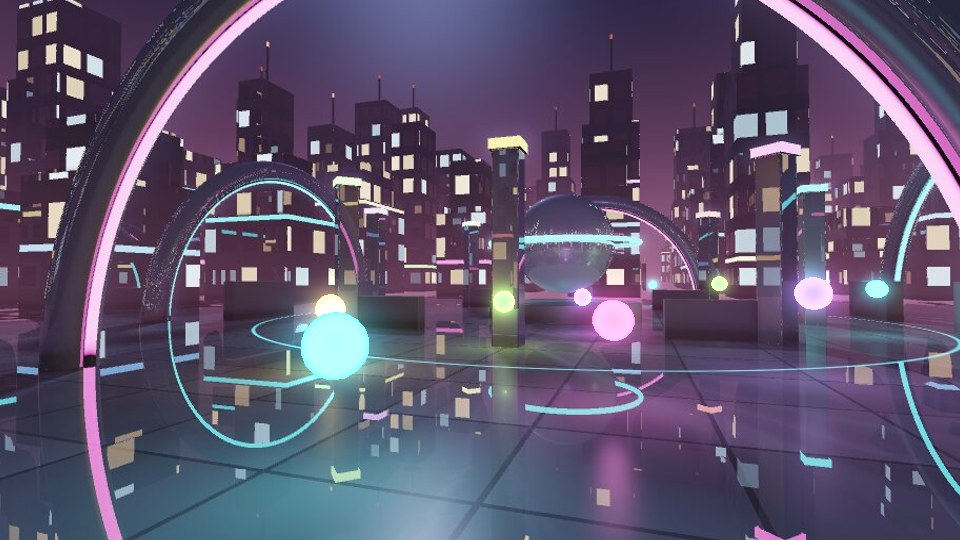

**Conventional cloud gaming ships finished frames.** Every mouse movement waits for a full network round trip,
a render, an encode and a decode before it becomes visible, so responsiveness can never be better than
the network.

**ShellStream inverts the pipeline.** The two T4s don't render *your frame*. They render a **shell**: a
wide-field, depth-carrying, topology-annotated, two-layer representation of the world around your
*predicted* position, valid for a whole neighbourhood of future viewpoints. The browser owns the camera,
the game logic and the final image. On every display refresh it re-projects the newest shell with the
camera pose sampled microseconds earlier. Looking, moving, jumping and picking things up become **local**
operations (about one display frame of latency, whatever the RTT). The network only decides how *fresh*
lighting and distant content are, and the human visual system is far more tolerant of that.

This notebook is the complete, runnable proof of concept:

| Part | What it is |
|---|---|
| `kernel.cu` | one source, two targets: an NVRTC/CUDA sphere-tracing renderer for the T4s, and the same code built with g++/OpenMP as a CPU fallback and test oracle |
| `engine.py` | shell planning (pose prediction, adaptive guard band, resolution budget), dual-GPU split-frame scheduling, nvJPEG / lossless geometry codecs |
| `server.py` | Tornado WebSocket server, ack-based flow control, event-driven updates, built-in network emulation |
| `client/` | WebGL2 browser client: topology-aware mesh warp, background layer, omni fallback, client-authoritative physics, local dynamic objects |


**Key results (development run; see the report for method and caveats)**

| | ShellStream | classic cloud streaming |
|---|---|---|
| look latency, input to finished frame, RTT 0 to 200 ms | **53-57 ms, flat** (= one frame of the software-rendered test client; one display refresh on a real GPU) | 240 -> 414 ms, grows with RTT |
| view lag while turning through a 1 s network stall | **0.0 deg** | up to 67 deg |
| image after a 30-degree turn (PSNR vs. 16-spp truth) | **29.0 dB** (local 1-spp render: 29.7) | 12.5 dB (stale frame) |
| image after a 0.5 m strafe | **25.7 dB** with both T4s (19.7 with one shell; naive depth warp 19.1) | 13.8 dB |
| inside regions newly revealed by a 0.5 m strafe | **22.5 dB** both T4s (16.0 one shell; naive 12.8, no band 9.8) | 10.7 dB |
| **any unmodified game** (Minetest via the game host): mouse-look latency, RTT 0 to 200 ms | **12-15 ms** with input-predicted reprojection (lower than the row above only because this client draws a single textured quad, which software rendering finishes sooner) | 117-329 ms |
| T4 time per update (modelled; measured by the notebook) | 11.2 ms on 2 T4s (22.3 on one) | 37.9 ms per 1080p frame on one T4 |
| bytes per update, 1080p client | 367 KiB (JPEG; about 4x less colour with NVENC-class video) | 193 KiB |

Under translation the gap to a local render is still large. Wet-floor mirror reflections explain much
of it for small moves (a reflection ablation is in the report); the rest is open. For closed games, only
mouse-look is predicted; movement and actions still take the round trip. T4 timings are modelled here and
measured by the notebook.


**How to use it:** run the cells top to bottom. Sections 1 to 3 (bring-up, T4 benchmarks, analysis) need no
network exposure. Section 5 (playing it in your own browser) is **opt-in**: read the policy note first.

## 0. Kaggle usage and policy note

Kaggle's GPUs are provided for data-science and machine-learning work under Kaggle's Terms of Use and
Acceptable Use Policy. Secondary sources quote these as limiting use to *"internal, personal, non-commercial
use, and not on behalf of or for the benefit of any third party"* and as listing *"server farming"* and
*"activity unrelated to ML data science"* among prohibited uses. Kaggle has also blocked SSH or
remote-desktop tunnelling into kernels in the past. **Read [kaggle.com/terms](https://www.kaggle.com/terms)
yourself before section 5.** This notebook was designed accordingly:

* **Default mode (sections 1 to 4) is a self-contained benchmark.** It renders, encodes and measures on the
  T4s and reports numbers. No ports are exposed and no third party is served.
* **Interactive play (section 5) is off by default.** It needs a public tunnel, because Kaggle kernels
  accept no inbound connections. Turning it on means exposing a web endpoint from the kernel, which may
  conflict with the terms above. If you enable it at all, keep it for your own short personal sessions,
  never share the URL, and stop it when you're done.
* **The same code runs unchanged on any CUDA machine with T4s** (for example a cloud VM with 2x T4:
  `python shellstream/server.py --address 0.0.0.0`). That is the right home for anything beyond a personal
  experiment.

In [ ]:
# ---- settings -----------------------------------------------------------------------------
RUN_BENCHMARKS      = True    # section 2: per-pass and end-to-end timings on the T4s
RUN_SHOWCASE        = True    # section 1: render and visualise one shell
START_LOCAL_SERVER  = False   # section 5: start the WebSocket server inside this kernel (localhost only)
OPEN_PUBLIC_TUNNEL  = False   # section 5: expose it through a Cloudflare quick tunnel (read section 0 first)
REPRODUCE_BROWSER_EXPERIMENTS = False   # section 4: installs Chromium + Playwright and re-runs the client experiments

import os, sys, json, time, math, subprocess, platform
WORK = '/kaggle/working' if os.path.isdir('/kaggle/working') else os.getcwd()
ROOT = os.path.join(WORK, 'shellstream')
os.makedirs(os.path.join(ROOT, 'client'), exist_ok=True)
os.makedirs(os.path.join(ROOT, 'bench'), exist_ok=True)
os.makedirs(os.path.join(ROOT, 'results'), exist_ok=True)
print('working directory:', ROOT)

In [ ]:
# ---- environment probe (installs only what is missing) --------------------------------------
def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    return (r.stdout + r.stderr).strip()

print(platform.platform(), '| python', platform.python_version(), '| cpus', os.cpu_count())
print(sh('nvidia-smi --query-gpu=index,name,memory.total,clocks.max.sm,power.limit --format=csv,noheader') or 'no NVIDIA GPU visible')

def ensure(mod, pipname):
    try:
        __import__(mod); return True
    except Exception:
        print('installing', pipname, '...'); print(sh(f'{sys.executable} -m pip install -q {pipname}')[-300:])
        try:
            __import__(mod); return True
        except Exception as e:
            print('  unavailable:', e); return False

HAS_GPU = 'NVIDIA' in sh('nvidia-smi -L') or 'Tesla' in sh('nvidia-smi -L')
if HAS_GPU:
    ensure('cupy', 'cupy-cuda12x')
ensure('tornado', 'tornado')
for mod, pipname in [('simplejpeg', 'simplejpeg')]:
    ensure(mod, pipname)
try:
    import torch, torchvision
    print('torch', torch.__version__, '| torchvision', torchvision.__version__, '| cuda devices', torch.cuda.device_count())
except Exception as e:
    print('torch/torchvision not available (CPU JPEG path will be used):', e)

## 1. The system

```
   T4 #0 ──────────────┐                        browser (any GPU, even a phone)
   focus colour, top   │                         every display refresh (60-240 Hz):
                       │  ┌────────────────┐       1. sample mouse/keys (late-latched)
   T4 #1 ──────────────┼─▶│ shell message  │──WS──▶ 2. simulate locally (collision vs streamed SDF brick)
   focus colour, bottom│  │ jpeg + inverse │       3. re-project newest shell with *current* camera:
   focus geometry+topo │  │ depth + topo + │          omni (fallback) -> background band -> focus
   background band     │  │ SDF brick      │       4. draw local dynamic objects (orbs) with depth test
   omni cube (6 faces) │  └────────────────┘       5. send pose, velocity, angular rate, light list
   collision brick ────┘         ▲                          │
                                 └── predicted pose, guard band, lights ◀──┘
```

* **Focus layer.** A perspective view centred on the *predicted* view direction. Its field of view is
  widened by a guard band that grows with angular velocity x latency, inside a fixed pixel budget, so
  resolution concentrates where the eye will be and drops during fast turns, when motion blur hides it.
* **Geometry and topology.** Per geometry texel: 16-bit inverse view-z (affine in screen space for planes,
  so 2nd-order prediction makes planes cost ~0 bits), and 3 *connectivity bits* computed on the GPU from
  exact hit positions and normals. The client's mesh tears exactly at true occlusion boundaries, never
  across creases or grazing planes.
* **Background band (2-layer LDI).** For texels within a *motion-predicted* distance of an occlusion edge,
  T4 #1 traces through the occluder to the surface behind it. Disocclusions get real pixels, not smears,
  and the band costs a small fraction of a full second layer.
* **Omni cube.** A low-resolution 360-degree layer with depth, so even a 180-degree flick never shows a hole.
* **Client-authoritative play.** The client simulates movement and collision against a streamed signed-distance
  brick, and owns dynamic objects. Their *light* goes back to the server (a latency-tolerant channel); the
  objects themselves are drawn locally (latency-critical).

In [ ]:
os.makedirs(os.path.join(ROOT, 'client'), exist_ok=True)

In [ ]:
%%writefile {ROOT}/kernel.cu
// =====================================================================================
//  ShellStream renderer kernel  -- one source, two targets
//
//  * NVRTC / CUDA  (Kaggle T4, sm_75): compiled at runtime by CuPy RawModule
//  * g++ / OpenMP  (any CPU)         : compiled with -DSS_CPU into a shared library
//
//  The renderer is a sphere-traced signed-distance-field city ("Neon Plaza") with
//  soft shadows, ambient occlusion, mirror/wet-floor reflections, 24 dynamic point
//  lights and volumetric neon glow.  It does NOT render "a frame".  It renders
//  *views of a shell*: arbitrary sets of (possibly asymmetric) perspective views packed
//  into an atlas, plus per-texel geometry (inverse depth + exact normal), from which a
//  topology (connectivity) map is derived.  A second-hit "background" layer is traced
//  only inside a motion-predicted disocclusion band.
// =====================================================================================

#if defined(__CUDACC__) || defined(__CUDACC_RTC__)
  #define SS_GPU 1
  #define HD __device__ __forceinline__
  #define KERNEL extern "C" __global__
#else
  #include <math.h>
  #include <string.h>
  #define HD static inline
#endif

typedef unsigned char  u8;
typedef unsigned short u16;
typedef unsigned int   u32;

// ------------------------------------------------------------------ parameter layout
#define NV_MAX        8
#define NL_MAX        24
#define P_HDR         32
#define P_VSTRIDE     24
#define P_LIGHT0      (P_HDR + NV_MAX * P_VSTRIDE)      // 224
#define P_LSTRIDE     8
#define P_TOTAL       (P_LIGHT0 + NL_MAX * P_LSTRIDE)   // 416

#define H_TIME        0
#define H_NVIEWS      1
#define H_NLIGHTS     2
#define H_FLAGS       3
#define H_ZNEAR       4
#define H_STEPS       5
#define H_BAND_DELTA  6     // expected camera translation (m) used to size the disocclusion band
#define H_SHADOW_ST   7
#define H_REFL_ST     8
#define H_MAXDIST     9
#define H_SUN         10    // 10,11,12
#define H_SPP         13    // colour samples per pixel (1, 2 or 4, rotated grid)

#define F_SHADOW      1
#define F_AO          2
#define F_REFL        4
#define F_GLOW        8

#define MODE_COLOR    1     // write rgb
#define MODE_GEO      2     // write depth code + geo (t, normal)
#define MODE_BACK     4     // background (second surface) layer, uses prepass geo
#define MODE_GEOONLY  8     // skip shading

// depth code: 0 = sky / infinity, 1 = invalid (no data), 2..65535 = inverse view-z (z_near / z)
#define DC_SKY        0
#define DC_INVALID    1

// ------------------------------------------------------------------ small vector library
struct V3 { float x, y, z; };
HD V3 v3(float x, float y, float z) { V3 r; r.x = x; r.y = y; r.z = z; return r; }
HD V3 v3s(float s) { return v3(s, s, s); }
HD V3 operator+(V3 a, V3 b) { return v3(a.x + b.x, a.y + b.y, a.z + b.z); }
HD V3 operator-(V3 a, V3 b) { return v3(a.x - b.x, a.y - b.y, a.z - b.z); }
HD V3 operator-(V3 a) { return v3(-a.x, -a.y, -a.z); }
HD V3 operator*(V3 a, float s) { return v3(a.x * s, a.y * s, a.z * s); }
HD V3 operator*(float s, V3 a) { return v3(a.x * s, a.y * s, a.z * s); }
HD V3 operator*(V3 a, V3 b) { return v3(a.x * b.x, a.y * b.y, a.z * b.z); }
HD V3 operator/(V3 a, float s) { float i = 1.0f / s; return a * i; }
HD float dot(V3 a, V3 b) { return a.x * b.x + a.y * b.y + a.z * b.z; }
HD V3 cross(V3 a, V3 b) { return v3(a.y * b.z - a.z * b.y, a.z * b.x - a.x * b.z, a.x * b.y - a.y * b.x); }
HD float length(V3 a) { return sqrtf(dot(a, a)); }
HD V3 normalize(V3 a) { return a * (1.0f / sqrtf(fmaxf(dot(a, a), 1e-20f))); }
HD float clampf(float x, float a, float b) { return fminf(fmaxf(x, a), b); }
HD float sat(float x) { return clampf(x, 0.0f, 1.0f); }
HD float mixf(float a, float b, float t) { return a + (b - a) * t; }
HD V3 mix(V3 a, V3 b, float t) { return a + (b - a) * t; }
HD V3 vabs(V3 a) { return v3(fabsf(a.x), fabsf(a.y), fabsf(a.z)); }
HD V3 vmaxs(V3 a, float s) { return v3(fmaxf(a.x, s), fmaxf(a.y, s), fmaxf(a.z, s)); }
HD float smoothstepf(float a, float b, float x) { float t = sat((x - a) / (b - a)); return t * t * (3.0f - 2.0f * t); }
HD float fractf(float x) { return x - floorf(x); }
HD V3 reflect3(V3 i, V3 n) { return i - n * (2.0f * dot(n, i)); }

// ------------------------------------------------------------------ hashing / noise
HD u32 hash2i(int x, int y) {
    u32 h = (u32)x * 0x8da6b343u ^ (u32)y * 0xd8163841u;
    h ^= h >> 15; h *= 0x2c1b3c6du; h ^= h >> 12; h *= 0x297a2d39u; h ^= h >> 15;
    return h;
}
HD float h01(u32 h, int k) {
    h ^= (u32)k * 0x9E3779B9u; h ^= h >> 16; h *= 0x7feb352du; h ^= h >> 15; h *= 0x846ca68bu; h ^= h >> 16;
    return (float)(h & 0xFFFFFFu) * (1.0f / 16777216.0f);
}
HD float vnoise(float x, float y) {
    float fx = floorf(x), fy = floorf(y);
    int ix = (int)fx, iy = (int)fy;
    float ux = x - fx, uy = y - fy;
    ux = ux * ux * (3.0f - 2.0f * ux); uy = uy * uy * (3.0f - 2.0f * uy);
    float a = h01(hash2i(ix, iy), 7), b = h01(hash2i(ix + 1, iy), 7);
    float c = h01(hash2i(ix, iy + 1), 7), d = h01(hash2i(ix + 1, iy + 1), 7);
    return mixf(mixf(a, b, ux), mixf(c, d, ux), uy);
}

// ------------------------------------------------------------------ SDF primitives
HD float sdBox(V3 p, V3 b) {
    V3 q = vabs(p) - b;
    return length(vmaxs(q, 0.0f)) + fminf(fmaxf(q.x, fmaxf(q.y, q.z)), 0.0f);
}
HD float sdTorusZ(V3 p, float R, float r) {   // ring in the XY plane
    float qx = sqrtf(p.x * p.x + p.y * p.y) - R;
    return sqrtf(qx * qx + p.z * p.z) - r;
}
HD float sdTorusY(V3 p, float R, float r) {   // ring in the XZ plane
    float qx = sqrtf(p.x * p.x + p.z * p.z) - R;
    return sqrtf(qx * qx + p.y * p.y) - r;
}
HD float sdCylY(V3 p, float r, float h) {     // capped cylinder, centred at origin
    float dx = sqrtf(p.x * p.x + p.z * p.z) - r, dy = fabsf(p.y) - h;
    return fminf(fmaxf(dx, dy), 0.0f) + sqrtf(fmaxf(dx, 0.0f) * fmaxf(dx, 0.0f) + fmaxf(dy, 0.0f) * fmaxf(dy, 0.0f));
}

// ------------------------------------------------------------------ the world
#define CELL      14.0f
#define CITY_N    11
#define MAXHALF   5.0f
#define MAXH      44.0f
#define PLAZA     21.0f

// materials
#define M_SKY     0
#define M_FLOOR   1
#define M_BUILD   2
#define M_CHROME  3
#define M_STONE   4
#define M_METAL   5
#define M_NEON    6      // + 16*colour
#define M_ANTENNA 7

HD bool isPlazaCell(int i, int j) { return i >= -1 && i <= 1 && j >= -1 && j <= 1; }

HD void buildingDims(int i, int j, float& hx, float& hz, float& H1, float& H2, float& s2) {
    u32 h = hash2i(i, j);
    hx = 2.6f + 2.3f * h01(h, 1);
    hz = 2.6f + 2.3f * h01(h, 2);
    float r = h01(h, 3);
    float hh = 7.0f + 30.0f * r * r;
    H1 = hh * (0.45f + 0.35f * h01(h, 4));
    H2 = hh - H1;
    s2 = 0.55f + 0.35f * h01(h, 5);
}

HD V3 neonColor(int c) {
    c = c & 7;
    if (c == 0) return v3(0.10f, 0.85f, 1.00f);
    if (c == 1) return v3(1.00f, 0.15f, 0.65f);
    if (c == 2) return v3(1.00f, 0.55f, 0.10f);
    if (c == 3) return v3(0.45f, 1.00f, 0.25f);
    if (c == 4) return v3(0.65f, 0.30f, 1.00f);
    if (c == 5) return v3(1.00f, 0.90f, 0.35f);
    if (c == 6) return v3(0.20f, 0.45f, 1.00f);
    return v3(1.00f, 0.30f, 0.25f);
}

// Plaza: monument (chrome sphere, pedestal, neon ring), 4 arches with neon tubes,
// 8 pillars with neon caps, low walls (cover / parallax test objects).
template <bool M>
HD float mapPlaza(V3 p, int& m, float& glow) {
    float d = 1e9f;
    // monument
    {
        V3 q = p - v3(0.0f, 3.3f, 0.0f);
        float ds = length(q) - 2.2f;
        if (ds < d) { d = ds; if (M) m = M_CHROME; }
        float dp = sdCylY(p - v3(0.0f, 0.35f, 0.0f), 3.3f, 0.35f);
        if (dp < d) { d = dp; if (M) m = M_STONE; }
        float dr = sdTorusY(q, 3.25f, 0.10f);
        glow = fminf(glow, dr);
        if (dr < d) { d = dr; if (M) m = M_NEON + 16 * 0; }
    }
    // four arches (two along x, two along z)
    {
        V3 a = v3(p.x, p.y, fabsf(p.z) - 15.0f);      // arches at z = +-15 (ring in XY)
        float dt = sdTorusZ(a, 7.5f, 0.45f);
        dt = fmaxf(dt, -p.y);
        if (dt < d) { d = dt; if (M) m = M_METAL; }
        float dn = sdTorusZ(a - v3(0.0f, 0.0f, 0.0f), 6.95f, 0.09f);
        dn = fmaxf(dn, -p.y);
        glow = fminf(glow, dn);
        if (dn < d) { d = dn; if (M) m = M_NEON + 16 * 1; }
        V3 b = v3(fabsf(p.x) - 15.0f, p.y, p.z);      // arches at x = +-15 (ring in ZY)
        V3 bz = v3(b.z, b.y, b.x);
        float dt2 = fmaxf(sdTorusZ(bz, 7.5f, 0.45f), -p.y);
        if (dt2 < d) { d = dt2; if (M) m = M_METAL; }
        float dn2 = fmaxf(sdTorusZ(bz, 6.95f, 0.09f), -p.y);
        glow = fminf(glow, dn2);
        if (dn2 < d) { d = dn2; if (M) m = M_NEON + 16 * 0; }
    }
    // eight pillars on a circle of radius 9.5 (polar repetition)
    {
        float ang = atan2f(p.z, p.x);
        float sector = 6.2831853f / 8.0f;
        float k = floorf(ang / sector + 0.5f);
        float a2 = k * sector;
        float c = cosf(a2), s = sinf(a2);
        V3 q = v3(c * p.x + s * p.z - 9.5f, p.y, -s * p.x + c * p.z);
        float dpil = sdBox(q - v3(0.0f, 2.5f, 0.0f), v3(0.32f, 2.5f, 0.32f)) - 0.03f;
        if (dpil < d) { d = dpil; if (M) m = M_METAL; }
        float dcap = sdBox(q - v3(0.0f, 5.15f, 0.0f), v3(0.42f, 0.13f, 0.42f));
        glow = fminf(glow, dcap);
        if (dcap < d) { d = dcap; if (M) { int ci = ((int)k + 8) & 7; m = M_NEON + 16 * ci; } }
    }
    // low walls (cover)
    {
        V3 q = v3(fabsf(p.x) - 5.5f, p.y - 0.55f, fabsf(p.z) - 6.5f);
        float dw = sdBox(q, v3(1.6f, 0.55f, 0.22f)) - 0.02f;
        if (dw < d) { d = dw; if (M) m = M_STONE; }
        V3 r = v3(fabsf(p.x) - 13.0f, p.y - 0.8f, fabsf(p.z) - 4.0f);
        float dw2 = sdBox(r, v3(0.25f, 0.8f, 1.8f)) - 0.02f;
        if (dw2 < d) { d = dw2; if (M) m = M_STONE; }
    }
    return d;
}

template <bool M>
HD float mapCity(V3 p, int& m, int& ci, int& cj) {
    float fi = floorf(p.x / CELL + 0.5f), fj = floorf(p.z / CELL + 0.5f);
    int i = (int)fi, j = (int)fj;
    float qx = p.x - fi * CELL, qz = p.z - fj * CELL;
    // conservative bound to buildings in neighbouring cells
    float bound = fminf(CELL * 0.5f - fabsf(qx), CELL * 0.5f - fabsf(qz)) + (CELL * 0.5f - MAXHALF);
    bound = fmaxf(bound, p.y - MAXH);
    // outside the city footprint: distance to the city's bounding box
    float ext = (CITY_N + 0.5f) * CELL;
    float outside = fmaxf(fabsf(p.x) - ext, fabsf(p.z) - ext);
    bound = fmaxf(bound, outside);
    float d = bound;
    if (!isPlazaCell(i, j) && i >= -CITY_N && i <= CITY_N && j >= -CITY_N && j <= CITY_N) {
        float hx, hz, H1, H2, s2;
        buildingDims(i, j, hx, hz, H1, H2, s2);
        V3 q = v3(qx, p.y, qz);
        float d1 = sdBox(q - v3(0.0f, H1 * 0.5f, 0.0f), v3(hx, H1 * 0.5f, hz)) - 0.05f;
        float d2 = sdBox(q - v3(0.0f, H1 + H2 * 0.5f, 0.0f), v3(hx * s2, H2 * 0.5f, hz * s2)) - 0.05f;
        float db = fminf(d1, d2);
        float H = H1 + H2;
        if (H > 24.0f) {   // antenna on tall towers
            float da = sdCylY(q - v3(0.0f, H + 3.0f, 0.0f), 0.12f, 3.0f);
            if (da < db) { db = da; if (M) m = M_ANTENNA; }
            else if (M) m = M_BUILD;
        } else if (M) m = M_BUILD;
        if (db < d) { d = db; } else if (M) m = M_SKY;
        if (M) { ci = i; cj = j; }
    } else if (M) m = M_SKY;
    return d;
}

// full scene.  M: also return material.  G: track minimum distance to neon emitters (glow)
#if defined(SS_COUNT) && !defined(SS_GPU)
#include <omp.h>
static unsigned long long g_evals[256];
#define COUNT_EVAL() (g_evals[omp_get_thread_num() & 255]++)
extern "C" unsigned long long ss_evals() { unsigned long long s = 0; for (int i = 0; i < 256; i++) s += g_evals[i]; return s; }
extern "C" void ss_evals_reset() { memset(g_evals, 0, sizeof(g_evals)); }
#else
#define COUNT_EVAL()
#endif

template <bool M>
HD float map(V3 p, int& m, int& ci, int& cj, float& glow) {
    COUNT_EVAL();
    float d = p.y;                                   // ground
    if (M) m = M_FLOOR;
    int mc = M_SKY;
    float dc = mapCity<M>(p, mc, ci, cj);
    if (dc < d) { d = dc; if (M) m = mc; }
    if (fabsf(p.x) < PLAZA && fabsf(p.z) < PLAZA && p.y < 12.0f) {
        int mp = M_SKY;
        float dp = mapPlaza<M>(p, mp, glow);
        if (dp < d) { d = dp; if (M) m = mp; }
    } else {
        float bx = fmaxf(fabsf(p.x) - PLAZA, fabsf(p.z) - PLAZA);
        bx = fmaxf(bx, p.y - 12.0f);
        glow = fminf(glow, bx + 1.0f);
    }
    return d;
}

HD float mapD(V3 p) { int m, ci, cj; float g = 1e9f; return map<false>(p, m, ci, cj, g); }

HD V3 calcNormal(V3 p, float t) {
    float e = 0.0006f + 0.00035f * t;
    // tetrahedron technique: 4 evaluations
    V3 k0 = v3(1, -1, -1), k1 = v3(-1, -1, 1), k2 = v3(-1, 1, -1), k3 = v3(1, 1, 1);
    V3 n = k0 * mapD(p + k0 * e) + k1 * mapD(p + k1 * e) + k2 * mapD(p + k2 * e) + k3 * mapD(p + k3 * e);
    return normalize(n);
}

// sphere tracing.  returns t (or -1 on miss); accumulates neon glow if glowAcc != 0
HD float march(V3 ro, V3 rd, float tmin, float tmax, int steps, float* glowAcc) {
    float t = tmin;
    for (int i = 0; i < steps; i++) {
        V3 p = ro + rd * t;
        int m, ci, cj; float g = 1e9f;
        float d = map<false>(p, m, ci, cj, g);
        if (glowAcc) *glowAcc += expf(-g * 5.0f) * fminf(d, 0.6f);
        if (d < 0.0004f * t + 0.0015f) return t;
        t += d;
        if (t > tmax) break;
    }
    return -1.0f;
}

HD float softShadow(V3 ro, V3 rd, float tmin, float tmax, float k, int steps) {
    float res = 1.0f, t = tmin;
    for (int i = 0; i < steps; i++) {
        float h = mapD(ro + rd * t);
        res = fminf(res, k * h / t);
        t += clampf(h, 0.03f, 3.0f);
        if (res < 0.003f || t > tmax) break;
    }
    return sat(res);
}

HD float calcAO(V3 p, V3 n) {
    float occ = 0.0f, sca = 1.0f;
    for (int i = 0; i < 5; i++) {
        float h = 0.03f + 0.16f * (float)i;
        float d = mapD(p + n * h);
        occ += (h - d) * sca;
        sca *= 0.82f;
    }
    return sat(1.0f - 2.2f * occ);
}

// ------------------------------------------------------------------ lighting
HD V3 sunDir(const float* P) { return normalize(v3(P[H_SUN], P[H_SUN + 1], P[H_SUN + 2])); }

HD V3 skyColor(V3 rd, const float* P) {
    float h = rd.y;
    V3 top = v3(0.008f, 0.012f, 0.035f), hor = v3(0.30f, 0.13f, 0.22f), below = v3(0.02f, 0.02f, 0.03f);
    V3 c;
    if (h > 0.0f) c = mix(hor, top, powf(fminf(h * 2.0f, 1.0f), 0.55f));
    else c = mix(hor, below, fminf(-h * 6.0f, 1.0f));
    V3 sd = sunDir(P);
    float mu = fmaxf(dot(rd, sd), 0.0f);
    c = c + v3(0.95f, 0.97f, 1.0f) * (smoothstepf(0.99930f, 0.99955f, mu) * 2.5f);
    c = c + v3(0.18f, 0.22f, 0.40f) * (powf(mu, 48.0f) * 0.6f);
    return c;
}

struct Mat { V3 alb; V3 emis; float rough; float refl; };

HD Mat material(V3 p, V3 n, int m, int ci, int cj, const float* P) {
    Mat r; r.alb = v3s(0.5f); r.emis = v3s(0.0f); r.rough = 0.6f; r.refl = 0.0f;
    float time = P[H_TIME];
    if (m == M_FLOOR) {
        bool plaza = fabsf(p.x) < PLAZA && fabsf(p.z) < PLAZA;
        if (plaza) {
            float tx = fractf(p.x * 0.5f), tz = fractf(p.z * 0.5f);
            float grout = (tx < 0.03f || tz < 0.03f) ? 0.55f : 1.0f;
            u32 th = hash2i((int)floorf(p.x * 0.5f), (int)floorf(p.z * 0.5f));
            float v = 0.85f + 0.3f * h01(th, 3);
            r.alb = v3(0.20f, 0.20f, 0.22f) * (grout * v);
            float rr = length(v3(p.x, 0.0f, p.z));
            float ringl = smoothstepf(0.08f, 0.0f, fabsf(rr - 12.5f));     // inlaid light ring
            r.emis = v3(0.1f, 0.7f, 1.0f) * (ringl * 1.6f);
            r.refl = 0.35f; r.rough = 0.25f;
        } else {
            r.alb = v3(0.055f, 0.055f, 0.065f);
            // dashed lane lines on street centres
            float sx = fabsf(fractf(p.x / CELL) - 0.5f) * CELL;   // distance to street centre line x = (i+.5)CELL
            float sz = fabsf(fractf(p.z / CELL) - 0.5f) * CELL;
            float dashz = fractf(p.z * 0.25f) < 0.5f ? 1.0f : 0.0f;
            float dashx = fractf(p.x * 0.25f) < 0.5f ? 1.0f : 0.0f;
            float line = fmaxf((sx < 0.08f ? dashz : 0.0f), (sz < 0.08f ? dashx : 0.0f));
            r.alb = mix(r.alb, v3(0.55f, 0.45f, 0.12f), line);
            float w = vnoise(p.x * 0.35f, p.z * 0.35f) * 0.65f + vnoise(p.x * 1.3f, p.z * 1.3f) * 0.35f;
            float wet = smoothstepf(0.48f, 0.56f, w);
            r.refl = mixf(0.08f, 0.75f, wet);
            r.rough = mixf(0.6f, 0.03f, wet);
            r.alb = r.alb * mixf(1.0f, 0.5f, wet);
        }
    } else if (m == M_BUILD) {
        u32 bh = hash2i(ci, cj);
        V3 base = mix(v3(0.10f, 0.11f, 0.14f), v3(0.20f, 0.18f, 0.17f), h01(bh, 9));
        r.alb = base; r.rough = 0.7f; r.refl = 0.0f;
        float u = fabsf(n.x) > 0.5f ? p.z : p.x;
        float v = p.y;
        if (fabsf(n.y) < 0.5f) {
            float fx = u / 2.2f, fy = v / 3.3f;
            int wx = (int)floorf(fx), wy = (int)floorf(fy);
            float lx = fx - floorf(fx), ly = fy - floorf(fy);
            bool win = lx > 0.14f && lx < 0.86f && ly > 0.22f && ly < 0.82f && v > 1.2f;
            u32 wh = hash2i(wx * 131 + ci * 7, wy * 17 + cj * 13);
            if (win) {
                float lit = h01(wh, 11);
                if (lit < 0.34f) {
                    V3 wc = h01(wh, 12) < 0.6f ? v3(1.0f, 0.72f, 0.42f) : v3(0.55f, 0.80f, 1.0f);
                    r.emis = wc * (0.6f + 1.4f * h01(wh, 13));
                    r.alb = v3s(0.02f);
                } else {
                    r.alb = v3(0.03f, 0.035f, 0.05f); r.refl = 0.35f; r.rough = 0.08f;
                }
            }
            int band = 1 + (int)(h01(bh, 14) * 4.0f);
            if (wy == band && ly < 0.12f) {
                float pulse = 0.85f + 0.15f * sinf(time * 1.5f + (float)ci);
                r.emis = neonColor((int)(h01(bh, 15) * 8.0f)) * (3.0f * pulse);
                r.alb = v3s(0.02f);
            }
        }
    } else if (m == M_CHROME) {
        r.alb = v3(0.75f, 0.78f, 0.82f); r.refl = 0.85f; r.rough = 0.02f;
    } else if (m == M_STONE) {
        r.alb = v3(0.28f, 0.27f, 0.26f); r.rough = 0.85f;
    } else if (m == M_METAL) {
        r.alb = v3(0.35f, 0.37f, 0.42f); r.refl = 0.3f; r.rough = 0.25f;
    } else if (m == M_ANTENNA) {
        r.alb = v3s(0.08f); r.rough = 0.5f;
        float blink = sinf(time * 3.0f + (float)(ci * 3 + cj)) > 0.2f ? 1.0f : 0.15f;
        float H1, H2, hx, hz, s2; buildingDims(ci, cj, hx, hz, H1, H2, s2);
        if (p.y > H1 + H2 + 5.4f) r.emis = v3(1.0f, 0.1f, 0.05f) * (6.0f * blink);   // tip light
    } else if (m >= M_NEON) {
        int c = (m - M_NEON) / 16;
        float pulse = 0.9f + 0.1f * sinf(time * 2.0f + (float)c * 1.7f);
        r.emis = neonColor(c) * (4.0f * pulse);
        r.alb = v3s(0.05f);
    }
    return r;
}

// direct + ambient lighting for a surface point.  full = primary-quality shading
HD V3 lightSurface(V3 p, V3 n, V3 rd, const Mat& mt, const float* P, bool full) {
    int flags = (int)P[H_FLAGS];
    V3 col = v3s(0.0f);
    V3 sd = sunDir(P);
    float ndl = dot(n, sd);
    // moon
    if (ndl > 0.0f) {
        float sh = 1.0f;
        if (full && (flags & F_SHADOW)) sh = softShadow(p + n * 0.01f, sd, 0.02f, 80.0f, 10.0f, (int)P[H_SHADOW_ST]);
        V3 h = normalize(sd - rd);
        float spec = powf(sat(dot(n, h)), mixf(256.0f, 8.0f, mt.rough)) * (1.0f - mt.rough) * 2.0f;
        col = col + v3(0.34f, 0.40f, 0.58f) * (ndl * sh) * (mt.alb + v3s(spec));
    }
    // hemispherical ambient
    float occ = (full && (flags & F_AO)) ? calcAO(p, n) : 1.0f;
    V3 amb = mix(v3(0.05f, 0.035f, 0.05f), v3(0.07f, 0.08f, 0.14f), n.y * 0.5f + 0.5f);
    col = col + mt.alb * amb * occ;
    // point lights (static plaza lights + client-side dynamic objects)
    int nl = (int)P[H_NLIGHTS];
    for (int i = 0; i < nl; i++) {
        const float* L = P + P_LIGHT0 + i * P_LSTRIDE;
        V3 lp = v3(L[0], L[1], L[2]);
        V3 lc = v3(L[3], L[4], L[5]);
        float rad = L[6];
        V3 ld = lp - p;
        float d2 = dot(ld, ld);
        if (d2 > rad * rad) continue;
        float d = sqrtf(d2);
        V3 l = ld / fmaxf(d, 1e-4f);
        float nd = dot(n, l);
        if (nd <= 0.0f) continue;
        float x = d / rad; float win = sat(1.0f - x * x * x * x); win *= win;
        float att = win / (1.0f + d2);
        V3 h = normalize(l - rd);
        float spec = powf(sat(dot(n, h)), mixf(200.0f, 8.0f, mt.rough)) * (1.0f - mt.rough) * 3.0f;
        col = col + lc * (nd * att) * (mt.alb + v3s(spec));
    }
    col = col + mt.emis * occ;
    return col;
}

HD V3 applyFog(V3 col, V3 rd, float t, const float* P) {
    float fogAmt = 1.0f - expf(-t * 0.0065f);
    V3 fc = mix(v3(0.09f, 0.05f, 0.10f), v3(0.30f, 0.13f, 0.22f), sat(1.0f - fabsf(rd.y) * 4.0f));
    return mix(col, fc, fogAmt);
}

// shade a hit point (primary quality incl. one reflection bounce)
HD V3 shadeHit(V3 ro, V3 rd, float t, const float* P, V3* nOut) {
    V3 p = ro + rd * t;
    int m = M_SKY, ci = 0, cj = 0; float g = 1e9f;
    map<true>(p, m, ci, cj, g);
    V3 n = calcNormal(p, t);
    if (nOut) *nOut = n;
    Mat mt = material(p, n, m, ci, cj, P);
    V3 col = lightSurface(p, n, rd, mt, P, true);
    int flags = (int)P[H_FLAGS];
    if ((flags & F_REFL) && mt.refl > 0.02f) {
        V3 rr = reflect3(rd, n);
        float fres = mt.refl * (0.25f + 0.75f * powf(1.0f - sat(dot(-rd, n)), 3.0f));
        fres = fminf(fres + mt.refl * 0.3f, 1.0f);
        float t2 = march(p + n * 0.02f, rr, 0.02f, 160.0f, (int)P[H_REFL_ST], 0);
        V3 rc;
        if (t2 > 0.0f) {
            V3 p2 = p + n * 0.02f + rr * t2;
            int m2 = M_SKY, ci2 = 0, cj2 = 0; float g2 = 1e9f;
            map<true>(p2, m2, ci2, cj2, g2);
            V3 n2 = calcNormal(p2, t + t2);
            Mat mt2 = material(p2, n2, m2, ci2, cj2, P);
            rc = lightSurface(p2, n2, rr, mt2, P, false);
            rc = applyFog(rc, rr, t2, P);
        } else {
            rc = skyColor(rr, P);
        }
        // rough reflections are dimmer / blurrier: approximate by attenuation
        col = mix(col, rc * mix(v3s(1.0f), mt.alb * 1.5f + v3s(0.4f), mt.refl > 0.8f ? 0.3f : 0.0f), fres * (1.0f - 0.7f * mt.rough));
    }
    return applyFog(col, rd, t, P);
}

HD V3 tonemap(V3 c) {   // ACES (Narkowicz) + gamma
    V3 r;
    float a = 2.51f, b = 0.03f, cc = 2.43f, d = 0.59f, e = 0.14f;
    r.x = sat((c.x * (a * c.x + b)) / (c.x * (cc * c.x + d) + e));
    r.y = sat((c.y * (a * c.y + b)) / (c.y * (cc * c.y + d) + e));
    r.z = sat((c.z * (a * c.z + b)) / (c.z * (cc * c.z + d) + e));
    r.x = powf(r.x, 1.0f / 2.2f); r.y = powf(r.y, 1.0f / 2.2f); r.z = powf(r.z, 1.0f / 2.2f);
    return r;
}

// ------------------------------------------------------------------ views
struct View { V3 o, r, u, f; float l, rr, b, t; int x0, y0, w, h; };

HD View loadView(const float* P, int k) {
    const float* V = P + P_HDR + k * P_VSTRIDE;
    View v;
    v.o = v3(V[0], V[1], V[2]); v.r = v3(V[3], V[4], V[5]); v.u = v3(V[6], V[7], V[8]); v.f = v3(V[9], V[10], V[11]);
    v.l = V[12]; v.rr = V[13]; v.b = V[14]; v.t = V[15];
    v.x0 = (int)V[16]; v.y0 = (int)V[17]; v.w = (int)V[18]; v.h = (int)V[19];
    return v;
}
HD int findView(const float* P, int x, int y, View& v) {
    int nv = (int)P[H_NVIEWS];
    for (int k = 0; k < nv; k++) {
        v = loadView(P, k);
        if (x >= v.x0 && x < v.x0 + v.w && y >= v.y0 && y < v.y0 + v.h) return k;
    }
    return -1;
}
// un-normalised ray direction through texel centre (x,y) of view v (in tan space: dot(dir, f) == 1)
HD V3 viewRay(const View& v, float x, float y) {
    float sx = (x - (float)v.x0 + 0.5f) / (float)v.w;          // 0..1 left->right
    float sy = (y - (float)v.y0 + 0.5f) / (float)v.h;          // 0..1 top->bottom
    float tx = v.l + (v.rr - v.l) * sx;
    float ty = v.t + (v.b - v.t) * sy;
    return v.f + v.r * tx + v.u * ty;
}

// rotated-grid sub-pixel positions for 1 / 2 / 4 samples per pixel
HD void subpixel(int spp, int s, float& ox, float& oy) {
    if (spp > 4) {           // progressive refinement: R2 low-discrepancy sequence
        ox = fractf(0.5f + (float)s * 0.75487766624f);
        oy = fractf(0.5f + (float)s * 0.56984029099f);
    } else if (spp == 4) {   // RGSS: (3/8,1/8) (7/8,3/8) (1/8,5/8) (5/8,7/8) -- arithmetic, no local-memory table
        int k = s & 3;
        oy = 0.125f + 0.25f * (float)k;
        ox = k == 0 ? 0.375f : (k == 1 ? 0.875f : (k == 2 ? 0.125f : 0.625f));
    } else if (spp == 2) {
        ox = s ? 0.75f : 0.25f; oy = s ? 0.75f : 0.25f;
    } else { ox = 0.5f; oy = 0.5f; }
}

HD u16 encodeDepth(float z, float zn) {
    float u = zn / fmaxf(z, zn);
    int c = 2 + (int)(u * 65533.0f + 0.5f);
    return (u16)(c > 65535 ? 65535 : c);
}
HD float decodeU(u16 c) { return c < 2 ? 0.0f : (float)(c - 2) * (1.0f / 65533.0f); }   // = zn / z

// background-layer decision: should texel (x,y) carry the 2nd surface (2), the 1st (1) or nothing (0)?
HD int bandDecision(const float* P, const u16* pre, int W, int H, int x, int y, const View& v) {
    u16 c0 = pre[y * W + x];
    if (c0 == DC_INVALID) return 0;
    float u0 = decodeU(c0);
    float zn = P[H_ZNEAR];
    float delta = P[H_BAND_DELTA];
    float fpx = (float)v.w / (v.rr - v.l);          // pixels per unit tan
    // 8 directions x 13 geometrically growing radii (1,2,3,4,5,7,9,11,15,19,25,33,42 texels); computed, not tabled
    const int NR = 13;
    bool near1 = false;
    for (int dir = 0; dir < 8; dir++) {
        int dxi = (dir == 0 || dir == 1 || dir == 7) ? 1 : ((dir == 3 || dir == 4 || dir == 5) ? -1 : 0);
        int dyi = (dir == 1 || dir == 2 || dir == 3) ? 1 : ((dir == 5 || dir == 6 || dir == 7) ? -1 : 0);
        float inv = (dxi != 0 && dyi != 0) ? 0.70710678f : 1.0f;
        for (int k = 0; k < NR; k++) {
            float rad = k < 4 ? (float)(k + 1) : floorf(4.0f * powf(1.3f, (float)(k - 3)) + 0.5f);
            int qx = x + (int)floorf(rad * (float)dxi * inv + 0.5f);
            int qy = y + (int)floorf(rad * (float)dyi * inv + 0.5f);
            if (qx < v.x0 || qx >= v.x0 + v.w || qy < v.y0 || qy >= v.y0 + v.h) break;
            u16 cq = pre[qy * W + qx];
            if (cq == DC_INVALID) continue;
            float uq = decodeU(cq);
            float dist = rad;
            if (uq < u0 * 0.92f - 1e-5f) {
                // q is clearly farther: a disocclusion opens next to p, of width f * delta * (1/z_p - 1/z_q)
                float need = fpx * delta * (u0 - uq) / zn + 2.0f;
                if (dist <= need) return 2;
            } else if (uq > u0 * 1.08f + 1e-5f && dist <= 2.5f) {
                near1 = true;                   // p is background right next to a foreground edge
            }
        }
    }
    return near1 ? 1 : 0;
}

// ------------------------------------------------------------------ per-pixel entry
HD void renderPixel(const float* P, u8* rgb, u16* dcode, float* geo, const float* preGeo, const u16* preCode,
                    int W, int H, int mode, int x, int y) {
    int idx = y * W + x;
    View v;
    int k = findView(P, x, y, v);
    if (k < 0) {
        if (mode & MODE_COLOR) { rgb[idx * 3 + 0] = 0; rgb[idx * 3 + 1] = 0; rgb[idx * 3 + 2] = 0; }
        if (mode & MODE_GEO) { dcode[idx] = DC_INVALID; geo[idx * 4 + 0] = -1.0f; }
        return;
    }
    V3 dirU = viewRay(v, (float)x, (float)y);        // dot(dirU, f) == 1  ->  view-z = t / |dirU|
    float invLen = 1.0f / length(dirU);
    V3 rd = dirU * invLen;
    V3 ro = v.o;
    float zn = P[H_ZNEAR];
    float maxd = P[H_MAXDIST];
    int steps = (int)P[H_STEPS];
    int flags = (int)P[H_FLAGS];

    float t = -1.0f;
    float glowAcc = 0.0f;
    bool valid = true;

    // ---- plain colour passes: supersampled (rotated grid), geometry is not written here
    if ((mode & MODE_COLOR) && !(mode & (MODE_BACK | MODE_GEO))) {
        int spp = (int)P[H_SPP]; if (spp < 1) spp = 1;
        V3 acc = v3s(0.0f);
        for (int si = 0; si < spp; si++) {
            float ox, oy; subpixel(spp, si, ox, oy);
            V3 rds = normalize(viewRay(v, (float)x + ox - 0.5f, (float)y + oy - 0.5f));
            float g = 0.0f;
            float ts = march(ro, rds, zn, maxd, steps, (flags & F_GLOW) ? &g : 0);
            V3 c = ts > 0.0f ? shadeHit(ro, rds, ts, P, 0) : applyFog(skyColor(rds, P), rds, 40.0f, P);
            c = c + v3(0.35f, 0.55f, 1.0f) * (g * 0.05f) + v3(1.0f, 0.3f, 0.7f) * (g * 0.02f);
            acc = acc + tonemap(c);
        }
        acc = acc * (1.0f / (float)spp);
        rgb[idx * 3 + 0] = (u8)(acc.x * 255.0f + 0.5f);
        rgb[idx * 3 + 1] = (u8)(acc.y * 255.0f + 0.5f);
        rgb[idx * 3 + 2] = (u8)(acc.z * 255.0f + 0.5f);
        return;
    }

    if (mode & MODE_BACK) {
        int dec = bandDecision(P, preCode, W, H, x, y, v);
        float t1 = preGeo[idx * 4 + 0];
        if (dec == 0) { valid = false; }
        else if (dec == 1) { t = t1; }
        else {
            if (t1 <= 0.0f) { valid = false; }
            else {
                V3 p1 = ro + rd * t1;
                if (p1.y < 0.01f) valid = false;    // the ground has nothing behind it
                else {
                    // walk through the occluder ...
                    float tt = t1 + 0.01f + 0.002f * t1;
                    bool exited = false;
                    for (int i = 0; i < 96; i++) {
                        float d = mapD(ro + rd * tt);
                        if (d > 0.002f) { exited = true; break; }
                        tt += fmaxf(-d, 0.01f + 0.001f * tt);
                        if (tt > t1 + 60.0f) break;
                    }
                    // ... and find the surface behind it
                    if (exited) t = march(ro, rd, tt + 0.01f, maxd, steps, 0);
                    else valid = false;
                }
            }
        }
    } else {
        t = march(ro, rd, zn, maxd, steps, (flags & F_GLOW) && !(mode & MODE_GEOONLY) ? &glowAcc : 0);
    }

    V3 n = v3(0, 1, 0);
    V3 col = v3s(0.0f);
    if (!valid) {
        col = v3s(0.0f);
    } else if (t > 0.0f) {
        if (!(mode & MODE_GEOONLY) && (mode & MODE_COLOR)) col = shadeHit(ro, rd, t, P, &n);
        else n = calcNormal(ro + rd * t, t);
    } else {
        if (mode & MODE_COLOR) col = applyFog(skyColor(rd, P), rd, 40.0f, P);
    }
    if (mode & MODE_COLOR) {
        col = col + v3(0.35f, 0.55f, 1.0f) * (glowAcc * 0.05f) + v3(1.0f, 0.3f, 0.7f) * (glowAcc * 0.02f);
        V3 tm = tonemap(col);
        rgb[idx * 3 + 0] = (u8)(tm.x * 255.0f + 0.5f);
        rgb[idx * 3 + 1] = (u8)(tm.y * 255.0f + 0.5f);
        rgb[idx * 3 + 2] = (u8)(tm.z * 255.0f + 0.5f);
        if (!valid) { rgb[idx * 3 + 0] = 0; rgb[idx * 3 + 1] = 0; rgb[idx * 3 + 2] = 0; }
    }
    if (mode & MODE_GEO) {
        if (!valid) { dcode[idx] = DC_INVALID; geo[idx * 4 + 0] = -1.0f; }
        else if (t > 0.0f) {
            dcode[idx] = encodeDepth(t * invLen, zn);
            geo[idx * 4 + 0] = t; geo[idx * 4 + 1] = n.x; geo[idx * 4 + 2] = n.y; geo[idx * 4 + 3] = n.z;
        } else {
            dcode[idx] = DC_SKY;
            geo[idx * 4 + 0] = 0.0f;
        }
    }
}

// ------------------------------------------------------------------ topology (connectivity) map
// bit 0: texel connected to right neighbour, bit 1: to lower neighbour, bit 2: (x+1,y) <-> (x,y+1)
HD int connected(const View& v, const float* geo, int W, int ia, int ib, float xa, float ya, float xb, float yb) {
    float ta = geo[ia * 4], tb = geo[ib * 4];
    if (ta < 0.0f || tb < 0.0f) return 0;            // invalid
    if (ta == 0.0f && tb == 0.0f) return 1;          // sky - sky
    if (ta == 0.0f || tb == 0.0f) return 0;          // sky - surface
    V3 da = normalize(viewRay(v, xa, ya)), db = normalize(viewRay(v, xb, yb));
    V3 pa = v.o + da * ta, pb = v.o + db * tb;
    V3 na = v3(geo[ia * 4 + 1], geo[ia * 4 + 2], geo[ia * 4 + 3]);
    V3 nb = v3(geo[ib * 4 + 1], geo[ib * 4 + 2], geo[ib * 4 + 3]);
    V3 dd = pb - pa;
    float len = length(dd);
    float pix = (v.rr - v.l) / (float)v.w;           // texel size in tan units
    float foot = fmaxf(ta, tb) * pix;
    if (len < 2.5f * foot) return 1;                 // creases, tiny steps
    float pl = fmaxf(fabsf(dot(dd, na)), fabsf(dot(dd, nb)));
    return pl < 0.2f * len ? 1 : 0;                  // same (locally planar) surface
}

HD void connPixel(const float* P, const float* geo, u8* bits, int W, int H, int x, int y) {
    View v;
    int k = findView(P, x, y, v);
    u8 b = 0;
    if (k >= 0) {
        int i = y * W + x;
        bool hasR = x + 1 < v.x0 + v.w, hasD = y + 1 < v.y0 + v.h;
        if (hasR && connected(v, geo, W, i, i + 1, (float)x, (float)y, (float)(x + 1), (float)y)) b |= 1;
        if (hasD && connected(v, geo, W, i, i + W, (float)x, (float)y, (float)x, (float)(y + 1))) b |= 2;
        if (hasR && hasD && connected(v, geo, W, i + 1, i + W, (float)(x + 1), (float)y, (float)x, (float)(y + 1))) b |= 4;
    }
    bits[y * W + x] = b;
}

// ------------------------------------------------------------------ background-band fill
// Unused (invalid) background texels get the mean colour of valid texels within 4 texels (fog colour if none),
// so JPEG's 8x8 / 16x16 blocks do not bleed black into the valid band texels next to them.
HD void fillPixel(const u8* src, u8* dst, const u16* code, int W, int H, int x, int y) {
    int i = y * W + x;
    if (code[i] != DC_INVALID) { dst[i * 3] = src[i * 3]; dst[i * 3 + 1] = src[i * 3 + 1]; dst[i * 3 + 2] = src[i * 3 + 2]; return; }
    float r = 0.0f, g = 0.0f, b = 0.0f, n = 0.0f;
    for (int dy = -4; dy <= 4; dy++) {
        int yy = y + dy; if (yy < 0 || yy >= H) continue;
        for (int dx = -4; dx <= 4; dx++) {
            int xx = x + dx; if (xx < 0 || xx >= W) continue;
            int q = yy * W + xx;
            if (code[q] == DC_INVALID) continue;
            r += src[q * 3]; g += src[q * 3 + 1]; b += src[q * 3 + 2]; n += 1.0f;
        }
    }
    if (n > 0.0f) { dst[i * 3] = (u8)(r / n + 0.5f); dst[i * 3 + 1] = (u8)(g / n + 0.5f); dst[i * 3 + 2] = (u8)(b / n + 0.5f); }
    else { dst[i * 3] = 46; dst[i * 3 + 1] = 30; dst[i * 3 + 2] = 52; }
}

// ------------------------------------------------------------------ collision brick
// signed distance on a regular grid around the player, quantised to centimetres in int8
HD void brickCell(const float* B, signed char* out, int i) {
    int nx = (int)B[4], ny = (int)B[5], nz = (int)B[6];
    int ix = i % nx, iy = (i / nx) % ny, iz = i / (nx * ny);
    if (iz >= nz) return;
    V3 p = v3(B[0] + ix * B[3], B[1] + iy * B[3], B[2] + iz * B[3]);
    float d = mapD(p);
    int q = (int)floorf(d * 100.0f + 0.5f);
    out[i] = (signed char)(q > 127 ? 127 : (q < -127 ? -127 : q));
}

// ------------------------------------------------------------------ entry points
#ifdef SS_GPU
KERNEL void ss_render(const float* P, u8* rgb, u16* dcode, float* geo, const float* preGeo, const u16* preCode,
                      int W, int H, int mode, int y0, int y1) {
    int x = blockIdx.x * blockDim.x + threadIdx.x;
    int y = y0 + blockIdx.y * blockDim.y + threadIdx.y;
    if (x >= W || y >= y1) return;
    renderPixel(P, rgb, dcode, geo, preGeo, preCode, W, H, mode, x, y);
}
KERNEL void ss_conn(const float* P, const float* geo, u8* bits, int W, int H) {
    int x = blockIdx.x * blockDim.x + threadIdx.x;
    int y = blockIdx.y * blockDim.y + threadIdx.y;
    if (x >= W || y >= H) return;
    connPixel(P, geo, bits, W, H, x, y);
}
KERNEL void ss_mapbench(const float* pts, float* out, int n) {   // used only for cost modelling
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i >= n) return;
    out[i] = mapD(v3(pts[3 * i], pts[3 * i + 1], pts[3 * i + 2]));
}
KERNEL void ss_fill(const u8* src, u8* dst, const u16* code, int W, int H) {
    int x = blockIdx.x * blockDim.x + threadIdx.x;
    int y = blockIdx.y * blockDim.y + threadIdx.y;
    if (x >= W || y >= H) return;
    fillPixel(src, dst, code, W, H, x, y);
}
KERNEL void ss_brick(const float* P, const float* B, signed char* out, int n) {
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i >= n) return;
    brickCell(B, out, i);
}
#else
extern "C" void ss_render(const float* P, u8* rgb, u16* dcode, float* geo, const float* preGeo, const u16* preCode,
                          int W, int H, int mode, int y0, int y1) {
    #pragma omp parallel for schedule(dynamic, 1)
    for (int y = y0; y < y1; y++)
        for (int x = 0; x < W; x++)
            renderPixel(P, rgb, dcode, geo, preGeo, preCode, W, H, mode, x, y);
}
extern "C" void ss_conn(const float* P, const float* geo, u8* bits, int W, int H) {
    #pragma omp parallel for schedule(static)
    for (int y = 0; y < H; y++)
        for (int x = 0; x < W; x++)
            connPixel(P, geo, bits, W, H, x, y);
}
extern "C" void ss_fill(const u8* src, u8* dst, const u16* code, int W, int H) {
    #pragma omp parallel for schedule(static)
    for (int y = 0; y < H; y++)
        for (int x = 0; x < W; x++) fillPixel(src, dst, code, W, H, x, y);
}
extern "C" void ss_brick(const float* P, const float* B, signed char* out, int n) {
    #pragma omp parallel for schedule(static)
    for (int i = 0; i < n; i++) brickCell(B, out, i);
}
extern "C" float ss_sdf(float x, float y, float z) { return mapD(v3(x, y, z)); }
#endif

In [ ]:
%%writefile {ROOT}/engine.py
"""ShellStream engine: render backends, camera math, shell construction and codecs.

Backends
  * CudaBackend  - CuPy RawModule (NVRTC) on one GPU; one instance per T4.
  * CpuBackend   - the very same kernel.cu compiled by g++ -fopenmp (fallback + test oracle).
"""
from __future__ import annotations

import ctypes
import hashlib
import math
import os
import subprocess
import threading
import time
import zlib

import numpy as np

HERE = os.path.dirname(os.path.abspath(__file__))
KERNEL_PATH = os.path.join(HERE, "kernel.cu")

# ---- parameter layout (must match kernel.cu) ---------------------------------------
NV_MAX, NL_MAX = 8, 24
P_HDR, P_VSTRIDE = 32, 24
P_LIGHT0 = P_HDR + NV_MAX * P_VSTRIDE
P_LSTRIDE = 8
P_TOTAL = P_LIGHT0 + NL_MAX * P_LSTRIDE
H_TIME, H_NVIEWS, H_NLIGHTS, H_FLAGS, H_ZNEAR, H_STEPS = 0, 1, 2, 3, 4, 5
H_BAND_DELTA, H_SHADOW_ST, H_REFL_ST, H_MAXDIST, H_SUN, H_SPP = 6, 7, 8, 9, 10, 13
F_SHADOW, F_AO, F_REFL, F_GLOW = 1, 2, 4, 8
MODE_COLOR, MODE_GEO, MODE_BACK, MODE_GEOONLY = 1, 2, 4, 8
ZNEAR = 0.05

QUALITY = {
    # name: (flags, primary steps, shadow steps, reflection steps)
    "ultra": (F_SHADOW | F_AO | F_REFL | F_GLOW, 160, 40, 72),
    "high": (F_SHADOW | F_AO | F_REFL | F_GLOW, 128, 28, 56),
    "medium": (F_SHADOW | F_REFL | F_GLOW, 96, 20, 40),
    "low": (F_GLOW, 72, 0, 0),
    "high_noreflect": (F_SHADOW | F_AO | F_GLOW, 128, 28, 0),   # ablation: no view-dependent mirror term
}


# ====================================================================== camera math
def basis_from_yaw_pitch(yaw: float, pitch: float):
    """yaw=0 looks down -Z; positive yaw turns left (counter-clockwise seen from above)."""
    cp, sp = math.cos(pitch), math.sin(pitch)
    cy, sy = math.cos(yaw), math.sin(yaw)
    f = np.array([-sy * cp, sp, -cy * cp], np.float64)
    r = np.array([cy, 0.0, -sy], np.float64)
    u = np.cross(r, f)
    return r, u / np.linalg.norm(u), f


def make_view(origin, r, u, f, l, rr, b, t, rect):
    return dict(o=np.asarray(origin, np.float64), r=np.asarray(r, np.float64), u=np.asarray(u, np.float64),
                f=np.asarray(f, np.float64), tan=(float(l), float(rr), float(b), float(t)),
                rect=tuple(int(v) for v in rect))


CUBE_FACES = [  # (forward, up)
    ((1, 0, 0), (0, 1, 0)), ((-1, 0, 0), (0, 1, 0)),
    ((0, 1, 0), (0, 0, 1)), ((0, -1, 0), (0, 0, -1)),
    ((0, 0, 1), (0, 1, 0)), ((0, 0, -1), (0, 1, 0)),
]


def cube_views(origin, R: int, ds: int):
    """6 cube faces packed in a 3x2 atlas of RxR faces. Faces are slightly widened so that the
    client meshes (which span texel centres only) overlap instead of leaving cracks."""
    dr = R // ds
    tn = 1.0 / (1.0 - 1.0 / dr) + 1.5 / dr
    views = []
    for k, (f, up) in enumerate(CUBE_FACES):
        f = np.array(f, np.float64); up = np.array(up, np.float64)
        r = np.cross(f, up); r /= np.linalg.norm(r)
        u = np.cross(r, f)
        rect = ((k % 3) * R, (k // 3) * R, R, R)
        views.append(make_view(origin, r, u, f, -tn, tn, -tn, tn, rect))
    return views


def scale_views(views, s: int):
    out = []
    for v in views:
        x0, y0, w, h = v["rect"]
        assert x0 % s == 0 and y0 % s == 0 and w % s == 0 and h % s == 0, (v["rect"], s)
        nv = dict(v); nv["rect"] = (x0 // s, y0 // s, w // s, h // s)
        out.append(nv)
    return out


# ====================================================================== the world (static info)
STATIC_LIGHTS = []
_NEON = [(0.10, 0.85, 1.00), (1.00, 0.15, 0.65), (1.00, 0.55, 0.10), (0.45, 1.00, 0.25),
         (0.65, 0.30, 1.00), (1.00, 0.90, 0.35), (0.20, 0.45, 1.00), (1.00, 0.30, 0.25)]
for _k in range(8):
    _a = _k * 2 * math.pi / 8
    _c = _NEON[(_k + 8) % 8]
    STATIC_LIGHTS.append(((9.5 * math.cos(_a), 5.6, 9.5 * math.sin(_a)), tuple(2.2 * x for x in _c), 11.0))
STATIC_LIGHTS.append(((0.0, 3.3, 0.0), (0.4, 2.0, 2.6), 9.0))


def pack_params(views, lights=(), t=0.0, quality="high", band_delta=0.3, spp=1):
    flags, steps, sst, rst = QUALITY[quality]
    P = np.zeros(P_TOTAL, np.float32)
    P[H_TIME] = t
    P[H_NVIEWS] = len(views)
    all_lights = list(STATIC_LIGHTS) + list(lights)
    all_lights = all_lights[:NL_MAX]
    P[H_NLIGHTS] = len(all_lights)
    P[H_FLAGS] = flags
    P[H_ZNEAR] = ZNEAR
    P[H_STEPS] = steps
    P[H_BAND_DELTA] = band_delta
    P[H_SHADOW_ST] = sst
    P[H_REFL_ST] = rst
    P[H_MAXDIST] = 450.0
    P[H_SUN:H_SUN + 3] = (-0.35, 0.55, -0.75)
    P[H_SPP] = spp
    assert len(views) <= NV_MAX
    for k, v in enumerate(views):
        b = P_HDR + k * P_VSTRIDE
        P[b:b + 3] = v["o"]; P[b + 3:b + 6] = v["r"]; P[b + 6:b + 9] = v["u"]; P[b + 9:b + 12] = v["f"]
        P[b + 12:b + 16] = v["tan"]
        P[b + 16:b + 20] = v["rect"]
    for k, (pos, col, rad) in enumerate(all_lights):
        b = P_LIGHT0 + k * P_LSTRIDE
        P[b:b + 3] = pos; P[b + 3:b + 6] = col; P[b + 6] = rad
    return P


# ====================================================================== backends
class CpuBackend:
    """kernel.cu compiled for the host CPU (OpenMP).  Arrays are numpy."""
    name = "cpu"

    def __init__(self, build_dir=None, threads=None):
        # OpenMP workers must sleep (not spin) between kernels, or they starve the network/event threads
        os.environ.setdefault("OMP_WAIT_POLICY", "PASSIVE")
        if threads:
            os.environ["OMP_NUM_THREADS"] = str(threads)
        src = open(KERNEL_PATH, "rb").read()
        key = hashlib.sha1(src).hexdigest()[:12]
        build_dir = build_dir or os.path.join(HERE, "build")
        os.makedirs(build_dir, exist_ok=True)
        so = os.path.join(build_dir, f"ss_kernel_{key}.so")
        if not os.path.exists(so):
            cmd = ["g++", "-O3", "-march=native", "-ffast-math", "-fopenmp", "-shared", "-fPIC", "-DSS_CPU",
                   "-x", "c++", KERNEL_PATH, "-o", so]
            subprocess.check_call(cmd)
        self.lib = ctypes.CDLL(so)
        vp = ctypes.c_void_p
        self.lib.ss_render.argtypes = [vp, vp, vp, vp, vp, vp, ctypes.c_int, ctypes.c_int, ctypes.c_int, ctypes.c_int, ctypes.c_int]
        self.lib.ss_conn.argtypes = [vp, vp, vp, ctypes.c_int, ctypes.c_int]
        self.lib.ss_brick.argtypes = [vp, vp, vp, ctypes.c_int]
        self.lib.ss_fill.argtypes = [vp, vp, vp, ctypes.c_int, ctypes.c_int]
        self.lib.ss_sdf.argtypes = [ctypes.c_float] * 3
        self.lib.ss_sdf.restype = ctypes.c_float
        self.device_name = "CPU (%s threads)" % (os.environ.get("OMP_NUM_THREADS") or os.cpu_count())

    @staticmethod
    def _p(a):
        return None if a is None else a.ctypes.data_as(ctypes.c_void_p)

    def alloc(self, shape, dtype):
        return np.empty(shape, dtype)

    def render(self, P, W, H, mode, rgb=None, dcode=None, geo=None, pre_geo=None, pre_code=None, rows=None):
        P = np.ascontiguousarray(P, np.float32)
        if mode & MODE_COLOR and rgb is None:
            rgb = np.empty((H, W, 3), np.uint8)
        if mode & MODE_GEO and dcode is None:
            dcode = np.empty((H, W), np.uint16)
            geo = np.empty((H, W, 4), np.float32)
        y0, y1 = rows or (0, H)
        self.lib.ss_render(self._p(P), self._p(rgb), self._p(dcode), self._p(geo), self._p(pre_geo),
                           self._p(pre_code), W, H, mode, y0, y1)
        return rgb, dcode, geo

    def conn(self, P, geo, W, H):
        bits = np.empty((H, W), np.uint8)
        self.lib.ss_conn(self._p(np.ascontiguousarray(P, np.float32)), self._p(geo), self._p(bits), W, H)
        return bits

    def fill(self, rgb, code, W, H, tag=None):
        out = np.empty_like(rgb)
        self.lib.ss_fill(self._p(rgb), self._p(out), self._p(code), W, H)
        return out

    def brick(self, P, B, n):
        out = np.empty(n, np.int8)
        self.lib.ss_brick(self._p(np.ascontiguousarray(P, np.float32)), self._p(np.ascontiguousarray(B, np.float32)),
                          self._p(out), n)
        return out

    def sdf(self, x, y, z):
        return float(self.lib.ss_sdf(x, y, z))

    # host transfer helpers (no-ops on CPU)
    def to_host(self, a):
        return a

    def sync(self):
        pass


class CudaBackend:
    """kernel.cu compiled by NVRTC through CuPy, bound to one GPU with its own stream."""
    name = "cuda"

    def __init__(self, device_id=0, block=(16, 8)):
        import cupy as cp
        self.cp = cp
        self.device_id = device_id
        self.block = block
        src = open(KERNEL_PATH).read()
        with cp.cuda.Device(device_id):
            self.stream = cp.cuda.Stream(non_blocking=True)
            self.mod = cp.RawModule(code=src, options=("-use_fast_math", "-std=c++14"))
            self.k_render = self.mod.get_function("ss_render")
            self.k_conn = self.mod.get_function("ss_conn")
            self.k_brick = self.mod.get_function("ss_brick")
            self.k_fill = self.mod.get_function("ss_fill")
            self.P = cp.zeros(P_TOTAL, cp.float32)
            self.B = cp.zeros(8, cp.float32)
            props = cp.cuda.runtime.getDeviceProperties(device_id)
            self.device_name = props["name"].decode() if isinstance(props["name"], bytes) else str(props["name"])
        self._bufs = {}

    def _buf(self, key, shape, dtype):
        cp = self.cp
        b = self._bufs.get(key)
        if b is None or b.shape != tuple(shape) or b.dtype != dtype:
            with cp.cuda.Device(self.device_id):
                b = cp.empty(shape, dtype)
            self._bufs[key] = b
        return b

    def render(self, P, W, H, mode, rgb=None, dcode=None, geo=None, pre_geo=None, pre_code=None, rows=None, tag="x"):
        cp = self.cp
        with cp.cuda.Device(self.device_id), self.stream:
            Pd = self._buf(("P", tag), (P_TOTAL,), cp.float32)
            Pd.set(np.ascontiguousarray(P, np.float32), stream=self.stream)
            if mode & MODE_COLOR and rgb is None:
                rgb = self._buf(("rgb", tag), (H, W, 3), cp.uint8)
            if mode & MODE_GEO and dcode is None:
                dcode = self._buf(("dc", tag), (H, W), cp.uint16)
                geo = self._buf(("geo", tag), (H, W, 4), cp.float32)
            y0, y1 = rows or (0, H)
            bx, by = self.block
            grid = ((W + bx - 1) // bx, (y1 - y0 + by - 1) // by)
            null = cp.uint64(0)
            args = (Pd, rgb if rgb is not None else null, dcode if dcode is not None else null,
                    geo if geo is not None else null, pre_geo if pre_geo is not None else null,
                    pre_code if pre_code is not None else null,
                    np.int32(W), np.int32(H), np.int32(mode), np.int32(y0), np.int32(y1))
            self.k_render(grid, (bx, by), args)
        return rgb, dcode, geo

    def conn(self, P, geo, W, H, tag="x"):
        cp = self.cp
        with cp.cuda.Device(self.device_id), self.stream:
            Pd = self._buf(("Pc", tag), (P_TOTAL,), cp.float32)
            Pd.set(np.ascontiguousarray(P, np.float32), stream=self.stream)
            bits = self._buf(("bits", tag), (H, W), cp.uint8)
            grid = ((W + 15) // 16, (H + 7) // 8)
            self.k_conn(grid, (16, 8), (Pd, geo, bits, np.int32(W), np.int32(H)))
        return bits

    def fill(self, rgb, code, W, H, tag="x"):
        cp = self.cp
        with cp.cuda.Device(self.device_id), self.stream:
            out = self._buf(("fill", tag), (H, W, 3), cp.uint8)
            self.k_fill(((W + 15) // 16, (H + 7) // 8), (16, 8), (rgb, out, code, np.int32(W), np.int32(H)))
        return out

    def brick(self, P, B, n):
        cp = self.cp
        with cp.cuda.Device(self.device_id), self.stream:
            Pd = self._buf(("Pb",), (P_TOTAL,), cp.float32)
            Pd.set(np.ascontiguousarray(P, np.float32), stream=self.stream)
            self.B.set(np.ascontiguousarray(B, np.float32), stream=self.stream)
            out = self._buf(("brick",), (n,), cp.int8)
            self.k_brick(((n + 255) // 256,), (256,), (Pd, self.B, out, np.int32(n)))
        return out

    def to_host(self, a):
        with self.cp.cuda.Device(self.device_id):
            return self.cp.asnumpy(a, stream=self.stream)

    def sync(self):
        self.stream.synchronize()


def cuda_device_count():
    try:
        import cupy as cp
        return cp.cuda.runtime.getDeviceCount()
    except Exception:
        return 0


# ====================================================================== codecs
class JpegEncoder:
    """GPU nvJPEG (torchvision.io.encode_jpeg on CUDA tensors) when available, else CPU."""

    def __init__(self, quality=85, prefer_gpu=True):
        self.quality = quality
        self.gpu_ok = False
        self.cpu_impl = None
        if prefer_gpu:
            try:
                import torch, torchvision  # noqa: F401
                from torchvision.io import encode_jpeg
                if torch.cuda.is_available():
                    x = torch.zeros((3, 16, 16), dtype=torch.uint8, device="cuda:0")
                    encode_jpeg(x, quality=quality)
                    self.gpu_ok = True
            except Exception as e:  # pragma: no cover - depends on the platform
                self.gpu_error = repr(e)
        try:
            import simplejpeg
            self.cpu_impl = ("simplejpeg", simplejpeg)
        except Exception:
            try:
                import cv2
                self.cpu_impl = ("cv2", cv2)
            except Exception:
                from PIL import Image
                self.cpu_impl = ("pil", Image)

    def encode_host(self, rgb: np.ndarray, quality=None) -> bytes:
        q = quality or self.quality
        kind, mod = self.cpu_impl
        rgb = np.ascontiguousarray(rgb)
        if kind == "simplejpeg":
            return mod.encode_jpeg(rgb, quality=q, colorspace="RGB", colorsubsampling="420", fastdct=True)
        if kind == "cv2":
            ok, buf = mod.imencode(".jpg", rgb[:, :, ::-1], [mod.IMWRITE_JPEG_QUALITY, q])
            return buf.tobytes()
        import io
        b = io.BytesIO()
        mod.fromarray(rgb).save(b, format="JPEG", quality=q)
        return b.getvalue()

    def encode_device(self, rgb_dev, device_id: int, quality=None) -> bytes:
        """rgb_dev: CuPy (H,W,3) uint8 array on `device_id`."""
        q = quality or self.quality
        if self.gpu_ok:
            try:
                import torch
                from torchvision.io import encode_jpeg
                with torch.cuda.device(device_id):
                    t = torch.from_dlpack(rgb_dev)
                    t = t.permute(2, 0, 1).contiguous()
                    out = encode_jpeg(t, quality=q)
                    return out.cpu().numpy().tobytes()
            except Exception as e:  # fall back permanently
                self.gpu_ok = False
                self.gpu_error = repr(e)
        import cupy as cp
        with cp.cuda.Device(device_id):
            return self.encode_host(cp.asnumpy(rgb_dev), q)


def zigzag16(r):
    r = r.astype(np.int16).astype(np.int32)
    return ((r << 1) ^ (r >> 31)).astype(np.uint16)


def _med_neighbours(a):
    L = np.zeros_like(a); L[:, 1:] = a[:, :-1]
    U = np.zeros_like(a); U[1:, :] = a[:-1, :]
    UL = np.zeros_like(a); UL[1:, 1:] = a[:-1, :-1]
    return L, U, UL


def _med(L, U, UL):
    mx, mn = np.maximum(L, U), np.minimum(L, U)
    return np.where(UL >= mx, mn, np.where(UL <= mn, mx, L + U - UL))


DEPTH_LEVEL = 6


def encode_depth(code: np.ndarray, level=None) -> bytes:
    """Lossless 16-bit inverse-depth coding: JPEG-LS median edge detector (MED) prediction, zig-zag residuals,
    low/high byte planes, deflate.  (Chosen over 1st/2nd-order and planar predictors by bench/codec_explore.py.)"""
    a = code.astype(np.int32)
    r = (a - _med(*_med_neighbours(a))) & 0xFFFF
    zz = zigzag16(r.astype(np.uint16).view(np.int16))
    planes = np.concatenate([(zz & 0xFF).astype(np.uint8).ravel(), (zz >> 8).astype(np.uint8).ravel()])
    return zlib.compress(planes.tobytes(), DEPTH_LEVEL if level is None else level)


def decode_depth(buf: bytes, h: int, w: int) -> np.ndarray:
    """Reference decoder (vectorised along anti-diagonals: every texel depends on its left/up/up-left)."""
    planes = np.frombuffer(zlib.decompress(buf), np.uint8)
    n = h * w
    zz = (planes[:n].astype(np.int64) | (planes[n:].astype(np.int64) << 8)).reshape(h, w)
    r = (zz >> 1) ^ -(zz & 1)
    a = np.zeros((h + 1, w + 1), np.int64)              # 1-texel zero border = the encoder's padding
    for dg in range(h + w - 1):
        y = np.arange(max(0, dg - w + 1), min(h, dg + 1))
        x = dg - y
        L, U, UL = a[y + 1, x], a[y, x + 1], a[y, x]
        mx, mn = np.maximum(L, U), np.minimum(L, U)
        p = np.where(UL >= mx, mn, np.where(UL <= mn, mx, L + U - UL))
        a[y + 1, x + 1] = (r[y, x] + p) & 0xFFFF
    return a[1:, 1:].astype(np.uint16)


def encode_bytes(a: np.ndarray, level=1) -> bytes:
    return zlib.compress(np.ascontiguousarray(a).tobytes(), level)


# ====================================================================== shell construction
import json
from collections import deque
from concurrent.futures import ThreadPoolExecutor


def _round16(x, lo=64):
    return max(lo, int(round(x / 16.0)) * 16)


class ShellBuilder:
    """Turns the client's reported state into one 'shell' message.

    Work is expressed as tasks on 1..N backends.  With two GPUs:
        GPU0 : top stripe of the focus layer (colour)
        GPU1 : bottom stripe + focus geometry/topology + background layer + omni cube + collision brick
    The stripe split is re-balanced every frame from measured per-GPU times (split-frame rendering).
    """

    DEFAULTS = dict(
        focus_budget=1.0e6,     # max colour pixels of the focus layer
        omni_R=256,             # cube face size (px)
        ds=2,                   # colour px per geometry texel
        quality="high",
        spp=2,                  # anti-aliasing of the focus colour (rotated grid); shells get resampled, so pre-filter
        omni_spp=1,
        jpeg_q=85,
        omni_q=80,
        back=True,
        omni=True,
        brick=True,
        base_margin_deg=(7.0, 6.0),
        max_lookahead=0.40,
        strategy="auto",        # "dual": each GPU renders a complete shell from its own centre; "split": one shell,
                                # focus rows split across GPUs; "auto" = dual with >= 2 backends
        hedge_m=0.45,           # dual: lateral offset of the hedge shell when standing still
        governor=False,         # adapt the focus budget so the busiest GPU uses `duty` of the shell interval
        duty=0.85,
        min_budget=0.25e6, max_budget=2.5e6,
    )

    def __init__(self, backends, jpeg: JpegEncoder | None = None, **cfg):
        self.be = list(backends)
        self.cfg = dict(self.DEFAULTS); self.cfg.update(cfg)
        self.jpeg = jpeg or JpegEncoder(self.cfg["jpeg_q"], prefer_gpu=self.be[0].name == "cuda")
        self.split = 0.5
        self.pool = ThreadPoolExecutor(max(4, len(self.be) + 2))
        self.pipe_ms = 30.0
        self.lock = threading.Lock()
        self.side = 1
        self.duty_log = deque(maxlen=600)

    # ------------------------------------------------------------------ planning
    def plan(self, st: dict) -> dict:
        c = self.cfg
        mode = st.get("mode", "shell")
        fov = math.radians(float(st.get("fov", 90.0)))
        aspect = float(st.get("aspect", 16 / 9))
        vw = float(st.get("vw", 1280))
        fovy = 2 * math.atan(math.tan(fov / 2) / aspect)
        pos = np.array(st.get("pos", (0, 1.7, 24)), np.float64)
        vel = np.array(st.get("vel", (0, 0, 0)), np.float64)
        yaw, pitch = float(st.get("yaw", 0.0)), float(st.get("pitch", 0.0))
        ppt = vw / (2 * math.tan(fov / 2))                    # client pixels per tan unit
        if mode == "classic":
            center, yc, pc, mx, my, L = pos, yaw, pitch, 0.0, 0.0, 0.0
            tx, ty = math.tan(fov / 2), math.tan(fovy / 2)
        else:
            rtt = float(st.get("rtt", 50.0))
            interval = float(st.get("interval", 33.0))
            L = (rtt * 0.5 + self.pipe_ms + 0.5 * interval) / 1000.0
            L = min(max(L, 0.0), c["max_lookahead"])
            sp = np.linalg.norm(vel)
            if sp > 15: vel = vel * (15 / sp)
            center = pos + vel * L
            yr, pr = float(st.get("yawRate", 0.0)), float(st.get("pitchRate", 0.0))
            dy = max(-1.0, min(1.0, yr * L * 0.8))
            dp = max(-0.6, min(0.6, pr * L * 0.8))
            yc = yaw + dy
            pc = max(-1.45, min(1.45, pitch + dp))
            mx = math.radians(c["base_margin_deg"][0]) + abs(dy) + abs(yr) * L * 0.5
            my = math.radians(c["base_margin_deg"][1]) + abs(dp) + abs(pr) * L * 0.5
            mx, my = min(mx, math.radians(50)), min(my, math.radians(40))
            tx = math.tan(min(fov / 2 + mx, math.radians(76)))
            ty = math.tan(min(fovy / 2 + my, math.radians(72)))
        Wm, Hm = 2 * tx * ppt, 2 * ty * ppt
        s = min(1.0, math.sqrt(c["focus_budget"] / (Wm * Hm)))
        W, H = _round16(Wm * s), _round16(Hm * s)
        if W % (2 * c["ds"]) or H % (2 * c["ds"]):
            raise ValueError("bad size")
        r, u, f = basis_from_yaw_pitch(yc, pc)
        front = make_view(center, r, u, f, -tx, tx, -ty, ty, (0, 0, W, H))
        vlen = float(np.linalg.norm(vel))
        # disocclusion band: unpredicted translation the shell must survive (direction changes, jumps)
        band = min(1.5, 0.5 + 0.6 * vlen * max(L, 0.05))
        return dict(mode=mode, center=center, yaw=yc, pitch=pc, margins=(mx, my), L=L, W=W, H=H,
                    front=front, band=band, lights=st.get("lights", []), t=float(st.get("time", time.time() % 1000)))

    # ------------------------------------------------------------------ execution
    def _sheet(self, name, role, W, H, ds, views):
        return dict(name=name, role=role, W=W, H=H, ds=ds, views=views, tiles=[], depth=None, conn=None)

    def build(self, st: dict, frame_id: int = 0, refine: int = 0):
        c = self.cfg
        strategy = c["strategy"]
        if strategy == "auto":
            strategy = "dual" if len(self.be) >= 2 else "split"
        if strategy == "dual" and st.get("mode", "shell") != "classic":
            return self._build_dual(st, frame_id, refine)
        return self._build_split(st, frame_id, refine)

    # ------------------------------------------------------------------ dual: one complete shell per GPU
    def _hedge_centre(self, st, pl):
        """second viewpoint: where the player is *most likely to be instead* of the prediction"""
        pos = np.array(st.get("pos", (0, 1.7, 24)), np.float64)
        vel = np.array(st.get("vel", (0, 0, 0)), np.float64)
        if np.linalg.norm(vel[[0, 2]]) > 0.5:
            return pos, "BC"                       # moving: hedge against stopping / reversing
        r, _, _ = basis_from_yaw_pitch(pl["yaw"], 0.0)
        self.side = -self.side                     # standing: alternate left / right so the client holds both
        return pl["center"] + r * (self.side * self.cfg["hedge_m"]), "BL" if self.side < 0 else "BR"

    def _render_group(self, be, bi, view, band, lights, t, spp, with_omni, with_brick, centre, tagp, omni_centre=None):
        """everything one GPU needs to produce one complete shell, encoded; returns host-side parts"""
        c, q, ds = self.cfg, self.cfg["quality"], self.cfg["ds"]
        x0, y0, W, H = view["rect"]
        Wg, Hg = W // ds, H // ds
        cu = be.name == "cuda"
        kw = (lambda tag: {"tag": tagp + tag}) if cu else (lambda tag: {})
        out, t0 = {}, time.perf_counter()
        Pf = pack_params([view], lights, t, q, spp=spp)
        Pfg = pack_params(scale_views([view], ds), lights, t, q, band_delta=band)
        rgb, _, _ = be.render(Pf, W, H, MODE_COLOR, **kw("front"))
        _, fdc, fgeo = be.render(Pfg, Wg, Hg, MODE_GEO | MODE_GEOONLY, **kw("fg"))
        out["front_dc"], out["front_conn"] = fdc, be.conn(Pfg, fgeo, Wg, Hg, **kw("f"))
        if c["back"]:
            brgb, bdc, bgeo = be.render(Pfg, Wg, Hg, MODE_COLOR | MODE_GEO | MODE_BACK, pre_geo=fgeo, pre_code=fdc, **kw("back"))
            out["back_rgb"], out["back_dc"] = be.fill(brgb, bdc, Wg, Hg, **kw("fill")), bdc
            out["back_conn"] = be.conn(Pfg, bgeo, Wg, Hg, **kw("b"))
        if with_omni:
            R = c["omni_R"]
            ov = cube_views(centre if omni_centre is None else omni_centre, R, ds)
            orgb, _, _ = be.render(pack_params(ov, lights, t, q, spp=c["omni_spp"]), 3 * R, 2 * R, MODE_COLOR, **kw("omni"))
            Pog = pack_params(scale_views(ov, ds), lights, t, q)
            _, odc, ogeo = be.render(Pog, 3 * R // ds, 2 * R // ds, MODE_GEO | MODE_GEOONLY, **kw("og"))
            out["omni_rgb"], out["omni_dc"], out["omni_views"] = orgb, odc, ov
            out["omni_conn"] = be.conn(Pog, ogeo, 3 * R // ds, 2 * R // ds, **kw("o"))
        if with_brick:
            cell, (nx, ny, nz) = 0.25, (48, 18, 48)
            feet = centre - np.array([0, 1.7, 0])
            o = np.floor((feet - np.array([nx, 4, nz]) * cell / np.array([2, 1, 2])) / cell) * cell
            o[1] = math.floor((feet[1] - 1.0) / cell) * cell
            out["brick"] = be.brick(Pf, np.array([o[0], o[1], o[2], cell, nx, ny, nz, 0], np.float32), nx * ny * nz)
            out["brick_meta"] = dict(o=[float(v) for v in o], cell=cell, n=[nx, ny, nz])
        out["front_rgb"] = rgb
        be.sync()
        t_gpu = time.perf_counter() - t0
        enc = {}
        for k, v in out.items():
            if k in ("front_rgb", "back_rgb"):
                enc[k] = self._jpeg(be, bi, v, c["jpeg_q"])
            elif k == "omni_rgb":
                enc[k] = self._jpeg(be, bi, v, c["omni_q"])
            elif k in ("brick_meta", "omni_views"):
                enc[k] = v
            else:
                enc[k] = be.to_host(v)
        enc["_gpu_s"], enc["_enc_s"] = t_gpu, time.perf_counter() - t0 - t_gpu
        enc["_size"] = (W, H, Wg, Hg)
        return enc

    def _build_dual(self, st, frame_id, refine):
        return self.finish(self.stage1(st, frame_id, refine))

    def stage1(self, st, frame_id=0, refine=0):
        """GPU stage (both T4s in parallel): render + JPEG-encode both shells, pull geometry to the host.
        Returns a context for `finish`, which runs on the host while the GPUs start on the next shell."""
        c = self.cfg
        strategy = c["strategy"] if c["strategy"] != "auto" else ("dual" if len(self.be) >= 2 else "split")
        if strategy != "dual" or st.get("mode", "shell") == "classic":
            return ("done", self._build_split(st, frame_id, refine))
        t_start = time.perf_counter()
        pl = self.plan(st)
        lights = [((l[0], l[1], l[2]), (l[3], l[4], l[5]), l[6]) for l in pl["lights"][: NL_MAX - len(STATIC_LIGHTS)]]
        spp = min(16, c["spp"] << refine)
        cB, slotB = self._hedge_centre(st, pl)
        vA = pl["front"]
        vB = dict(vA); vB["o"] = np.asarray(cB, np.float64)
        jobs = [("A", pl["center"], vA, 0, False, True), (slotB, cB, vB, 1, True, False)]
        # the omni fallback is rendered by GPU1 (load balance) but centred on the *predicted* pose
        futs = [self.pool.submit(self._render_group, self.be[bi], bi, v, pl["band"], lights, pl["t"], spp, om, br, ctr, slot,
                                 pl["center"]) for slot, ctr, v, bi, om, br in jobs]
        groups = [f.result() for f in futs]
        return ("dual", dict(st=st, frame_id=frame_id, refine=refine, t_start=t_start, t_gpu_done=time.perf_counter(),
                             pl=pl, spp=spp, jobs=jobs, groups=groups))

    def finish(self, ctx):
        """host stage: lossless coding of geometry/topology/brick (parallel threads) and message assembly"""
        kind, d = ctx
        if kind == "done":
            return d
        st, frame_id, refine, t_start, t_gpu_done = d["st"], d["frame_id"], d["refine"], d["t_start"], d["t_gpu_done"]
        pl, spp, jobs, groups, c = d["pl"], d["spp"], d["jobs"], d["groups"], self.cfg
        # host-side lossless coding, all groups in parallel
        jobsz = {}
        for gi, g in enumerate(groups):
            for k in ("front", "back", "omni"):
                if f"{k}_dc" in g:
                    jobsz[(gi, f"{k}_dc")] = self.pool.submit(encode_depth, g[f"{k}_dc"])
                    jobsz[(gi, f"{k}_conn")] = self.pool.submit(encode_bytes, g[f"{k}_conn"])
            if "brick" in g:
                jobsz[(gi, "brick")] = self.pool.submit(encode_bytes, g["brick"])
        blobs = {k: f.result() for k, f in jobsz.items()}
        payload, off = [], [0]

        def put(b):
            o = off[0]; payload.append(b); off[0] += len(b)
            return [o, len(b)]

        def vjson(v, s=1):
            x0, y0, w, h = v["rect"]
            return dict(rect=[x0 // s, y0 // s, w // s, h // s], o=np.asarray(v["o"]).tolist(), r=v["r"].tolist(),
                        u=v["u"].tolist(), f=v["f"].tolist(), tan=list(v["tan"]))
        ds, R = c["ds"], c["omni_R"]
        sheets, gmeta, brick = [], [], None
        for gi, ((slot, ctr, v, bi, om, br), g) in enumerate(zip(jobs, groups)):
            W, H, Wg, Hg = g["_size"]
            gmeta.append(dict(slot=slot, center=np.asarray(ctr).tolist(), gpu=bi, spp=spp))
            fr = dict(name="front", group=gi, role="front", W=W, H=H, ds=ds, views=[vjson(v, ds)],
                      tiles=[dict(data=put(g["front_rgb"]), x=0, y=0, w=W, h=H)])
            fr["depth"] = dict(data=put(blobs[(gi, "front_dc")]), w=Wg, h=Hg); fr["conn"] = dict(data=put(blobs[(gi, "front_conn")]))
            sheets.append(fr)
            if "back_dc" in g:
                bk = dict(name="back", group=gi, role="back", W=Wg, H=Hg, ds=1, views=[vjson(v, ds)],
                          tiles=[dict(data=put(g["back_rgb"]), x=0, y=0, w=Wg, h=Hg)])
                bk["depth"] = dict(data=put(blobs[(gi, "back_dc")]), w=Wg, h=Hg); bk["conn"] = dict(data=put(blobs[(gi, "back_conn")]))
                sheets.append(bk)
            if "omni_dc" in g:
                om_ = dict(name="omni", group=gi, role="omni", W=3 * R, H=2 * R, ds=ds, views=[vjson(x, ds) for x in g["omni_views"]],
                           tiles=[dict(data=put(g["omni_rgb"]), x=0, y=0, w=3 * R, h=2 * R)])
                om_["depth"] = dict(data=put(blobs[(gi, "omni_dc")]), w=3 * R // ds, h=2 * R // ds)
                om_["conn"] = dict(data=put(blobs[(gi, "omni_conn")]))
                sheets.insert(0, om_)
            if "brick" in g:
                brick = dict(g["brick_meta"]); brick["data"] = put(blobs[(gi, "brick")])
        t_end = time.perf_counter()
        gpu_ms = [round(g["_gpu_s"] * 1000, 2) for g in groups]
        build_ms = (t_end - t_start) * 1000
        self.pipe_ms = 0.8 * self.pipe_ms + 0.2 * build_ms
        self._govern(max(g["_gpu_s"] for g in groups) * 1000, st)
        W, H = groups[0]["_size"][:2]
        stats = dict(build_ms=round(build_ms, 2), gpu_ms=gpu_ms, host_ms=round((t_end - t_gpu_done) * 1000, 2),
                     stage1_ms=round((t_gpu_done - t_start) * 1000, 2),
                     enc_ms=[round(g["_enc_s"] * 1000, 2) for g in groups], strategy="dual", spp=spp, refine=refine,
                     bytes=off[0], W=W, H=H, L_ms=round(pl["L"] * 1000, 1), budget=int(c["focus_budget"]),
                     margins_deg=[round(math.degrees(m), 1) for m in pl["margins"]], band=round(pl["band"], 2),
                     slots=[g["slot"] for g in gmeta])
        hdr = dict(type="frame", id=frame_id, mode=pl["mode"], in_seq=st.get("seq", 0), in_t=st.get("t", 0),
                   center=pl["center"].tolist(), zn=ZNEAR, groups=gmeta, sheets=sheets, brick=brick, stats=stats)
        hb = json.dumps(hdr, separators=(",", ":")).encode()
        return b"".join([len(hb).to_bytes(4, "little"), hb] + payload), stats, pl

    def _govern(self, busiest_gpu_ms, st):
        """use the GPUs fully: scale the focus budget so the busiest GPU is busy `duty` of each shell interval"""
        c = self.cfg
        interval = float(st.get("interval", 1000.0 / 30))
        self.duty_log.append(busiest_gpu_ms / max(interval, 1e-3))
        if not c["governor"] or busiest_gpu_ms <= 0:
            return
        ratio = (c["duty"] * interval / busiest_gpu_ms) ** 0.7
        c["focus_budget"] = float(np.clip(c["focus_budget"] * np.clip(ratio, 0.8, 1.25), c["min_budget"], c["max_budget"]))

    # ------------------------------------------------------------------ split: one shell across GPUs
    def _build_split(self, st: dict, frame_id: int = 0, refine: int = 0):
        t_start = time.perf_counter()
        c = self.cfg
        pl = self.plan(st)
        W, H, ds = pl["W"], pl["H"], c["ds"]
        lights = [((l[0], l[1], l[2]), (l[3], l[4], l[5]), l[6]) for l in pl["lights"][: NL_MAX - len(STATIC_LIGHTS)]]
        q, t = c["quality"], pl["t"]
        shell_mode = pl["mode"] != "classic"
        front_views = [pl["front"]]
        Pf = pack_params(front_views, lights, t, q, spp=min(16, c["spp"] << refine))
        Pfg = pack_params(scale_views(front_views, ds), lights, t, q, band_delta=pl["band"])
        Wg, Hg = W // ds, H // ds
        R = c["omni_R"]
        omni_views = cube_views(pl["center"], R, ds) if (shell_mode and c["omni"]) else None
        do_back = shell_mode and c["back"]
        nb = len(self.be)

        # stripe split of the focus colour between backends 0 and 1
        if nb >= 2:
            s_rows = int(round(self.split * H / 16)) * 16
            s_rows = max(16, min(H - 16, s_rows))
            stripes = [(0, (0, s_rows)), (1, (s_rows, H))]
        else:
            stripes = [(0, (0, H))]
        geo_dev = nb - 1                       # backend that owns geometry / background / omni / brick

        results = {"tiles": {}, "host": {}, "times": [0.0] * nb, "kern": {}}

        def run_backend(bi):
            be = self.be[bi]
            tb = time.perf_counter()
            out = {}
            # focus colour stripe(s)
            for sb, rows in stripes:
                if sb != bi:
                    continue
                k0 = time.perf_counter()
                rgb, _, _ = be.render(Pf, W, H, MODE_COLOR, rows=rows, **({"tag": "front"} if be.name == "cuda" else {}))
                out[("front_rgb", rows)] = rgb
                results["kern"][f"front_rows_{rows[0]}"] = time.perf_counter() - k0
            if bi == geo_dev:
                kw = {"tag": "fg"} if be.name == "cuda" else {}
                _, fdc, fgeo = be.render(Pfg, Wg, Hg, MODE_GEO | MODE_GEOONLY, **kw)
                out["front_dc"] = fdc
                out["front_conn"] = be.conn(Pfg, fgeo, Wg, Hg, **({"tag": "f"} if be.name == "cuda" else {}))
                if do_back:
                    kw = {"tag": "back"} if be.name == "cuda" else {}
                    brgb, bdc, bgeo = be.render(Pfg, Wg, Hg, MODE_COLOR | MODE_GEO | MODE_BACK, pre_geo=fgeo, pre_code=fdc, **kw)
                    out["back_rgb"], out["back_dc"] = be.fill(brgb, bdc, Wg, Hg), bdc
                    out["back_conn"] = be.conn(Pfg, bgeo, Wg, Hg, **({"tag": "b"} if be.name == "cuda" else {}))
                if omni_views is not None:
                    Po = pack_params(omni_views, lights, t, q, spp=c["omni_spp"])
                    Pog = pack_params(scale_views(omni_views, ds), lights, t, q)
                    kw = {"tag": "omni"} if be.name == "cuda" else {}
                    orgb, _, _ = be.render(Po, 3 * R, 2 * R, MODE_COLOR, **kw)
                    kw = {"tag": "og"} if be.name == "cuda" else {}
                    _, odc, ogeo = be.render(Pog, 3 * R // ds, 2 * R // ds, MODE_GEO | MODE_GEOONLY, **kw)
                    out["omni_rgb"], out["omni_dc"] = orgb, odc
                    out["omni_conn"] = be.conn(Pog, ogeo, 3 * R // ds, 2 * R // ds, **({"tag": "o"} if be.name == "cuda" else {}))
                if c["brick"]:
                    cell = 0.25
                    nx, ny, nz = 48, 18, 48
                    feet = pl["center"] - np.array([0, 1.7, 0])
                    o = np.floor((feet - np.array([nx, 4, nz]) * cell / np.array([2, 1, 2])) / cell) * cell
                    o[1] = math.floor((feet[1] - 1.0) / cell) * cell
                    B = np.array([o[0], o[1], o[2], cell, nx, ny, nz, 0], np.float32)
                    out["brick"] = be.brick(Pf, B, nx * ny * nz)
                    out["brick_meta"] = dict(o=[float(x) for x in o], cell=cell, n=[nx, ny, nz])
            be.sync()
            t_gpu = time.perf_counter() - tb
            # encode colour on the device that rendered it, pull small arrays to the host
            enc = {}
            for key, val in out.items():
                if isinstance(key, tuple) and key[0] == "front_rgb":
                    y0, y1 = key[1]
                    enc[key] = self._jpeg(be, bi, val[y0:y1], c["jpeg_q"])
                elif key in ("back_rgb",):
                    enc[key] = self._jpeg(be, bi, val, c["jpeg_q"])
                elif key in ("omni_rgb",):
                    enc[key] = self._jpeg(be, bi, val, c["omni_q"])
                elif key == "brick_meta":
                    enc[key] = val
                else:
                    enc[key] = be.to_host(val)
            results["times"][bi] = t_gpu
            results["enc_ms_%d" % bi] = (time.perf_counter() - tb - t_gpu) * 1000
            return enc

        if nb == 1:
            encs = [run_backend(0)]
        else:
            futs = [self.pool.submit(run_backend, bi) for bi in range(nb)]
            encs = [f.result() for f in futs]
        t_gpu_done = time.perf_counter()
        merged = {}
        for e in encs:
            merged.update(e)

        # host-side lossless coding (zlib releases the GIL -> parallel)
        jobs = {}
        for k in ("front", "back", "omni"):
            if f"{k}_dc" in merged:
                jobs[f"{k}_dc"] = self.pool.submit(encode_depth, merged[f"{k}_dc"])
                jobs[f"{k}_conn"] = self.pool.submit(encode_bytes, merged[f"{k}_conn"])
        if "brick" in merged:
            jobs["brick"] = self.pool.submit(encode_bytes, merged["brick"])
        blobs = {k: f.result() for k, f in jobs.items()}

        # rebalance the split so both GPUs finish together
        if nb >= 2:
            t0, t1 = results["times"][0], results["times"][1]
            rows0 = stripes[0][1][1]
            per_row = t0 / max(rows0, 1)
            if per_row > 0:
                target = rows0 + (t1 - t0) / (2 * per_row)
                self.split = 0.7 * self.split + 0.3 * min(0.95, max(0.05, target / H))

        # ---------------------------------------------------------- message
        payload = []
        off = [0]

        def put(b):
            o = off[0]; payload.append(b); off[0] += len(b)
            return [o, len(b)]

        def vjson(v, s=1):
            x0, y0, w, h = v["rect"]
            return dict(rect=[x0 // s, y0 // s, w // s, h // s], o=v["o"].tolist(), r=v["r"].tolist(),
                        u=v["u"].tolist(), f=v["f"].tolist(), tan=list(v["tan"]))

        sheets = []
        fr = dict(name="front", role="front" if shell_mode else "classic", W=W, H=H, ds=ds,
                  views=[vjson(pl["front"], ds)], tiles=[])
        for sb, (y0, y1) in stripes:
            jp = merged[("front_rgb", (y0, y1))]
            fr["tiles"].append(dict(data=put(jp), x=0, y=y0, w=W, h=y1 - y0))
        fr["depth"] = dict(data=put(blobs["front_dc"]), w=Wg, h=Hg)
        fr["conn"] = dict(data=put(blobs["front_conn"]))
        if "back_dc" in merged:
            bk = dict(name="back", role="back", W=Wg, H=Hg, ds=1, views=[vjson(pl["front"], ds)], tiles=[])
            bk["tiles"].append(dict(data=put(merged["back_rgb"]), x=0, y=0, w=Wg, h=Hg))
            bk["depth"] = dict(data=put(blobs["back_dc"]), w=Wg, h=Hg)
            bk["conn"] = dict(data=put(blobs["back_conn"]))
            sheets.append(bk)
        if "omni_dc" in merged:
            om = dict(name="omni", role="omni", W=3 * R, H=2 * R, ds=ds, views=[vjson(v, ds) for v in omni_views], tiles=[])
            om["tiles"].append(dict(data=put(merged["omni_rgb"]), x=0, y=0, w=3 * R, h=2 * R))
            om["depth"] = dict(data=put(blobs["omni_dc"]), w=3 * R // ds, h=2 * R // ds)
            om["conn"] = dict(data=put(blobs["omni_conn"]))
            sheets.insert(0, om)
        sheets.append(fr)
        brick = None
        if "brick" in blobs:
            brick = dict(merged["brick_meta"]); brick["data"] = put(blobs["brick"])
        t_end = time.perf_counter()
        build_ms = (t_end - t_start) * 1000
        self.pipe_ms = 0.8 * self.pipe_ms + 0.2 * build_ms
        stats = dict(build_ms=round(build_ms, 2), gpu_ms=[round(x * 1000, 2) for x in results["times"]],
                     host_ms=round((t_end - t_gpu_done) * 1000, 2), split=round(self.split, 3),
                     bytes=off[0], W=W, H=H, L_ms=round(pl["L"] * 1000, 1),
                     margins_deg=[round(math.degrees(m), 1) for m in pl["margins"]], band=round(pl["band"], 2),
                     enc_ms=[round(results.get("enc_ms_%d" % i, 0), 2) for i in range(nb)])
        hdr = dict(type="frame", id=frame_id, mode=pl["mode"], in_seq=st.get("seq", 0), in_t=st.get("t", 0),
                   center=pl["center"].tolist(), zn=ZNEAR, sheets=sheets, brick=brick, stats=stats)
        hb = json.dumps(hdr, separators=(",", ":")).encode()
        msg = b"".join([len(hb).to_bytes(4, "little"), hb] + payload)
        return msg, stats, pl

    def _jpeg(self, be, bi, arr, q):
        if be.name == "cuda":
            return self.jpeg.encode_device(arr, be.device_id, q)
        return self.jpeg.encode_host(arr, q)

    # ------------------------------------------------------------------ world info
    def spawn_points(self, n=160, seed=7):
        be = self.be[0]
        step = 2.0
        nx = nz = 151
        o = np.array([-150.0, 1.1, -150.0], np.float32)
        B = np.array([o[0], o[1], o[2], step, nx, 1, nz, 0], np.float32)
        d = be.to_host(be.brick(pack_params([]), B, nx * nz)).reshape(nz, nx).astype(np.float32) / 100.0
        be.sync()
        zz, xx = np.nonzero(d > 1.05)   # at y=1.1 the floor bounds d by 1.1, so >1.05 means open street
        rng = np.random.default_rng(seed)
        pts = np.stack([o[0] + xx * step, np.full(len(xx), 1.2), o[2] + zz * step], 1)
        # prefer points not too far from the plaza
        rad = np.hypot(pts[:, 0], pts[:, 2]).astype(np.float64)
        w = np.exp(-rad / 60.0); w /= w.sum()
        idx = rng.choice(len(pts), size=min(n, len(pts)), replace=False, p=w)
        return pts[idx].round(2).tolist()

In [ ]:
%%writefile {ROOT}/server.py
"""ShellStream server: one interactive session, shells pushed over a WebSocket.

* Tornado is used because it ships with every Jupyter installation (no extra dependency on Kaggle).
* Built-in network emulation (one-way delays, jitter, bottleneck bandwidth) for experiments.
* Application-level flow control: at most `max_inflight` un-acknowledged shells -> no TCP bufferbloat.
* Event-driven: a shell is only rendered when the client's pose/lighting changed (or every
  `idle_interval` s for animated content), so a player standing still costs ~0 bandwidth.
"""
from __future__ import annotations

import asyncio
import collections
import json
import math
import os
import random
import threading
import time

from concurrent.futures import ThreadPoolExecutor

import tornado.ioloop
import tornado.web
import tornado.websocket

HERE = os.path.dirname(os.path.abspath(__file__))
CLIENT_DIR = os.path.join(HERE, "client")


class NetEmu:
    def __init__(self, up_ms=0.0, down_ms=0.0, jitter_ms=0.0, down_mbps=None):
        self.up_ms, self.down_ms, self.jitter_ms, self.down_mbps = up_ms, down_ms, jitter_ms, down_mbps
        self.stall_until = 0.0
        self._last_down = 0.0
        self._last_up = 0.0

    def up_at(self, now):
        t = now + (self.up_ms + random.uniform(0, self.jitter_ms)) / 1000.0
        t = max(t, self._last_up)
        self._last_up = t
        return t

    def down_at(self, now, nbytes):
        t = now + (self.down_ms + random.uniform(0, self.jitter_ms)) / 1000.0
        t = max(t, self._last_down, self.stall_until)
        if self.down_mbps:
            t += nbytes * 8 / (self.down_mbps * 1e6)
        self._last_down = t
        return t


class Session:
    def __init__(self, server, handler):
        self.server = server
        self.h = handler
        self.state = None
        self.ev = threading.Event()
        self.alive = True
        self.frame_id = 0
        self.acked = -1
        self.sent_t = {}
        self.last_sig = None
        self.last_send = 0.0
        self.log = collections.deque(maxlen=4000)
        self.refine = 0
        self.out = ThreadPoolExecutor(1)
        self.thread = threading.Thread(target=self._loop, daemon=True)
        self.thread.start()

    # ---------------------------------------------------------- input path (IOLoop thread)
    def on_message(self, msg: dict):
        typ = msg.get("type")
        if typ == "input":
            self.state = msg
            self.ev.set()
        elif typ == "ack":
            self.acked = max(self.acked, int(msg.get("id", -1)))
            self.ev.set()
        elif typ == "ping":
            self.send_text({"type": "pong", "t": msg.get("t"), "ts": time.perf_counter() * 1000})
        elif typ == "netemu":
            ne = self.server.net
            for k in ("up_ms", "down_ms", "jitter_ms", "down_mbps"):
                if k in msg:
                    setattr(ne, k, msg[k])
            if msg.get("stall_ms"):
                ne.stall_until = time.perf_counter() + msg["stall_ms"] / 1000.0
        elif typ == "cfg" and hasattr(self.server.builder, "cfg"):
            for k, v in msg.items():
                if k in self.server.builder.cfg:
                    self.server.builder.cfg[k] = v

    # ---------------------------------------------------------- output path
    def send_text(self, obj):
        self.server.send(self.h, json.dumps(obj), binary=False)

    def _signature(self, st):
        p = st.get("pos", [0, 0, 0])
        return (st.get("mode"), round(p[0], 3), round(p[1], 3), round(p[2], 3), round(st.get("yaw", 0), 3),
                round(st.get("pitch", 0), 3), st.get("fov"), st.get("vw"), json.dumps(st.get("lights", []))[:2000])

    def _loop(self):
        srv = self.server
        while self.alive:
            self.ev.wait(timeout=srv.idle_interval)
            self.ev.clear()
            if not self.alive or self.state is None:
                continue
            now = time.perf_counter()
            # rate limit
            wait = self.last_send + 1.0 / srv.max_rate - now
            if wait > 0:
                time.sleep(wait)
            # flow control (bounded number of shells in flight)
            t_wait = time.perf_counter()
            while self.alive and self.frame_id - 1 - self.acked >= srv.max_inflight:
                if time.perf_counter() - t_wait > 1.0:      # lost ack -> resync
                    self.acked = self.frame_id - 1
                    break
                self.ev.wait(timeout=0.005); self.ev.clear()
            st = dict(self.state)
            sig = self._signature(st)
            since = time.perf_counter() - self.last_send
            if sig == self.last_sig:
                # nothing moved: spend the idle GPUs on progressive refinement of the same shell (more samples
                # per pixel), then go quiet; animated content is refreshed every idle_interval
                if self.refine < srv.max_refine and since >= srv.refine_delay:
                    self.refine += 1
                elif srv.animate and since >= srv.idle_interval:
                    pass
                else:
                    continue                   # nothing changed: no render, no bytes
            else:
                self.refine = 0
            st["interval"] = 1000.0 / srv.max_rate
            st["time"] = time.time() % 3600 if srv.animate else 0.0
            fid = self.frame_id
            try:
                ctx = srv.builder.stage1(st, fid, self.refine) if hasattr(srv.builder, "stage1") else ("done", srv.builder.build(st, fid))
            except Exception as e:  # keep the session alive, report
                import traceback; traceback.print_exc()
                self.send_text({"type": "error", "msg": repr(e)})
                time.sleep(0.2)
                continue
            self.last_sig = sig
            self.last_send = time.perf_counter()
            self.sent_t[fid] = self.last_send
            self.frame_id += 1
            # host stage (deflate + packing) overlaps the next GPU stage; one worker keeps sends in order
            self.out.submit(self._finish, ctx, fid, st.get("seq"))

    def _finish(self, ctx, fid, seq):
        srv = self.server
        try:
            msg, stats, plan = srv.builder.finish(ctx) if hasattr(srv.builder, "finish") else ctx[1]
        except Exception as e:
            import traceback; traceback.print_exc()
            self.send_text({"type": "error", "msg": repr(e)})
            return
        stats["t_build_end"] = time.perf_counter() * 1000
        stats["id"] = fid
        stats["in_seq"] = seq
        self.log.append(stats)
        if self.alive:
            srv.send(self.h, msg, binary=True)

    def close(self):
        self.alive = False
        self.ev.set()


class HostSession(Session):
    """Game-host mode: input events are injected into the game the moment they arrive (after the emulated
    uplink delay); frames are captured at a fixed rate, skipped when identical, and never dropped after
    encoding (video frames reference each other), so flow control acts *before* capture."""

    def on_message(self, msg: dict):
        typ = msg.get("type")
        if typ == "ev":
            self.server.builder.inject(msg.get("ev", []))
            self.state = msg
        elif typ == "keyframe":
            self.server.builder.request_keyframe()
        elif typ == "codec":
            self.server.builder.set_codec(msg.get("codec", "jpeg"))
        else:
            super().on_message(msg)

    def _loop(self):
        srv, host = self.server, self.server.builder
        host.request_keyframe()
        next_t = time.perf_counter()
        while self.alive:
            next_t += 1.0 / srv.max_rate
            dt = next_t - time.perf_counter()
            if dt > 0:
                time.sleep(dt)
            else:
                next_t = time.perf_counter()
            # in-flight window sized to the round trip (bandwidth-delay product), not a fixed 2 frames:
            # otherwise a long RTT throttles the stream to 2 frames per RTT
            rtt = float((self.state or {}).get("rtt", 50.0))
            window = max(srv.max_inflight, int(math.ceil(rtt / (1000.0 / srv.max_rate))) + 2)
            t_wait = time.perf_counter()
            while self.alive and self.frame_id - 1 - self.acked >= window:
                if time.perf_counter() - t_wait > 1.0:
                    self.acked = self.frame_id - 1
                    host.request_keyframe()
                    break
                self.ev.wait(timeout=0.002); self.ev.clear()
            try:
                msg, stats = host.produce(self.frame_id)
            except Exception as e:
                import traceback; traceback.print_exc()
                self.send_text({"type": "error", "msg": repr(e)})
                time.sleep(0.2)
                continue
            if msg is None:
                continue
            stats["id"] = self.frame_id
            stats["t"] = time.perf_counter() * 1000
            self.log.append(stats)
            self.frame_id += 1
            srv.send(self.h, msg, binary=True)


class WSHandler(tornado.websocket.WebSocketHandler):
    def initialize(self, server):
        self.server = server

    def check_origin(self, origin):
        return True

    def open(self):
        self.set_nodelay(True)
        self.server.on_open(self)

    def on_message(self, message):
        if isinstance(message, bytes):
            return
        msg = json.loads(message)
        srv = self.server
        at = srv.net.up_at(time.perf_counter())
        delay = max(0.0, at - time.perf_counter())
        if delay <= 0:
            srv.dispatch(self, msg)
        else:
            tornado.ioloop.IOLoop.current().call_later(delay, srv.dispatch, self, msg)

    def on_close(self):
        self.server.on_close(self)


class NoCache(tornado.web.StaticFileHandler):
    def set_extra_headers(self, path):
        self.set_header("Cache-Control", "no-store")


class StatsHandler(tornado.web.RequestHandler):
    def initialize(self, server):
        self.server = server

    def get(self):
        s = self.server.session
        self.set_header("Content-Type", "application/json")
        self.write(json.dumps(list(s.log)[-200:] if s else []))


class ShellServer:
    def __init__(self, builder, port=8765, max_rate=30.0, idle_interval=0.5, max_inflight=2,
                 net: NetEmu | None = None, animate=True, address="127.0.0.1", max_refine=2, refine_delay=0.15):
        self.builder = builder
        self.max_refine, self.refine_delay = max_refine, refine_delay
        self.port = port
        self.address = address
        self.max_rate = max_rate
        self.idle_interval = idle_interval
        self.max_inflight = max_inflight
        self.net = net or NetEmu()
        self.animate = animate
        self.session: Session | None = None
        self.loop = None
        self.ioloop = None
        self._thread = None
        if hasattr(builder, "world_info"):
            self.world = builder.world_info()
        else:
            self.world = {"type": "world", "spawns": builder.spawn_points(), "start": [0.0, 1.7, 24.0, 0.0]}
        self._started = threading.Event()

    # ---------------------------------------------------------- lifecycle
    def start(self):
        self._thread = threading.Thread(target=self._run, daemon=True)
        self._thread.start()
        self._started.wait(10)
        return self

    def _run(self):
        asyncio.set_event_loop(asyncio.new_event_loop())
        self.loop = asyncio.get_event_loop()
        app = tornado.web.Application([
            (r"/ws", WSHandler, dict(server=self)),
            (r"/stats", StatsHandler, dict(server=self)),
            (r"/(.*)", NoCache, dict(path=CLIENT_DIR, default_filename="index.html")),
        ], websocket_max_message_size=1 << 20, compress_response=False)
        self.http = app.listen(self.port, address=self.address)
        self.ioloop = tornado.ioloop.IOLoop.current()
        self._started.set()
        self.loop.run_forever()

    def stop(self):
        if self.session:
            self.session.close()
        if self.loop:
            def _stop():
                self.http.stop()
                self.loop.stop()
            self.loop.call_soon_threadsafe(_stop)

    # ---------------------------------------------------------- connections
    def on_open(self, h):
        self.opens = getattr(self, "opens", 0) + 1
        if self.session:                       # single player: a new tab replaces the old one
            self.session.close()
            try:
                self.session.h.close()
            except Exception:
                pass
        self.session = (HostSession if getattr(self.builder, "kind", "") == "host" else Session)(self, h)
        h.write_message(json.dumps(self.world))

    def on_close(self, h):
        if self.session and self.session.h is h:
            self.session.close()
            self.session = None

    def dispatch(self, h, msg):
        if self.session and self.session.h is h:
            self.session.on_message(msg)

    def send(self, h, data, binary):
        """thread-safe send with downlink emulation"""
        n = len(data)

        def _sched():
            at = self.net.down_at(time.perf_counter(), n)
            delay = max(0.0, at - time.perf_counter())

            def _w():
                try:
                    fut = h.write_message(data, binary=binary)
                    fut.add_done_callback(lambda f: f.exception())     # retrieve (and drop) close errors
                except tornado.websocket.WebSocketClosedError:
                    pass
            if delay <= 0:
                _w()
            else:
                self.ioloop.call_later(delay, _w)
        self.loop.call_soon_threadsafe(_sched)


if __name__ == "__main__":   # standalone: python server.py [--cpu] [--port 8765]
    import argparse
    import engine as E
    ap = argparse.ArgumentParser()
    ap.add_argument("--port", type=int, default=8765)
    ap.add_argument("--cpu", action="store_true")
    ap.add_argument("--budget", type=float, default=1.0e6)
    ap.add_argument("--omni", type=int, default=256)
    ap.add_argument("--quality", default="high")
    ap.add_argument("--rate", type=float, default=30)
    ap.add_argument("--up", type=float, default=0); ap.add_argument("--down", type=float, default=0)
    ap.add_argument("--address", default="127.0.0.1")
    ap.add_argument("--threads", type=int, default=None)
    ap.add_argument("--game", nargs="+", default=None,
                    help="host mode: command line of ANY game to run and stream, e.g. --game minetest or --game /path/to/game")
    ap.add_argument("--size", default="1280x720", help="host mode: game window size")
    ap.add_argument("--fov", type=float, default=None, help="host mode: the game's vertical field of view, if known")
    ap.add_argument("--overscan", type=float, default=1.0, help="host mode: game FOV / displayed FOV (guard band)")
    ap.add_argument("--display", default=None, help="host mode: existing X display (e.g. a GPU-backed :0); default: new Xvfb")
    ap.add_argument("--launcher", default="", help="host mode: prefix, e.g. 'vglrun -d egl0' to render the game on a T4")
    ap.add_argument("--encode-gpu", type=int, default=1, help="host mode: which T4's NVENC encodes (keep the game's GPU free)")
    a = ap.parse_args()
    import signal

    def _term(*_):                                 # SIGTERM (e.g. from a supervisor) shuts down like Ctrl+C,
        raise KeyboardInterrupt                    # so the game and its virtual display are cleaned up
    signal.signal(signal.SIGTERM, _term)
    if a.game:
        import host as H
        w, h = (int(v) for v in a.size.split("x"))
        cmd = H.minetest_command(os.path.abspath("minetest_run"), w, h, fov=a.fov or 90) if a.game == ["minetest"] else a.game
        gh = H.GameHost(cmd, size=(w, h), display=a.display, fov_v=a.fov or (90 if a.game == ["minetest"] else None),
                        overscan=a.overscan, fps=a.rate, gpu=a.encode_gpu, launcher=a.launcher.split())
        s = ShellServer(gh, port=a.port, max_rate=a.rate, net=NetEmu(a.up, a.down), address=a.address).start()
        print(f"ShellStream game host on http://{a.address}:{a.port}  encoder={gh.world_info()['encoder']}"
              + (f"  (H.264 unavailable: {gh.video_error})" if getattr(gh, "video_error", None) else ""))
        try:
            while True:
                time.sleep(1)
        except KeyboardInterrupt:
            s.stop(); gh.close()
        raise SystemExit
    n = 0 if a.cpu else E.cuda_device_count()
    bes = [E.CudaBackend(i) for i in range(min(n, 2))] if n else [E.CpuBackend(threads=a.threads)]
    b = E.ShellBuilder(bes, focus_budget=a.budget, omni_R=a.omni, quality=a.quality)
    s = ShellServer(b, port=a.port, max_rate=a.rate, net=NetEmu(a.up, a.down), address=a.address).start()
    print(f"ShellStream on http://{a.address}:{a.port}  backends={[x.device_name for x in bes]}")
    try:
        while True:
            time.sleep(1)
    except KeyboardInterrupt:
        s.stop()

In [ ]:
%%writefile {ROOT}/client/index.html
<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>ShellStream</title>
<style>
  :root { --fg: #e8f4ff; --dim: #8aa0b8; --accent: #4fd8ff; --bg: #05070d; }
  html, body { margin: 0; height: 100%; background: var(--bg); color: var(--fg); overflow: hidden;
               font: 13px/1.35 ui-monospace, SFMono-Regular, Menlo, Consolas, monospace; }
  canvas { display: block; width: 100vw; height: 100vh; }
  #hud { position: fixed; left: 10px; top: 8px; white-space: pre; pointer-events: none;
         text-shadow: 0 1px 2px #000; color: var(--fg); }
  #hud b { color: var(--accent); font-weight: 600; }
  #score { position: fixed; right: 14px; top: 8px; font-size: 20px; text-shadow: 0 1px 3px #000; pointer-events: none; }
  #cross { position: fixed; left: 50%; top: 50%; width: 14px; height: 14px; margin: -7px 0 0 -7px; pointer-events: none; }
  #cross:before, #cross:after { content: ""; position: absolute; background: rgba(255,255,255,.85); }
  #cross:before { left: 6px; top: 0; width: 2px; height: 14px; }
  #cross:after { top: 6px; left: 0; height: 2px; width: 14px; }
  #start { position: fixed; inset: 0; display: flex; align-items: center; justify-content: center;
           background: rgba(3,5,10,.72); cursor: pointer; }
  #start div { max-width: 560px; padding: 24px 28px; border: 1px solid #23415c; border-radius: 10px; background: #0a1220; }
  #start h1 { margin: 0 0 8px; font-size: 22px; color: var(--accent); letter-spacing: .5px; }
  #start p { margin: 6px 0; color: var(--dim); }
  #start kbd { color: var(--fg); border: 1px solid #355; border-radius: 3px; padding: 0 4px; }
  @media (max-width: 600px) { #hud { font-size: 11px; } #start div { margin: 0 16px; } }
</style>
</head>
<body>
<canvas id="c"></canvas>
<div id="cross"></div>
<div id="hud"></div>
<div id="score"></div>
<div id="start"><div>
  <h1>ShellStream</h1>
  <p>Rendered in the cloud, steered locally. The cloud GPUs stream a depth-carrying <i>shell</i> of the world; your
     browser re-projects it at your display's refresh rate, so looking and moving never wait for the network.</p>
  <p><kbd>Click</kbd> to play &middot; <kbd>WASD</kbd> move &middot; <kbd>Mouse</kbd> look &middot; <kbd>Space</kbd> jump &middot; <kbd>Shift</kbd> sprint</p>
  <p>Modes: <kbd>1</kbd> shell (ours) &middot; <kbd>2</kbd> classic streaming &middot; <kbd>3</kbd> rotation-only warp &middot; <kbd>4</kbd> shell w/o background layer &middot; <kbd>H</kbd> HUD</p>
  <p>Collect the glowing orbs. Their light is rendered in the cloud; the orbs themselves are drawn locally.</p>
  <p>Game-host mode (server started with <kbd>--game</kbd>): every key and mouse event goes to the game;
     mouse-look is predicted locally. <kbd>Alt</kbd>+<kbd>P</kbd> toggles the prediction.</p>
</div></div>
<script src="client.js"></script>
<script src="host.js"></script>
</body>
</html>

In [ ]:
%%writefile {ROOT}/client/client.js
// =====================================================================================
//  ShellStream client
//    - receives "shells": layered, depth-carrying, topology-annotated views of the world
//    - re-projects them every display refresh with the *current* local camera (0 network latency)
//    - runs the game (movement, collision, pickups) locally and authoritatively
// =====================================================================================
'use strict';

const QS = new URLSearchParams(location.search);
const TEST = QS.has('test');
const CFG = {
  fov: parseFloat(QS.get('fov') || '90'),
  sens: parseFloat(QS.get('sens') || '0.0022'),
  maxInputHz: 120,
  orbs: QS.get('orbs') !== '0',
  cubic: QS.get('cubic') !== '0',      // bicubic reconstruction of re-projected layers (default on)
};
let MODE = QS.get('mode') || 'shell';          // shell | classic | rot | noback | stale

// ------------------------------------------------------------------ GL setup
const canvas = document.getElementById('c');
const gl = canvas.getContext('webgl2', { antialias: false, alpha: false, depth: true, stencil: true,
  desynchronized: true, powerPreference: 'high-performance', preserveDrawingBuffer: TEST });
if (!gl) document.body.innerHTML = '<p style="padding:20px">WebGL2 is required.</p>';

function resize() {
  let w, h;
  if (QS.get('w')) { w = +QS.get('w'); h = +QS.get('h'); canvas.style.width = w + 'px'; canvas.style.height = h + 'px'; }
  else {
    const dpr = Math.min(window.devicePixelRatio || 1, parseFloat(QS.get('dpr') || '2'));
    w = Math.round(canvas.clientWidth * dpr); h = Math.round(canvas.clientHeight * dpr);
    const cap = 2560; if (w > cap) { h = Math.round(h * cap / w); w = cap; }
  }
  if (canvas.width !== w || canvas.height !== h) { canvas.width = w; canvas.height = h; }
}
resize(); addEventListener('resize', resize);

function compile(type, src) {
  const s = gl.createShader(type); gl.shaderSource(s, src); gl.compileShader(s);
  if (!gl.getShaderParameter(s, gl.COMPILE_STATUS)) throw new Error(gl.getShaderInfoLog(s) + '\n' + src);
  return s;
}
function program(vs, fs) {
  const p = gl.createProgram();
  gl.attachShader(p, compile(gl.VERTEX_SHADER, vs)); gl.attachShader(p, compile(gl.FRAGMENT_SHADER, fs));
  gl.linkProgram(p);
  if (!gl.getProgramParameter(p, gl.LINK_STATUS)) throw new Error(gl.getProgramInfoLog(p));
  const u = {}; const n = gl.getProgramParameter(p, gl.ACTIVE_UNIFORMS);
  for (let i = 0; i < n; i++) { const a = gl.getActiveUniform(p, i); u[a.name.replace('[0]', '')] = gl.getUniformLocation(p, a.name); }
  return { p, u };
}

// Attribute-less, topology-aware mesh warp.  Every triangle of the view's texel grid is
// re-projected with the current camera.  A triangle is "torn" iff one of its three edges is not
// connected in the server's topology map (computed from exact hit normals); torn triangles are
// dropped (front/back layers) or pushed to the background (omni layer, the fallback).
const WARP_VS = `#version 300 es
precision highp float; precision highp int;
uniform highp usampler2D uDepth;
uniform highp usampler2D uConn;
uniform ivec4 uRect;      // view rect in geometry texels
uniform vec2 uSheetPx;    // colour sheet size (px)
uniform float uDs;        // colour px per geometry texel
uniform vec3 uO, uR, uU, uF;
uniform vec4 uTan;        // l r b t
uniform float uZn;
uniform mat4 uVP;         // camera-relative view-projection
uniform vec3 uCam;
uniform int uRole;        // 0 drop torn, 1 push torn to background, 2 everything at infinity, 3 ignore topology (naive)
uniform float uBias;
uniform vec2 uViewport;
uniform int uGuard;       // 1 for the background band: drop any triangle stretched far beyond its rotation-only size
// Texture coordinates must be affine in the *source* image, not perspective-correct in the target view:
// we interpolate (uv * z_src, z_src) perspective-correctly and divide per fragment (exact for any motion).
out vec3 vUVz;
vec3 rayDir(ivec2 t) {
  vec2 s = (vec2(t) + 0.5) / vec2(uRect.zw);
  return uF + uR * mix(uTan.x, uTan.y, s.x) + uU * mix(uTan.w, uTan.z, s.y);
}
float zOf(uint c) { return uZn / max(float(c - 2u) / 65533.0, 1e-7); }
vec4 clipOf(ivec2 t, uint c) {
  vec3 d = rayDir(t);
  if (c == 0u) return uVP * vec4(d, 0.0);
  return uVP * vec4(uO + d * (zOf(c) * uBias) - uCam, 1.0);
}
vec2 scr(ivec2 t, uint c) {               // screen position in pixels (or -1e9 if behind the camera)
  vec4 q = clipOf(t, c);
  return q.w > 1e-6 ? q.xy / q.w * 0.5 * uViewport : vec2(-1e9);
}
vec2 scrRot(ivec2 t) {
  vec4 q = uVP * vec4(rayDir(t), 0.0);
  return q.w > 1e-6 ? q.xy / q.w * 0.5 * uViewport : vec2(1e9);
}
void emit(ivec2 tUV, uint c, ivec2 tPos, bool atInfinity) {
  vec2 uv = (vec2(uRect.xy + tUV) + 0.5) * uDs / uSheetPx;
  vec3 d = rayDir(tPos);
  if (atInfinity || c == 0u) { gl_Position = uVP * vec4(d, 0.0); vUVz = vec3(uv, 1.0); return; }
  float z = zOf(c);
  gl_Position = uVP * vec4(uO + d * (z * uBias) - uCam, 1.0);
  vUVz = vec3(uv * z, z);
}
void cull() { gl_Position = vec4(2.0, 2.0, 2.0, 1.0); vUVz = vec3(0.0, 0.0, 1.0); }
void main() {
  int tri = gl_VertexID / 3, corner = gl_VertexID - tri * 3;
  int quad = tri >> 1, hi = tri & 1;
  int qw = uRect.z - 1;
  int qx = quad % qw, qy = quad / qw;
  ivec2 a = ivec2(qx, qy), b = ivec2(qx + 1, qy), c = ivec2(qx, qy + 1), d = ivec2(qx + 1, qy + 1);
  uint ca = texelFetch(uConn, uRect.xy + a, 0).r;
  ivec2 p0, p1, p2; bool conn;
  if (hi == 0) { p0 = a; p1 = b; p2 = c; conn = (ca & 7u) == 7u; }
  else {
    p0 = b; p1 = d; p2 = c;
    uint cb = texelFetch(uConn, uRect.xy + b, 0).r, cc = texelFetch(uConn, uRect.xy + c, 0).r;
    conn = ((cb & 2u) != 0u) && ((cc & 1u) != 0u) && ((ca & 4u) != 0u);
  }
  if (uRole == 3) conn = true;
  ivec2 me = corner == 0 ? p0 : (corner == 1 ? p1 : p2);
  uint code = texelFetch(uDepth, uRect.xy + me, 0).r;
  if (code == 1u) { cull(); return; }
  if (uGuard == 1) {
    // The band only fills small disocclusions. A band triangle that crossed behind the camera or grew far
    // beyond its rotation-only footprint (grazing geometry right next to the camera) is never right.
    uint g0 = texelFetch(uDepth, uRect.xy + p0, 0).r, g1 = texelFetch(uDepth, uRect.xy + p1, 0).r,
         g2 = texelFetch(uDepth, uRect.xy + p2, 0).r;
    if (g0 == 1u || g1 == 1u || g2 == 1u) { cull(); return; }
    vec2 s0 = scr(p0, g0), s1 = scr(p1, g1), s2 = scr(p2, g2);
    vec2 r0 = scrRot(p0), r1 = scrRot(p1), r2 = scrRot(p2);
    float lf = max(max(distance(s0, s1), distance(s1, s2)), distance(s2, s0));
    float lr = max(max(distance(r0, r1), distance(r1, r2)), distance(r2, r0));
    if (s0.x < -1e8 || s1.x < -1e8 || s2.x < -1e8 || lf > 3.0 * lr + 4.0) { cull(); return; }
  }
  if (uRole == 2) { emit(me, code, me, true); return; }
  if (!conn) {
    uint c0 = texelFetch(uDepth, uRect.xy + p0, 0).r, c1 = texelFetch(uDepth, uRect.xy + p1, 0).r,
         c2 = texelFetch(uDepth, uRect.xy + p2, 0).r;
    if (c0 == 1u || c1 == 1u || c2 == 1u) { cull(); return; }
    // Motion-adaptive tearing: a torn triangle is still drawn as a rubber sheet while its on-screen size is
    // within ~1.5 px of its rotation-only footprint (no visible gap has opened yet: exact edges when still).
    vec2 s0 = scr(p0, c0), s1 = scr(p1, c1), s2 = scr(p2, c2);
    vec2 r0 = scrRot(p0), r1 = scrRot(p1), r2 = scrRot(p2);
    float lf = max(max(distance(s0, s1), distance(s1, s2)), distance(s2, s0));
    float lr = max(max(distance(r0, r1), distance(r1, r2)), distance(r2, r0));
    bool small = lf <= lr + 1.5 && s0.x > -1e8 && s1.x > -1e8 && s2.x > -1e8;
    if (!small && uRole == 0) { cull(); return; }
    if (uRole == 1) {
      // fallback layer: torn triangles always sit at the *background* depth (never in front of a sharper
      // layer); once a gap has opened they also take the background colour (flat), not the occluder's
      ivec2 far = p0; uint cm = c0;
      if (c1 < cm) { cm = c1; far = p1; }
      if (c2 < cm) { cm = c2; far = p2; }
      emit(small ? me : far, cm, me, false);
      return;
    }
  }
  emit(me, code, me, false);
}`;
// Catmull-Rom (bicubic) reconstruction with 9 bilinear taps: noticeably sharper than plain bilinear when a
// shell texel lands between display pixels, which is always the case after re-projection.
const WARP_FS = `#version 300 es
precision highp float;
uniform sampler2D uColor; uniform int uCubic; in vec3 vUVz; out vec4 o;
vec3 catmullRom(vec2 uv) {
  vec2 ts = vec2(textureSize(uColor, 0));
  vec2 sp = uv * ts, tp1 = floor(sp - 0.5) + 0.5, f = sp - tp1;
  vec2 w0 = f * (-0.5 + f * (1.0 - 0.5 * f)), w1 = 1.0 + f * f * (-2.5 + 1.5 * f);
  vec2 w2 = f * (0.5 + f * (2.0 - 1.5 * f)), w3 = f * f * (-0.5 + 0.5 * f);
  vec2 w12 = w1 + w2, o12 = w2 / w12;
  vec2 t0 = (tp1 - 1.0) / ts, t3 = (tp1 + 2.0) / ts, t12 = (tp1 + o12) / ts;
  vec3 r = texture(uColor, vec2(t0.x, t0.y)).rgb * w0.x * w0.y + texture(uColor, vec2(t12.x, t0.y)).rgb * w12.x * w0.y
         + texture(uColor, vec2(t3.x, t0.y)).rgb * w3.x * w0.y + texture(uColor, vec2(t0.x, t12.y)).rgb * w0.x * w12.y
         + texture(uColor, vec2(t12.x, t12.y)).rgb * w12.x * w12.y + texture(uColor, vec2(t3.x, t12.y)).rgb * w3.x * w12.y
         + texture(uColor, vec2(t0.x, t3.y)).rgb * w0.x * w3.y + texture(uColor, vec2(t12.x, t3.y)).rgb * w12.x * w3.y
         + texture(uColor, vec2(t3.x, t3.y)).rgb * w3.x * w3.y;
  return max(r, vec3(0.0));
}
void main() { vec2 uv = vUVz.xy / vUVz.z; o = vec4(uCubic == 1 ? catmullRom(uv) : texture(uColor, uv).rgb, 1.0); }`;

const ORB_VS = `#version 300 es
precision highp float; precision highp int;
layout(location=0) in vec3 aPos;
layout(location=1) in vec4 aInst;   // xyz, radius
layout(location=2) in vec3 aCol;
uniform mat4 uVP; uniform vec3 uCam; uniform int uGlow;
out vec3 vN; out vec3 vCol; out vec2 vQ; out vec3 vV;
void main() {
  vCol = aCol;
  if (uGlow == 1) {                       // camera-facing glow quad
    vec3 c = aInst.xyz - uCam;
    vec3 fw = normalize(c); vec3 rt = normalize(cross(fw, vec3(0,1,0))); vec3 up = cross(rt, fw);
    float s = aInst.w * 4.0; vQ = aPos.xy;
    gl_Position = uVP * vec4(c + (rt * aPos.x + up * aPos.y) * s, 1.0);
  } else {
    vN = aPos; vec3 w = aInst.xyz + aPos * aInst.w;
    vV = normalize(uCam - w);
    gl_Position = uVP * vec4(w - uCam, 1.0);
  }
}`;
const ORB_FS = `#version 300 es
precision highp float; precision highp int;
uniform int uGlow; in vec3 vN; in vec3 vCol; in vec2 vQ; in vec3 vV; out vec4 o;
void main() {
  if (uGlow == 1) { float r = length(vQ); float g = exp(-r * r * 9.0) * 0.55; o = vec4(vCol * g, 1.0); }
  else { float rim = 1.0 - max(dot(normalize(vN), vV), 0.0); o = vec4(mix(vec3(1.0), vCol, 0.35 + 0.65 * rim) * (1.0 + rim), 1.0); }
}`;

const warpProg = program(WARP_VS, WARP_FS);
const orbProg = program(ORB_VS, ORB_FS);
const emptyVAO = gl.createVertexArray();

// ------------------------------------------------------------------ math
const V = {
  add: (a, b) => [a[0] + b[0], a[1] + b[1], a[2] + b[2]],
  sub: (a, b) => [a[0] - b[0], a[1] - b[1], a[2] - b[2]],
  mul: (a, s) => [a[0] * s, a[1] * s, a[2] * s],
  dot: (a, b) => a[0] * b[0] + a[1] * b[1] + a[2] * b[2],
  len: (a) => Math.hypot(a[0], a[1], a[2]),
  cross: (a, b) => [a[1] * b[2] - a[2] * b[1], a[2] * b[0] - a[0] * b[2], a[0] * b[1] - a[1] * b[0]],
};
function basis(yaw, pitch) {
  const cp = Math.cos(pitch), sp = Math.sin(pitch), cy = Math.cos(yaw), sy = Math.sin(yaw);
  const f = [-sy * cp, sp, -cy * cp], r = [cy, 0, -sy];
  const u = V.cross(r, f); const l = V.len(u);
  return { r, u: V.mul(u, 1 / l), f };
}
// camera-relative view-projection, infinite far plane (points at infinity have w = 0)
// eps > 0 keeps points at infinity inside the far plane; layers drawn *behind* others at infinity (the omni
// fallback) use a smaller eps so depth ties at infinity are resolved deterministically, not per pixel.
function viewProj(b, fovx, aspect, eps = 4e-6) {
  const fx = 1 / Math.tan(fovx / 2), fy = fx * aspect, n = 0.05;
  const { r, u, f } = b;
  const Vm = [r[0], u[0], -f[0], 0, r[1], u[1], -f[1], 0, r[2], u[2], -f[2], 0, 0, 0, 0, 1];
  const Pm = [fx, 0, 0, 0, 0, fy, 0, 0, 0, 0, -(1 - eps), -1, 0, 0, -2 * n, 0];
  const out = new Float32Array(16);
  for (let c = 0; c < 4; c++) for (let rr = 0; rr < 4; rr++) {
    let s = 0; for (let k = 0; k < 4; k++) s += Pm[k * 4 + rr] * Vm[c * 4 + k];
    out[c * 4 + rr] = s;
  }
  return out;
}

// ------------------------------------------------------------------ decode worker
const WORKER_SRC = `
async function inflate(u8) {
  const s = new Blob([u8]).stream().pipeThrough(new DecompressionStream('deflate'));
  return new Uint8Array(await new Response(s).arrayBuffer());
}
function undepth(u8, w, h) {           // JPEG-LS MED prediction + zig-zag residuals, byte planes
  const n = w * h, out = new Uint16Array(n);
  for (let y = 0; y < h; y++) {
    const row = y * w;
    for (let x = 0; x < w; x++) {
      const i = row + x, zz = u8[i] | (u8[n + i] << 8), r = (zz >>> 1) ^ -(zz & 1);
      const L = x > 0 ? out[i - 1] : 0, U = y > 0 ? out[i - w] : 0, UL = x > 0 && y > 0 ? out[i - w - 1] : 0;
      const mx = L > U ? L : U, mn = L > U ? U : L;
      const p = UL >= mx ? mn : (UL <= mn ? mx : L + U - UL);
      out[i] = (r + p) & 0xFFFF;
    }
  }
  return out;
}
self.onmessage = async (e) => {
  const buf = e.data.buf, tRecv = e.data.tRecv;
  const t0 = performance.timeOrigin + performance.now();
  const dv = new DataView(buf), hlen = dv.getUint32(0, true);
  const hdr = JSON.parse(new TextDecoder().decode(new Uint8Array(buf, 4, hlen)));
  const base = 4 + hlen, sl = (d) => new Uint8Array(buf, base + d[0], d[1]);
  const tr = [], jobs = [];
  for (const sh of hdr.sheets) {
    for (const t of sh.tiles)
      jobs.push(createImageBitmap(new Blob([sl(t.data)], { type: 'image/jpeg' }),
        { premultiplyAlpha: 'none', colorSpaceConversion: 'none', imageOrientation: 'none' })
        .then((b) => { t.bitmap = b; tr.push(b); }));
    jobs.push(inflate(sl(sh.depth.data)).then((u8) => { sh.depthArr = undepth(u8, sh.depth.w, sh.depth.h); tr.push(sh.depthArr.buffer); }));
    jobs.push(inflate(sl(sh.conn.data)).then((u8) => { sh.connArr = u8; tr.push(u8.buffer); }));
  }
  if (hdr.brick) jobs.push(inflate(sl(hdr.brick.data)).then((u8) => { hdr.brick.arr = new Int8Array(u8.buffer); tr.push(u8.buffer); }));
  await Promise.all(jobs);
  hdr.tRecv = tRecv; hdr.tDecStart = t0; hdr.tDecoded = performance.timeOrigin + performance.now(); hdr.nbytes = buf.byteLength;
  self.postMessage(hdr, tr);
};`;
const worker = new Worker(URL.createObjectURL(new Blob([WORKER_SRC], { type: 'text/javascript' })));
const absNow = () => performance.timeOrigin + performance.now();

// ------------------------------------------------------------------ shell textures (double buffered)
const texPool = {};   // "slot:sheet" -> { sets: [set0, set1], flip }
function mkTex() { return gl.createTexture(); }
function texSet(key) {
  if (!texPool[key]) texPool[key] = { sets: [0, 1].map(() => ({ color: mkTex(), depth: mkTex(), conn: mkTex() })), flip: 0 };
  const p = texPool[key]; const ts = p.sets[p.flip]; p.flip ^= 1;     // double-buffered per slot
  return ts;
}
// Every shell the server sends belongs to a *slot* (A = predicted centre; BL/BR/BC = hedge centres rendered by the
// second GPU). The client keeps the newest shell of every slot and composites all of them (section 2.10).
const slots = {};
let shell = null;          // newest message (its A group is "the" shell for the single-shell modes)
let shellFrozen = false;   // test hook: stop accepting new shells
const stats = { frames: 0, bytes: 0, shells: 0, lastShells: [], frameTimes: [], inputAges: [], rtt: 50, srv: {} };

function uploadShell(h) {
  const t0 = absNow();
  const gm = h.groups || [{ slot: 'A', center: h.center }];
  for (const sh of h.sheets) {
    const ts = texSet(gm[sh.group || 0].slot + ':' + sh.name);
    gl.bindTexture(gl.TEXTURE_2D, ts.color);
    gl.texImage2D(gl.TEXTURE_2D, 0, gl.RGBA8, sh.W, sh.H, 0, gl.RGBA, gl.UNSIGNED_BYTE, null);
    for (const t of sh.tiles) { gl.texSubImage2D(gl.TEXTURE_2D, 0, t.x, t.y, gl.RGBA, gl.UNSIGNED_BYTE, t.bitmap); t.bitmap.close(); delete t.bitmap; }
    gl.texParameteri(gl.TEXTURE_2D, gl.TEXTURE_MIN_FILTER, gl.LINEAR);
    gl.texParameteri(gl.TEXTURE_2D, gl.TEXTURE_MAG_FILTER, gl.LINEAR);
    gl.texParameteri(gl.TEXTURE_2D, gl.TEXTURE_WRAP_S, gl.CLAMP_TO_EDGE);
    gl.texParameteri(gl.TEXTURE_2D, gl.TEXTURE_WRAP_T, gl.CLAMP_TO_EDGE);
    gl.pixelStorei(gl.UNPACK_ALIGNMENT, 1);
    gl.bindTexture(gl.TEXTURE_2D, ts.depth);
    gl.texImage2D(gl.TEXTURE_2D, 0, gl.R16UI, sh.depth.w, sh.depth.h, 0, gl.RED_INTEGER, gl.UNSIGNED_SHORT, sh.depthArr);
    for (const p of [gl.TEXTURE_MIN_FILTER, gl.TEXTURE_MAG_FILTER]) gl.texParameteri(gl.TEXTURE_2D, p, gl.NEAREST);
    gl.bindTexture(gl.TEXTURE_2D, ts.conn);
    gl.texImage2D(gl.TEXTURE_2D, 0, gl.R8UI, sh.depth.w, sh.depth.h, 0, gl.RED_INTEGER, gl.UNSIGNED_BYTE, sh.connArr);
    for (const p of [gl.TEXTURE_MIN_FILTER, gl.TEXTURE_MAG_FILTER]) gl.texParameteri(gl.TEXTURE_2D, p, gl.NEAREST);
    sh.tex = ts; delete sh.depthArr; delete sh.connArr;
  }
  // register the groups of this message by slot (omni is global: newest wins)
  gm.forEach((g, gi) => {
    const shs = h.sheets.filter((x) => (x.group || 0) === gi);
    const grp = { slot: g.slot, center: g.center, t: absNow(), upd: stats.shells, sheets: Object.fromEntries(shs.map((x) => [x.name, x])) };
    if (grp.sheets.omni) { slots.__omni = grp.sheets.omni; delete grp.sheets.omni; }
    slots[g.slot] = grp;
  });
  if (h.brick) game.brick = h.brick;
  h.tReady = absNow(); h.uploadMs = h.tReady - t0;
  shell = h;
  stats.shells++; stats.bytes += h.nbytes; stats.srv = h.stats;
  stats.lastShells.push({ id: h.id, t: h.tReady, bytes: h.nbytes, inSeq: h.in_seq, inT: h.in_t,
    decodeMs: h.tDecoded - h.tDecStart, uploadMs: h.uploadMs, netMs: 0 });
  if (stats.lastShells.length > 600) stats.lastShells.shift();
  send({ type: 'ack', id: h.id });
}
worker.onmessage = (e) => { if (!shellFrozen) uploadShell(e.data); };

// ------------------------------------------------------------------ network
let ws = null, wsOpen = false;
const pending = [];
function send(o) { if (wsOpen) ws.send(JSON.stringify(o)); }
function connect() {
  const url = QS.get('ws') || ((location.protocol === 'https:' ? 'wss://' : 'ws://') + location.host + '/ws');
  ws = new WebSocket(url); ws.binaryType = 'arraybuffer';
  ws.onopen = () => { wsOpen = true; };
  ws.onclose = () => { wsOpen = false; setTimeout(connect, 1000); };
  ws.onmessage = (e) => {
    if (typeof e.data === 'string') {
      const m = JSON.parse(e.data);
      if (m.type === 'pong') { stats.rtt = 0.8 * stats.rtt + 0.2 * (performance.now() - m.t); stats.rttLast = performance.now() - m.t; }
      else if (m.type === 'world') game.onWorld(m);
      else if (m.type === 'error') console.warn('server:', m.msg);
      return;
    }
    if (typeof HOST !== 'undefined' && HOST.active) { HOST.onBinary(e.data, absNow()); return; }
    if (shellFrozen) return;
    worker.postMessage({ buf: e.data, tRecv: absNow() }, [e.data]);
  };
}
setInterval(() => send({ type: 'ping', t: performance.now() }), 500);

// ------------------------------------------------------------------ game (client-authoritative)
const game = {
  pos: [0, 1.7, 24], vel: [0, 0, 0], yaw: 0, pitch: 0, onGround: false, brick: null,
  yawRate: 0, pitchRate: 0, score: 0, orbs: [], spawns: [], frozen: TEST, t0: performance.now(),
  onWorld(m) {
    if (m.mode === 'host') { HOST.start(m); return; }      // game-host mode (client/host.js)
    this.spawns = m.spawns || [];
    if (!this.started && m.start) { this.pos = m.start.slice(0, 3); this.yaw = m.start[3] || 0; this.started = true; }
    if (CFG.orbs && this.orbs.length === 0) for (let i = 0; i < 18; i++) this.orbs.push(this.newOrb(i));
  },
  newOrb(i) {
    const s = this.spawns[(Math.random() * this.spawns.length) | 0] || [0, 1.2, 0];
    const c = [[0.2, 1, 1], [1, 0.3, 0.8], [1, 0.7, 0.2], [0.5, 1, 0.3], [0.7, 0.4, 1]][i % 5];
    return { p: [s[0], 1.3, s[2]], c, ph: Math.random() * 6.28 };
  },
  sdf(p) {
    const b = this.brick; if (!b) return null;
    const gx = (p[0] - b.o[0]) / b.cell, gy = (p[1] - b.o[1]) / b.cell, gz = (p[2] - b.o[2]) / b.cell;
    const [nx, ny, nz] = b.n;
    if (gx < 0 || gy < 0 || gz < 0 || gx > nx - 1.001 || gy > ny - 1.001 || gz > nz - 1.001) return null;
    const x0 = Math.floor(gx), y0 = Math.floor(gy), z0 = Math.floor(gz), fx = gx - x0, fy = gy - y0, fz = gz - z0;
    const A = b.arr, I = (x, y, z) => A[x + nx * (y + ny * z)];
    const l = (a, c, t) => a + (c - a) * t;
    const c00 = l(I(x0, y0, z0), I(x0 + 1, y0, z0), fx), c10 = l(I(x0, y0 + 1, z0), I(x0 + 1, y0 + 1, z0), fx);
    const c01 = l(I(x0, y0, z0 + 1), I(x0 + 1, y0, z0 + 1), fx), c11 = l(I(x0, y0 + 1, z0 + 1), I(x0 + 1, y0 + 1, z0 + 1), fx);
    return l(l(c00, c10, fy), l(c01, c11, fy), fz) / 100;
  },
  grad(p) {
    const h = 0.1, g = [0, 0, 0];
    for (let k = 0; k < 3; k++) {
      const a = p.slice(), b = p.slice(); a[k] += h; b[k] -= h;
      const da = this.sdf(a), db = this.sdf(b); if (da === null || db === null) return [0, 1, 0];
      g[k] = da - db;
    }
    const l = V.len(g) || 1; return V.mul(g, 1 / l);
  },
  step(dt, keys) {
    if (!this.brick || this.frozen) { this.vel = [0, 0, 0]; return; }
    const f = [-Math.sin(this.yaw), 0, -Math.cos(this.yaw)], r = [Math.cos(this.yaw), 0, -Math.sin(this.yaw)];
    let wx = 0, wz = 0;
    if (keys.KeyW || keys.ArrowUp) { wx += f[0]; wz += f[2]; }
    if (keys.KeyS || keys.ArrowDown) { wx -= f[0]; wz -= f[2]; }
    if (keys.KeyD) { wx += r[0]; wz += r[2]; }
    if (keys.KeyA) { wx -= r[0]; wz -= r[2]; }
    const wl = Math.hypot(wx, wz), sp = keys.ShiftLeft || keys.ShiftRight ? 9 : 5.5;
    const tx = wl ? wx / wl * sp : 0, tz = wl ? wz / wl * sp : 0, k = Math.min(1, dt * 14);
    this.vel[0] += (tx - this.vel[0]) * k; this.vel[2] += (tz - this.vel[2]) * k;
    this.vel[1] -= 18 * dt;
    if (keys.Space && this.onGround) { this.vel[1] = 6.5; this.onGround = false; }
    const prev = this.pos.slice();
    this.pos = V.add(this.pos, V.mul(this.vel, dt));
    this.onGround = false;
    for (let it = 0; it < 3; it++) {
      for (const off of [-1.35, -0.4]) {           // foot sphere touches the floor exactly at eye height 1.70 m
        const c = [this.pos[0], this.pos[1] + off, this.pos[2]], rad = 0.35;
        const d = this.sdf(c);
        if (d === null) { this.pos = prev; this.vel = [0, 0, 0]; return; }   // left the collision brick: wait for the next
        if (d < rad + (off < -1 ? 0.03 : 0)) {
          const n = this.grad(c);
          if (d < rad) this.pos = V.add(this.pos, V.mul(n, rad - d));
          if (n[1] > 0.55 && off < -1) { this.onGround = true; if (this.vel[1] < 0) this.vel[1] = 0; }
          else { const vn = V.dot(this.vel, n); if (vn < 0) this.vel = V.sub(this.vel, V.mul(n, vn)); }
        }
      }
    }
  },
  updateOrbs(t) {
    const chest = [this.pos[0], this.pos[1] - 0.6, this.pos[2]];
    for (let i = 0; i < this.orbs.length; i++) {
      const o = this.orbs[i]; o.y = o.p[1] + 0.25 * Math.sin(t * 2 + o.ph);
      if (Math.hypot(o.p[0] - chest[0], o.y - chest[1], o.p[2] - chest[2]) < 1.3) { this.score++; this.orbs[i] = this.newOrb(i); }
    }
  },
  lights() {   // nearest orbs become cloud-rendered point lights (latency-tolerant channel)
    const p = this.pos;
    return this.orbs.map((o) => [o, (o.p[0] - p[0]) ** 2 + (o.p[2] - p[2]) ** 2]).sort((a, b) => a[1] - b[1]).slice(0, 12)
      .map(([o]) => [o.p[0], o.y ?? o.p[1], o.p[2], o.c[0] * 2.2, o.c[1] * 2.2, o.c[2] * 2.2, 9]);
  },
};

// ------------------------------------------------------------------ input (late-latched)
const keys = {};
let pendYaw = 0, pendPitch = 0, oldestInputT = null;
addEventListener('keydown', (e) => {
  keys[e.code] = true;
  if (e.code === 'Digit1') setMode('shell'); if (e.code === 'Digit2') setMode('classic');
  if (e.code === 'Digit3') setMode('rot'); if (e.code === 'Digit4') setMode('noback');
  if (e.code === 'KeyH') hud.style.display = hud.style.display === 'none' ? '' : 'none';
  if (e.code === 'Space') e.preventDefault();
});
addEventListener('keyup', (e) => { keys[e.code] = false; });
addEventListener('mousemove', (e) => {
  if (document.pointerLockElement !== canvas) return;
  pendYaw -= e.movementX * CFG.sens; pendPitch -= e.movementY * CFG.sens;
  if (oldestInputT === null) oldestInputT = e.timeStamp;
});
const startEl = document.getElementById('start');
startEl.addEventListener('click', () => { canvas.requestPointerLock(); game.frozen = false; });
document.addEventListener('pointerlockchange', () => { startEl.style.display = document.pointerLockElement === canvas || TEST ? 'none' : 'flex'; });
if (TEST) startEl.style.display = 'none';
function setMode(m) { MODE = m; }

// ------------------------------------------------------------------ drawing
function drawSheet(sh, vp, cam, roleOverride, bias) {
  const P = warpProg, u = P.u;
  gl.useProgram(P.p); gl.bindVertexArray(emptyVAO);
  gl.activeTexture(gl.TEXTURE0); gl.bindTexture(gl.TEXTURE_2D, sh.tex.depth); gl.uniform1i(u.uDepth, 0);
  gl.activeTexture(gl.TEXTURE1); gl.bindTexture(gl.TEXTURE_2D, sh.tex.conn); gl.uniform1i(u.uConn, 1);
  gl.activeTexture(gl.TEXTURE2); gl.bindTexture(gl.TEXTURE_2D, sh.tex.color); gl.uniform1i(u.uColor, 2);
  gl.uniform2f(u.uSheetPx, sh.W, sh.H); gl.uniform1f(u.uDs, sh.ds); gl.uniform1f(u.uZn, shell.zn);
  gl.uniformMatrix4fv(u.uVP, false, vp); gl.uniform3fv(u.uCam, cam); gl.uniform2f(u.uViewport, canvas.width, canvas.height);
  const role = roleOverride !== undefined ? roleOverride : (sh.role === 'omni' || sh.role === 'classic' ? 1 : 0);
  gl.uniform1i(u.uRole, role); gl.uniform1f(u.uBias, bias || 1.0);
  gl.uniform1i(u.uCubic, CFG.cubic && sh.role !== 'omni' ? 1 : 0);
  gl.uniform1i(u.uGuard, sh.role === 'back' ? 1 : 0);
  for (const v of sh.views) {
    gl.uniform4i(u.uRect, v.rect[0], v.rect[1], v.rect[2], v.rect[3]);
    gl.uniform3fv(u.uO, v.o); gl.uniform3fv(u.uR, v.r); gl.uniform3fv(u.uU, v.u); gl.uniform3fv(u.uF, v.f);
    gl.uniform4f(u.uTan, v.tan[0], v.tan[1], v.tan[2], v.tan[3]);
    gl.drawArrays(gl.TRIANGLES, 0, (v.rect[2] - 1) * (v.rect[3] - 1) * 6);
  }
}

// orb geometry
const orbVAO = gl.createVertexArray(), orbInst = gl.createBuffer();
let orbSphereCount = 0;
(function buildOrbs() {
  const pts = [], NU = 14, NV = 9;
  const P = (i, j) => { const th = i / NU * Math.PI * 2, ph = j / NV * Math.PI; return [Math.sin(ph) * Math.cos(th), Math.cos(ph), Math.sin(ph) * Math.sin(th)]; };
  for (let i = 0; i < NU; i++) for (let j = 0; j < NV; j++) {
    const a = P(i, j), b = P(i + 1, j), c = P(i, j + 1), d = P(i + 1, j + 1); pts.push(...a, ...c, ...b, ...b, ...c, ...d);
  }
  orbSphereCount = pts.length / 3;
  pts.push(-1, -1, 0, 1, -1, 0, -1, 1, 0, -1, 1, 0, 1, -1, 0, 1, 1, 0);  // glow quad
  gl.bindVertexArray(orbVAO);
  const vb = gl.createBuffer(); gl.bindBuffer(gl.ARRAY_BUFFER, vb); gl.bufferData(gl.ARRAY_BUFFER, new Float32Array(pts), gl.STATIC_DRAW);
  gl.enableVertexAttribArray(0); gl.vertexAttribPointer(0, 3, gl.FLOAT, false, 0, 0);
  gl.bindBuffer(gl.ARRAY_BUFFER, orbInst);
  gl.enableVertexAttribArray(1); gl.vertexAttribPointer(1, 4, gl.FLOAT, false, 28, 0); gl.vertexAttribDivisor(1, 1);
  gl.enableVertexAttribArray(2); gl.vertexAttribPointer(2, 3, gl.FLOAT, false, 28, 16); gl.vertexAttribDivisor(2, 1);
  gl.bindVertexArray(null);
})();
function drawOrbs(vp, cam) {
  if (!game.orbs.length) return;
  const d = new Float32Array(game.orbs.length * 7);
  game.orbs.forEach((o, i) => d.set([o.p[0], o.y ?? o.p[1], o.p[2], 0.28, o.c[0], o.c[1], o.c[2]], i * 7));
  gl.bindBuffer(gl.ARRAY_BUFFER, orbInst); gl.bufferData(gl.ARRAY_BUFFER, d, gl.DYNAMIC_DRAW);
  gl.useProgram(orbProg.p); gl.bindVertexArray(orbVAO);
  gl.uniformMatrix4fv(orbProg.u.uVP, false, vp); gl.uniform3fv(orbProg.u.uCam, cam);
  gl.uniform1i(orbProg.u.uGlow, 0);
  gl.drawArraysInstanced(gl.TRIANGLES, 0, orbSphereCount, game.orbs.length);
  gl.enable(gl.BLEND); gl.blendFunc(gl.ONE, gl.ONE); gl.depthMask(false);
  gl.uniform1i(orbProg.u.uGlow, 1);
  gl.drawArraysInstanced(gl.TRIANGLES, orbSphereCount, 6, game.orbs.length);
  gl.disable(gl.BLEND); gl.depthMask(true);
  gl.bindVertexArray(null);
}

// Render one frame for camera (pos, yaw, pitch) with the current shell.
function render(pos, yaw, pitch, mode) {
  gl.viewport(0, 0, canvas.width, canvas.height);
  gl.clearColor(0.09, 0.05, 0.1, 1); gl.clearDepth(1); gl.clearStencil(0);
  gl.clear(gl.COLOR_BUFFER_BIT | gl.DEPTH_BUFFER_BIT | gl.STENCIL_BUFFER_BIT);
  gl.disable(gl.STENCIL_TEST);
  gl.enable(gl.DEPTH_TEST); gl.depthFunc(gl.LEQUAL); gl.disable(gl.CULL_FACE);
  const aspect = canvas.width / canvas.height, fov = CFG.fov * Math.PI / 180;
  let vp = viewProj(basis(yaw, pitch), fov, aspect), cam = pos, shown = { yaw, pitch, pos };
  if (!shell || !slots.A) return shown;
  const sheets = Object.assign({}, slots.A.sheets, slots.__omni ? { omni: slots.__omni } : {});
  if (shell.mode === 'classic' || mode === 'classic' || mode === 'stale') {
    // classic cloud gaming: the image is whatever pose the server rendered -> no local reprojection
    const fv = sheets.front.views[0];
    const b = { r: fv.r, u: fv.u, f: fv.f };
    const yawS = Math.atan2(-fv.f[0], -fv.f[2]), pitchS = Math.asin(Math.max(-1, Math.min(1, fv.f[1])));
    vp = viewProj(b, fov, aspect); cam = shell.center;
    shown = { yaw: yawS, pitch: pitchS, pos: shell.center };
    drawSheet(sheets.front, vp, cam, 1, 1.0);
  } else {
    if (mode && mode.startsWith('dbg_')) {          // per-layer debugging views
      const which = mode.slice(4);
      if (which === 'omni' && sheets.omni) drawSheet(sheets.omni, viewProj(basis(yaw, pitch), fov, aspect, 2e-6), cam, 1, 1.03);
      if (which === 'back' && sheets.back) drawSheet(sheets.back, vp, cam, 0, 1.0);
      if (which === 'front') drawSheet(sheets.front, vp, cam, 0, 1.0);
      return shown;
    }
    const rot = mode === 'rot', naive = mode === 'naive';
    const vpOmni = viewProj(basis(yaw, pitch), fov, aspect, 2e-6);
    // Layer priority: the sharp focus layer marks the stencil and can't be overridden by the coarse layers
    // (depth alone would let the omni cube's coarse silhouettes leak over it). Inside the focus layer's holes,
    // the background band and the omni fallback compete by *depth*: the band knows what's behind an edge, but
    // the omni may legitimately hold a nearer surface (e.g. a wall right next to the camera).
    // Multi-shell composite ("shell" mode): every slot's focus layer, nearest centre first. Shell i writes stencil
    // value K-i and passes where stored <= K-i, so it fills only pixels no nearer-centred shell covered, yet still
    // depth-tests against its own triangles. Then bands and the omni fallback fill what is left, by depth.
    // keep shells from the last 3 updates (counted in updates, not seconds: independent of render speed and
    // of network stalls); older hedges are superseded as soon as the player moves on
    const all = Object.keys(slots).filter((k) => k !== '__omni').map((k) => slots[k]);
    const newest = Math.max(...all.map((g) => g.upd));
    let groups = (mode === 'shell' ? all.filter((g) => newest - g.upd <= 3) : [slots.A]);
    // A secondary viewpoint only helps when it is about as good as the primary one: otherwise (camera still
    // next to the primary centre, or moving away from every hedge) its view-dependent errors would replace
    // pixels the primary shell or its omni fallback get right.
    const dist = (g) => V.len(V.sub(g.center, cam));
    const dA = dist(slots.A);
    groups = groups.filter((g) => g === slots.A || (dA > 0.15 && dist(g) < dA + 0.15));
    groups.sort((a, b) => dist(a) - dist(b));
    const K = groups.length;
    gl.enable(gl.STENCIL_TEST); gl.stencilOp(gl.KEEP, gl.KEEP, gl.REPLACE);
    groups.forEach((g, i) => { gl.stencilFunc(gl.GEQUAL, K - i, 0xFF); drawSheet(g.sheets.front, vp, cam, rot ? 2 : (naive ? 3 : 0), 1.0); });
    gl.stencilFunc(gl.EQUAL, 0, 0xFF); gl.stencilOp(gl.KEEP, gl.KEEP, gl.KEEP);
    if (mode !== 'noback' && !rot && !naive) groups.forEach((g) => { if (g.sheets.back) drawSheet(g.sheets.back, vp, cam, 0, 1.0); });
    if (sheets.omni) drawSheet(sheets.omni, vpOmni, cam, rot ? 2 : (naive ? 3 : 1), 1.03);
    gl.disable(gl.STENCIL_TEST);
  }
  if (CFG.orbs) drawOrbs(vp, cam);
  return shown;
}

// ------------------------------------------------------------------ main loop
const hud = document.getElementById('hud'), scoreEl = document.getElementById('score');
let lastT = performance.now(), seq = 0, lastSend = 0, prevYaw = 0, prevPitch = 0;
const frameLog = [];
function loop(now) {
  requestAnimationFrame(loop);
  if (typeof HOST !== 'undefined' && HOST.active) { HOST.tick(now); return; }
  if (game.paused) return;
  const t0 = performance.now();
  let dt = Math.min(0.05, (now - lastT) / 1000); lastT = now;
  if (game.spin) { pendYaw += game.spin * dt; if (oldestInputT === null) oldestInputT = t0; }   // test driver
  // late-latch input right before rendering
  let inputAge = null;
  if (pendYaw || pendPitch) {
    game.yaw += pendYaw; game.pitch = Math.max(-1.45, Math.min(1.45, game.pitch + pendPitch));
    pendYaw = pendPitch = 0;
    if (oldestInputT !== null) { inputAge = t0 - oldestInputT; oldestInputT = null; }
  }
  if (keys.KeyQ) game.yaw += 1.8 * dt; if (keys.KeyE) game.yaw -= 1.8 * dt;
  const sub = Math.max(1, Math.ceil(dt * 240));
  for (let i = 0; i < sub; i++) game.step(dt / sub, keys);
  if (dt > 0) {
    let dy = game.yaw - prevYaw;
    const a = Math.min(1, dt / 0.06);
    game.yawRate += (dy / dt - game.yawRate) * a; game.pitchRate += ((game.pitch - prevPitch) / dt - game.pitchRate) * a;
  }
  prevYaw = game.yaw; prevPitch = game.pitch;
  game.updateOrbs(now / 1000);
  const shown = render(game.pos, game.yaw, game.pitch, MODE);
  const t1 = performance.now();
  stats.frames++; stats.frameTimes.push(dt * 1000); if (stats.frameTimes.length > 240) stats.frameTimes.shift();
  if (inputAge !== null) { stats.inputAges.push(inputAge + (t1 - t0)); if (stats.inputAges.length > 120) stats.inputAges.shift(); }
  if (TEST) {
    const probe = SS.probeEach ? SS.probe() : 0;      // readPixels: also waits for the GPU to finish the frame
    frameLog.push({ t: t0, tEnd: t1, tDone: performance.now(), yaw: game.yaw, shownYaw: shown.yaw, shell: shell ? shell.id : -1,
      inSeq: shell ? shell.in_seq : -1, probe });
    if (frameLog.length > 5000) frameLog.shift();
  }
  // send state (throttled)
  if (now - lastSend >= 1000 / CFG.maxInputHz - 1) { lastSend = now; sendInput(now); }
}
function sendInput(now) {
  send({ type: 'input', seq: ++seq, t: now, pos: game.pos, vel: game.vel, yaw: game.yaw, pitch: game.pitch,
    yawRate: game.yawRate, pitchRate: game.pitchRate, fov: CFG.fov, aspect: canvas.width / canvas.height,
    vw: canvas.width, vh: canvas.height, mode: MODE === 'classic' || MODE === 'stale' ? 'classic' : 'shell',
    lights: CFG.orbs ? game.lights() : [], rtt: stats.rtt });
  return seq;
}
requestAnimationFrame(loop);

// ------------------------------------------------------------------ HUD
function pct(a, q) { if (!a.length) return 0; const s = a.slice().sort((x, y) => x - y); return s[Math.min(s.length - 1, Math.floor(q * s.length))]; }
setInterval(() => {
  if (typeof HOST !== 'undefined' && HOST.active) { hud.innerHTML = HOST.hud(); return; }
  const ft = stats.frameTimes, fps = ft.length ? 1000 / (ft.reduce((a, b) => a + b, 0) / ft.length) : 0;
  const ls = stats.lastShells, nowA = absNow();
  const recent = ls.filter((s) => nowA - s.t < 1000);
  const mbps = recent.reduce((a, s) => a + s.bytes, 0) * 8 / 1e6;
  const age = shell ? (performance.now() - shell.in_t) : 0;
  const s = stats.srv || {};
  const label = { shell: 'SHELL (ours)', classic: 'CLASSIC streaming', rot: 'ROTATION-ONLY warp', noback: 'SHELL w/o background layer', stale: 'STALE', naive: 'NAIVE depth warp', shell1: 'SHELL, newest centre only' }[MODE];
  hud.innerHTML = `<b>${label}</b>   [1-4 switch, H hide]\n` +
    `display  ${fps.toFixed(0)} fps   frame p99 ${pct(ft, 0.99).toFixed(1)} ms\n` +
    `look latency (input->frame)  ${pct(stats.inputAges, 0.5).toFixed(1)} ms` + (MODE === 'classic' ? ' + network + server' : '') + `\n` +
    `shell  ${recent.length}/s  age ${age.toFixed(0)} ms   ${mbps.toFixed(1)} Mbit/s\n` +
    `rtt ${stats.rtt.toFixed(0)} ms   server ${(s.build_ms || 0).toFixed(1)} ms  gpu ${JSON.stringify(s.gpu_ms || [])}\n` +
    `focus ${s.W || 0}x${s.H || 0}  margin ${JSON.stringify(s.margins_deg || [])}  band ${s.band || 0} m`;
  scoreEl.textContent = game.orbs.length ? `orbs ${game.score}` : '';
}, 250);

// ------------------------------------------------------------------ test hooks
window.SS = {
  game, stats, frameLog, get shell() { return shell; }, get mode() { return MODE; }, get seq() { return seq; }, setMode,
  setPose(pos, yaw, pitch) { game.pos = pos.slice(); game.yaw = yaw; game.pitch = pitch || 0; game.vel = [0, 0, 0]; game.yawRate = 0; game.pitchRate = 0; prevYaw = game.yaw; prevPitch = game.pitch; return seq; },
  sendNow() { return sendInput(performance.now()); },   // returns the seq of the state just sent
  inject(dyaw, dpitch) { pendYaw += dyaw; pendPitch += dpitch || 0; oldestInputT = performance.now(); return oldestInputT; },
  freezeShell(b) { shellFrozen = b; },
  pause(b) { game.paused = b; },
  netemu(o) { send(Object.assign({ type: 'netemu' }, o)); },
  cfg(o) { send(Object.assign({ type: 'cfg' }, o)); },
  // render immediately at an arbitrary pose with the current shell and return RGBA pixels (base64)
  capture(pos, yaw, pitch, mode) {
    render(pos, yaw, pitch || 0, mode || 'shell');
    const w = canvas.width, h = canvas.height, px = new Uint8Array(w * h * 4);
    gl.readPixels(0, 0, w, h, gl.RGBA, gl.UNSIGNED_BYTE, px);
    let s = ''; const CH = 0x8000;
    for (let i = 0; i < px.length; i += CH) s += String.fromCharCode.apply(null, px.subarray(i, i + CH));
    return { w, h, b64: btoa(s) };
  },
  probe() {                         // cheap 'photon' probe: hash of one row of the frame buffer
    const w = canvas.width, px = new Uint8Array(w * 4);
    gl.readPixels(0, (canvas.height / 2) | 0, w, 1, gl.RGBA, gl.UNSIGNED_BYTE, px);
    let hsh = 0; for (let i = 0; i < px.length; i += 4) hsh = (hsh * 31 + px[i] + px[i + 1] * 7 + px[i + 2] * 13) | 0;
    return hsh;
  },
};
connect();

In [ ]:
%%writefile {ROOT}/client/host.js
// =====================================================================================
//  ShellStream game-host mode: play ANY unmodified game streamed from the server.
//
//  The game only gives us pixels, so the shell technique (depth, layers) isn't available.  What we *do* know
//  exactly is which mouse counts we have sent that the newest frame doesn't show yet (every frame carries the
//  counts it reflects) and, from the server's online calibration, how far the image moves per count.  Before
//  every display refresh the newest frame is re-projected by that pending rotation, inside an overscanned
//  field of view, so mouse-look responds locally.  Movement and actions still take the round trip.
// =====================================================================================
'use strict';

const IPR_FS = `#version 300 es
precision highp float;
uniform sampler2D uTex; uniform sampler2D uHud; uniform int uHasHud;
uniform vec2 uTanF; uniform vec2 uTanD; uniform mat3 uR; uniform int uMark;
in vec2 vNdc; out vec4 o;
void main() {
  // where this display pixel lies in the frame when nothing moves (screen-fixed overlays stay here)
  vec2 t0 = vec2(vNdc.x * uTanD.x, vNdc.y * uTanD.y);
  vec2 uv0 = vec2(t0.x / uTanF.x * 0.5 + 0.5, 0.5 - t0.y / uTanF.y * 0.5);
  vec3 r = uR * vec3(t0, 1.0);
  if (r.z <= 1e-4) { o = vec4(0.0, 0.0, 0.0, 1.0); return; }
  vec2 t = r.xy / r.z;
  vec2 uv = vec2(t.x / uTanF.x * 0.5 + 0.5, 0.5 - t.y / uTanF.y * 0.5);
  vec3 c = texture(uTex, clamp(uv, vec2(0.0005), vec2(0.9995))).rgb;
  bool outside = any(lessThan(uv, vec2(0.0))) || any(greaterThan(uv, vec2(1.0)));
  if (outside && uMark == 1) c *= 0.85;
  if (uHasHud == 1) {
    // HUD-aware: the world is re-projected, the learned overlay (HUD, crosshair, hand) is not
    float hud = texture(uHud, uv0).r;
    c = mix(c, texture(uTex, uv0).rgb, smoothstep(0.3, 0.7, hud));
  }
  o = vec4(c, 1.0);
}`;
const IPR_VS = `#version 300 es
out vec2 vNdc;
void main() { vec2 p = vec2((gl_VertexID << 1) & 2, gl_VertexID & 2) * 2.0 - 1.0; vNdc = p; gl_Position = vec4(p, 0.0, 1.0); }`;

const HOST = {
  active: false, info: null, prog: null, tex: null, frame: null, haveTex: false,
  sentCx: 0, sentCy: 0, remX: 0, remY: 0, batch: [], timer: null, lastFlush: 0,
  ipr: QS.get('ipr') !== '0', decoder: null, meta: new Map(), frames: 0, arrivals: [], bytes: [],
  log: [], refRow: null, tInj: null, expectShift: 0,

  start(info) {
    this.active = true; this.info = info;
    this.sentCx = info.cx || 0; this.sentCy = info.cy || 0;
    this.prog = program(IPR_VS, IPR_FS);
    this.tex = gl.createTexture();
    gl.bindTexture(gl.TEXTURE_2D, this.tex);
    for (const [p, v] of [[gl.TEXTURE_MIN_FILTER, gl.LINEAR], [gl.TEXTURE_MAG_FILTER, gl.LINEAR],
      [gl.TEXTURE_WRAP_S, gl.CLAMP_TO_EDGE], [gl.TEXTURE_WRAP_T, gl.CLAMP_TO_EDGE]]) gl.texParameteri(gl.TEXTURE_2D, p, v);
    if (info.codec === 'h264') {
      // negotiate: H.264 through WebCodecs if this browser can decode it, otherwise ask the host for JPEG
      const cfg = { codec: 'avc1.640028', optimizeForLatency: true };
      const ok = typeof VideoDecoder !== 'undefined' ? VideoDecoder.isConfigSupported(cfg).then((r) => r.supported).catch(() => false) : Promise.resolve(false);
      ok.then((yes) => { if (yes) this.makeDecoder(); else { this.info.codec = 'jpeg'; send({ type: 'codec', codec: 'jpeg' }); } });
    }
    const sc = document.getElementById('score'); if (sc) sc.style.display = 'none';
    const st = document.querySelector('#start h1'); if (st) st.textContent = 'ShellStream: game host';
  },

  makeDecoder() {
    this.decoder = new VideoDecoder({
      output: (vf) => {
        const hdr = this.meta.get(vf.timestamp); this.meta.delete(vf.timestamp);
        this.upload(vf, vf.displayWidth, vf.displayHeight, hdr); vf.close();
      },
      error: (e) => { console.warn('decoder', e); send({ type: 'keyframe' }); this.makeDecoder(); },
    });
    this.decoder.configure({ codec: 'avc1.640028', optimizeForLatency: true });
    this.needKey = true;
  },

  onBinary(buf, tRecv) {
    const dv = new DataView(buf), hl = dv.getUint32(0, true);
    const hdr = JSON.parse(new TextDecoder().decode(new Uint8Array(buf, 4, hl)));
    const data = new Uint8Array(buf, 4 + hl, hdr.dlen !== undefined ? hdr.dlen : buf.byteLength - 4 - hl);
    if (hdr.hud) this.loadHud(new Uint8Array(buf, 4 + hl + hdr.hud.off, hdr.hud.len), hdr.hud.w, hdr.hud.h);
    hdr.tRecv = tRecv; hdr.nbytes = buf.byteLength;
    this.arrivals.push(performance.now()); if (this.arrivals.length > 120) this.arrivals.shift();
    this.bytes.push([performance.now(), buf.byteLength]); if (this.bytes.length > 240) this.bytes.shift();
    if (hdr.codec === 'h264') {
      if (!this.decoder) { send({ type: 'ack', id: hdr.id }); return; }     // still negotiating
      if (this.needKey && !hdr.key) { send({ type: 'keyframe' }); send({ type: 'ack', id: hdr.id }); return; }
      this.needKey = false;
      this.meta.set(hdr.id, hdr);
      this.decoder.decode(new EncodedVideoChunk({ type: hdr.key ? 'key' : 'delta', timestamp: hdr.id, data }));
    } else {
      createImageBitmap(new Blob([data], { type: 'image/jpeg' })).then((bm) => { this.upload(bm, bm.width, bm.height, hdr); bm.close(); });
    }
  },

  loadHud(z, w, h) {
    const s = new Blob([z]).stream().pipeThrough(new DecompressionStream('deflate'));
    new Response(s).arrayBuffer().then((ab) => {
      if (!this.hudTex) this.hudTex = gl.createTexture();
      gl.bindTexture(gl.TEXTURE_2D, this.hudTex);
      gl.pixelStorei(gl.UNPACK_ALIGNMENT, 1);
      gl.texImage2D(gl.TEXTURE_2D, 0, gl.R8, w, h, 0, gl.RED, gl.UNSIGNED_BYTE, new Uint8Array(ab));
      for (const [p, v] of [[gl.TEXTURE_MIN_FILTER, gl.LINEAR], [gl.TEXTURE_MAG_FILTER, gl.LINEAR],
        [gl.TEXTURE_WRAP_S, gl.CLAMP_TO_EDGE], [gl.TEXTURE_WRAP_T, gl.CLAMP_TO_EDGE]]) gl.texParameteri(gl.TEXTURE_2D, p, v);
      this.haveHud = true;
    });
  },

  upload(src, w, h, hdr) {
    gl.bindTexture(gl.TEXTURE_2D, this.tex);
    gl.texImage2D(gl.TEXTURE_2D, 0, gl.RGBA8, w, h, 0, gl.RGBA, gl.UNSIGNED_BYTE, src);
    this.frame = hdr; this.haveTex = true; this.frames++;
    stats.srv = hdr.stats || {};
    if (hdr) send({ type: 'ack', id: hdr.id });
  },

  // ---------------------------------------------------------------- input forwarding
  queue(ev) {
    this.batch.push(ev);
    const now = performance.now();
    if (now - this.lastFlush > 4) this.flush();                 // send at once, coalesce bursts (<= 250 msg/s)
    else if (!this.timer) this.timer = setTimeout(() => this.flush(), 4);
  },
  flush() {
    clearTimeout(this.timer); this.timer = null;
    if (!this.batch.length) return;
    this.lastFlush = performance.now();
    send({ type: 'ev', ev: this.batch, cx: this.sentCx, cy: this.sentCy, t: this.lastFlush, rtt: stats.rtt });
    this.batch = [];
  },
  mouse(mx, my) {
    // integer counts for the game; keep the fractional remainder locally
    this.remX += mx; this.remY += my;
    const dx = Math.round(this.remX), dy = Math.round(this.remY);
    this.remX -= dx; this.remY -= dy;
    if (!dx && !dy) return;
    this.sentCx += dx; this.sentCy += dy;
    this.queue(['m', dx, dy]);
  },

  // ---------------------------------------------------------------- display
  pendingRotation() {
    const f = this.frame, info = this.info;
    if (!f || !this.ipr || !f.cal || f.cal.r2 < 0.5) return [0, 0];
    const px = this.sentCx - f.cx, py = this.sentCy - f.cy;   // counts the frame does not show yet
    const sx = f.cal.kx * px, sy = f.cal.ky * py;             // predicted image shift (frame pixels)
    const tanFy = Math.tan(((info.fov_v || 70) * Math.PI / 180) / 2), tanFx = tanFy * f.w / f.h;
    const fx = (f.w / 2) / tanFx, fy = (f.h / 2) / tanFy;
    return [Math.atan(-sx / fx), Math.atan(-sy / fy)];       // rotation that samples where the content will come from
  },
  render() {
    gl.viewport(0, 0, canvas.width, canvas.height);
    gl.disable(gl.DEPTH_TEST); gl.disable(gl.STENCIL_TEST);
    gl.clearColor(0, 0, 0, 1); gl.clear(gl.COLOR_BUFFER_BIT);
    if (!this.haveTex) return [0, 0];
    const f = this.frame, info = this.info;
    const tanFy = Math.tan(((info.fov_v || 70) * Math.PI / 180) / 2), tanFx = tanFy * f.w / f.h;
    const os = info.overscan || 1, aspect = canvas.width / canvas.height;
    let tDy = tanFy / os, tDx = tDy * aspect;
    if (tDx > tanFx / os) { tDx = tanFx / os; tDy = tDx / aspect; }
    const [yaw, pitch] = this.pendingRotation();
    const cy = Math.cos(yaw), sy = Math.sin(yaw), cp = Math.cos(pitch), sp = Math.sin(pitch);
    // R = Ryaw * Rpitch, column-major (display ray -> frame ray)
    const R = [cy, 0, -sy, sy * sp, cp, cy * sp, sy * cp, -sp, cy * cp];
    const P = this.prog;
    gl.useProgram(P.p); gl.bindVertexArray(emptyVAO);
    gl.activeTexture(gl.TEXTURE0); gl.bindTexture(gl.TEXTURE_2D, this.tex); gl.uniform1i(P.u.uTex, 0);
    gl.uniform2f(P.u.uTanF, tanFx, tanFy); gl.uniform2f(P.u.uTanD, tDx, tDy);
    gl.uniformMatrix3fv(P.u.uR, false, R); gl.uniform1i(P.u.uMark, 0);
    gl.activeTexture(gl.TEXTURE1); gl.bindTexture(gl.TEXTURE_2D, this.haveHud ? this.hudTex : this.tex); gl.uniform1i(P.u.uHud, 1);
    gl.uniform1i(P.u.uHasHud, this.haveHud && this.hudAware !== false ? 1 : 0);
    gl.drawArrays(gl.TRIANGLES, 0, 3);
    return [yaw, pitch];
  },

  // ---------------------------------------------------------------- per display refresh
  tick(now) {
    const t0 = performance.now();
    const rot = this.render();
    const t1 = performance.now();
    if (TEST && this.probeEach) {
      const row = this.row();
      const shift = this.refRow ? rowShift(this.refRow, row) : 0;
      this.log.push({ t: t0, tDone: performance.now(), shift, frame: this.frame ? this.frame.id : -1, yaw: rot[0] });
      if (this.log.length > 5000) this.log.shift();
    }
    stats.frames++; stats.frameTimes.push(t1 - t0 + 0.0001); if (stats.frameTimes.length > 240) stats.frameTimes.shift();
  },
  row() {
    const w = canvas.width, px = new Uint8Array(w * 4);
    gl.readPixels(0, (canvas.height * 0.62) | 0, w, 1, gl.RGBA, gl.UNSIGNED_BYTE, px);
    const g = new Float32Array(w);
    for (let i = 0; i < w; i++) g[i] = px[i * 4] * 0.3 + px[i * 4 + 1] * 0.59 + px[i * 4 + 2] * 0.11;
    return g;
  },
  hud() {
    const f = this.frame || {}, now = performance.now();
    const fps = this.arrivals.filter((t) => now - t < 1000).length;
    const mbps = this.bytes.filter(([t]) => now - t < 1000).reduce((a, [, b]) => a + b, 0) * 8 / 1e6;
    const c = f.cal || {};
    const [yaw] = this.pendingRotation();
    return `<b>GAME HOST</b> ${this.info.encoder}  [Alt+P: prediction ${this.ipr ? "ON" : "OFF"}]\n` +
      `stream ${fps} fps  ${mbps.toFixed(1)} Mbit/s   rtt ${stats.rtt.toFixed(0)} ms\n` +
      `calibration  ${(c.kx || 0).toFixed(2)} / ${(c.ky || 0).toFixed(2)} px per count, lag ${c.lag_ms || 0} ms, fit ${(c.r2 || 0).toFixed(2)}\n` +
      `pending counts ${this.sentCx - (f.cx || 0)}, ${this.sentCy - (f.cy || 0)}  -> predicted turn ${(yaw * 180 / Math.PI).toFixed(1)} deg\n` +
      `server capture ${(f.stats || {}).capture_ms || 0} ms  encode ${(f.stats || {}).encode_ms || 0} ms`;
  },
};

function rowShift(a, b) {           // integer shift of b relative to a (content moved by +s)
  let best = 0, bestE = Infinity; const n = a.length, M = Math.min(160, n >> 2);
  for (let s = -M; s <= M; s++) {
    let e = 0, c = 0;
    for (let i = M; i < n - M; i += 2) { const d = b[i] - a[i - s]; e += d * d; c++; }
    e /= c; if (e < bestE) { bestE = e; best = s; }
  }
  return best;
}

// input routing: in host mode raw events go to the game; shell-mode handlers in client.js ignore them
addEventListener('mousemove', (e) => { if (HOST.active && (document.pointerLockElement === canvas)) HOST.mouse(e.movementX, e.movementY); });
addEventListener('keydown', (e) => {
  if (!HOST.active || e.repeat) return;
  if (e.code === 'KeyP' && e.altKey) { HOST.ipr = !HOST.ipr; return; }
  if (e.code === 'Escape') return;                       // the browser uses Escape to release the mouse
  HOST.queue(['k', e.code, 1]); e.preventDefault();
});
addEventListener('keyup', (e) => { if (HOST.active && e.code !== 'Escape') { HOST.queue(['k', e.code, 0]); e.preventDefault(); } });
addEventListener('mousedown', (e) => { if (HOST.active && document.pointerLockElement === canvas) HOST.queue(['b', e.button, 1]); });
addEventListener('mouseup', (e) => { if (HOST.active && document.pointerLockElement === canvas) HOST.queue(['b', e.button, 0]); });
addEventListener('wheel', (e) => { if (HOST.active) HOST.queue(['w', Math.sign(e.deltaY)]); }, { passive: true });

Object.assign(window.SS, {
  host: HOST,
  hostMove(dx, dy) {                // test hook: a mouse movement of (dx, dy) counts right now
    if (HOST.probeEach) { HOST.refRow = HOST.row(); }
    HOST.mouse(dx, dy || 0); HOST.flush();
    HOST.tInj = performance.now(); return HOST.tInj;
  },
  hostKey(code, down) { HOST.queue(['k', code, down ? 1 : 0]); HOST.flush(); },
});

In [ ]:
%%writefile {ROOT}/host.py
"""ShellStream game host: run ANY unmodified game and stream it with input-predicted reprojection.

The shell renderer needs a cooperating engine (camera control, depth).  A closed game -- Roblox, a Steam game,
anything -- exposes only pixels.  This module makes such games playable through the same browser client:

  * VirtualDisplay  : an X display for the game (Xvfb here; an NVIDIA-backed X server or VirtualGL/EGL on a
                      GPU machine -- see `launcher`)
  * XInjector       : the player's mouse/keyboard events, injected with XTest the moment they arrive
  * XGrabber        : the game window's pixels
  * Calibrator      : learns, while you play, how far the image moves per mouse count and how many frames the
                      game takes to show it (phase correlation of consecutive frames vs. injected counts)
  * VideoEncoder    : H.264 through NVENC on a chosen T4 (PyAV / FFmpeg), x264 or JPEG as fallbacks
  * GameHost        : the frame source the server streams from

Every frame carries the mouse counts it already reflects.  The browser knows how many counts it has sent
since, and re-projects the newest frame by that much rotation before every display refresh, inside an
overscanned field of view.  Look latency becomes local even though the game itself runs remotely.
"""
from __future__ import annotations

import hashlib
import json
import math
import os
import shutil
import subprocess
import threading
import time
from collections import deque

import numpy as np

# ---------------------------------------------------------------------------------------------- keys
KEYMAP = {"Space": "space", "Enter": "Return", "Tab": "Tab", "Backspace": "BackSpace", "Escape": "Escape",
          "ShiftLeft": "Shift_L", "ShiftRight": "Shift_R", "ControlLeft": "Control_L", "ControlRight": "Control_R",
          "AltLeft": "Alt_L", "AltRight": "Alt_R", "ArrowUp": "Up", "ArrowDown": "Down", "ArrowLeft": "Left",
          "ArrowRight": "Right", "Minus": "minus", "Equal": "equal", "BracketLeft": "bracketleft",
          "BracketRight": "bracketright", "Semicolon": "semicolon", "Quote": "apostrophe", "Backquote": "grave",
          "Backslash": "backslash", "Comma": "comma", "Period": "period", "Slash": "slash", "CapsLock": "Caps_Lock",
          "Delete": "Delete", "Home": "Home", "End": "End", "PageUp": "Prior", "PageDown": "Next", "Insert": "Insert"}
for _c in "ABCDEFGHIJKLMNOPQRSTUVWXYZ":
    KEYMAP["Key" + _c] = _c.lower()
for _d in "0123456789":
    KEYMAP["Digit" + _d] = _d
for _f in range(1, 13):
    KEYMAP[f"F{_f}"] = f"F{_f}"


def _free_display():
    for n in range(60, 160):
        if not os.path.exists(f"/tmp/.X11-unix/X{n}") and not os.path.exists(f"/tmp/.X{n}-lock"):
            return n
    raise RuntimeError("no free X display number")


class VirtualDisplay:
    """Xvfb for development and CPU-only machines.  On a T4 machine, point GameHost at a GPU-backed X server
    (nvidia-xconfig --virtual=WxH, one screen per GPU) or keep Xvfb and launch the game through VirtualGL
    (launcher=['vglrun', '-d', 'egl0']) so its OpenGL/Vulkan work runs on the T4."""

    def __init__(self, w, h, num=None):
        self.num = num if num is not None else _free_display()
        self.name = f":{self.num}"
        self.proc = subprocess.Popen(["Xvfb", self.name, "-screen", "0", f"{w}x{h}x24", "-nolisten", "tcp"],
                                     stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        for _ in range(100):
            if os.path.exists(f"/tmp/.X11-unix/X{self.num}"):
                break
            time.sleep(0.05)
        time.sleep(0.2)

    def stop(self):
        self.proc.terminate()


class XInjector:
    def __init__(self, display_name, window_id):
        from Xlib import X, XK, display
        from Xlib.ext import xtest
        self.X, self.XK, self.xtest = X, XK, xtest
        self.d = display.Display(display_name)
        self.win = self.d.create_resource_object("window", window_id)
        self.lock = threading.Lock()
        self.cx = self.cy = 0           # cumulative relative mouse counts injected
        self.hist = deque([(0.0, 0, 0)], maxlen=4096)   # (time, cx, cy) after every injection
        self.focus()

    def counts_at(self, t):
        """cumulative counts injected up to time t"""
        with self.lock:
            for tt, cx, cy in reversed(self.hist):
                if tt <= t:
                    return cx, cy
            return self.hist[0][1], self.hist[0][2]

    def focus(self):
        # no window manager on a virtual display: give the game keyboard focus explicitly
        self.win.set_input_focus(self.X.RevertToParent, self.X.CurrentTime)
        self.d.sync()

    def inject(self, events):
        X, xt = self.X, self.xtest
        with self.lock:
            for ev in events:
                kind = ev[0]
                if kind == "m":
                    dx, dy = int(ev[1]), int(ev[2])
                    if dx or dy:
                        xt.fake_input(self.d, X.MotionNotify, detail=True, x=dx, y=dy)
                        self.cx += dx; self.cy += dy
                        self.hist.append((time.perf_counter(), self.cx, self.cy))
                elif kind == "k":
                    name = KEYMAP.get(ev[1])
                    if name:
                        kc = self.d.keysym_to_keycode(self.XK.string_to_keysym(name))
                        if kc:
                            xt.fake_input(self.d, X.KeyPress if ev[2] else X.KeyRelease, kc)
                elif kind == "b":
                    btn = {0: 1, 1: 2, 2: 3}.get(int(ev[1]), 1)
                    xt.fake_input(self.d, X.ButtonPress if ev[2] else X.ButtonRelease, btn)
                elif kind == "w":
                    btn = 4 if ev[1] < 0 else 5
                    xt.fake_input(self.d, X.ButtonPress, btn); xt.fake_input(self.d, X.ButtonRelease, btn)
            self.d.sync()
            return self.cx, self.cy


class XGrabber:
    def __init__(self, display_name, x, y, w, h):
        from Xlib import X, display
        self.X = X
        self.d = display.Display(display_name)
        self.root = self.d.screen().root
        self.rect = (x, y, w, h)

    def grab(self):
        x, y, w, h = self.rect
        raw = self.root.get_image(x, y, w, h, self.X.ZPixmap, 0xFFFFFFFF)
        return np.frombuffer(raw.data, np.uint8).reshape(h, w, 4)[:, :, 2::-1]   # BGRX -> RGB view


# ---------------------------------------------------------------------------------------------- calibration
def phase_shift(a, b):
    """translation (dx, dy) that maps a onto b (b(x) ~ a(x - d)), with sub-pixel peak refinement"""
    h, w = a.shape
    win = np.outer(np.hanning(h), np.hanning(w)).astype(np.float32)
    A, B = np.fft.rfft2(a * win), np.fft.rfft2(b * win)
    R = B * np.conj(A)
    R /= np.abs(R) + 1e-6
    r = np.fft.irfft2(R, s=a.shape)
    iy, ix = np.unravel_index(np.argmax(r), r.shape)
    peak = float(r[iy, ix])
    # parabolic sub-pixel refinement along each axis
    def para(v_m, v_0, v_p):
        den = v_m - 2 * v_0 + v_p
        return 0.0 if abs(den) < 1e-12 else 0.5 * (v_m - v_p) / den
    fx = para(r[iy, (ix - 1) % w], r[iy, ix], r[iy, (ix + 1) % w])
    fy = para(r[(iy - 1) % h, ix], r[iy, ix], r[(iy + 1) % h, ix])
    dx = ix + fx; dy = iy + fy
    if dx > w / 2: dx -= w
    if dy > h / 2: dy -= h
    return dx, dy, peak


class Calibrator:
    """Learns image shift per injected mouse count (kx, ky, px/count) and the game's display lag, online.

    For candidate lags L (0..max_lag capture frames) it fits shift_k = K * dcounts_{k-L} by least squares over a
    sliding window and keeps the lag with the best fit.  Frames where the HUD-free crop barely correlates
    (scene cuts, menus) or where nothing was injected are ignored.

    With the game's vertical field of view known, the crop is resampled to angle coordinates first (column
    azimuth atan(t_x), row elevation atan(t_y)).  A turn is then a uniform shift, and kx, ky come out as the
    rotation per count, in pixels at the image centre.  In plain pixels, a turn moves the edges of a wide view
    up to three times as far as the centre, so the fitted value depended on where the texture happened to be."""

    def __init__(self, crop=(0.12, 0.44, 0.12, 0.88), scale=2, window=240, max_lag=4, fov_v=None):
        self.crop, self.scale, self.window, self.max_lag = crop, scale, window, max_lag
        self.fov_v = fov_v
        self._map = None                           # cached angle-space resampling for one frame size
        self._ux = self._uy = float(scale)         # centre-equivalent pixels per resampled sample
        self.prev = None
        self.horizon = 6                                      # captures per fitting window
        self.gbuf = deque(maxlen=self.horizon + 1)            # the last horizon+1 resampled crops
        self.hist = deque(maxlen=window + max_lag + 2)       # (cx, cy, sx, sy, peak, t, span sx, span sy, span peak)
        self.counts = deque(maxlen=max_lag + 2)
        self.lag_s = 0.0
        self.kx = self.ky = 0.0
        self.lag = 0
        self.r2 = 0.0
        self.n = 0
        # screen-fixed overlay (HUD, crosshair, first-person hand, chat) learned from the frames themselves:
        # while the world visibly moves, pixels that stay identical belong to the overlay
        self.hud_block = 4
        self.hud_prev = None
        self.hud_score = None
        self.hud_votes = 0
        self.hud_n = None                          # informative votes per block
        self.hud_version = 0

    def _small(self, rgb):
        h, w = rgb.shape[:2]
        y0, y1, x0, x1 = (int(self.crop[0] * h), int(self.crop[1] * h), int(self.crop[2] * w), int(self.crop[3] * w))
        if not self.fov_v:
            g = rgb[y0:y1:self.scale, x0:x1:self.scale].astype(np.float32).mean(axis=2)
            return g - g.mean()
        if self._map is None or self._map[0] != (h, w):
            tfy = math.tan(math.radians(self.fov_v) / 2); tfx = tfy * w / h
            fx, fy = (w / 2) / tfx, (h / 2) / tfy
            ax = np.arctan((2 * (np.array([x0, x1 - 1]) + 0.5) / w - 1) * tfx)      # azimuth of the crop's edges
            ay = np.arctan((1 - 2 * (np.array([y0, y1 - 1]) + 0.5) / h) * tfy)      # elevation (top > bottom)
            nx, ny = (x1 - x0) // self.scale, (y1 - y0) // self.scale
            a, b = np.meshgrid(np.linspace(ax[0], ax[1], nx), np.linspace(ay[0], ay[1], ny))
            to_px = lambda tx, ty: (np.clip(np.round((1 - ty / tfy) * h / 2 - 0.5), 0, h - 1).astype(np.intp),
                                    np.clip(np.round((tx / tfx + 1) * w / 2 - 0.5), 0, w - 1).astype(np.intp))
            # yaw map: (azimuth, elevation about the camera's horizontal plane): a turn shifts it uniformly
            tx = np.tan(a); yaw_map = to_px(tx, np.tan(b) * np.sqrt(1 + tx * tx))
            # pitch map: (elevation, azimuth about the camera's vertical plane): a nod shifts it uniformly
            ty = np.tan(b); pitch_map = to_px(np.tan(a) * np.sqrt(1 + ty * ty), ty)
            self._map = ((h, w), yaw_map, pitch_map)
            self._ux = float((ax[1] - ax[0]) / (nx - 1) * fx)     # radians per sample x focal length
            self._uy = float((ay[0] - ay[1]) / (ny - 1) * fy)
        _, (yr, yc), (pr, pc) = self._map
        gy = rgb[yr, yc].astype(np.float32).mean(axis=2)
        gp = rgb[pr, pc].astype(np.float32).mean(axis=2)
        return np.stack([gy - gy.mean(), gp - gp.mean()])

    def _shift(self, a, b):
        """image motion a -> b in centre-equivalent pixels, and the correlation peak"""
        if a.ndim == 3:                           # angle space: horizontal from the yaw map, vertical from the pitch map
            dx, _, p1 = phase_shift(a[0], b[0])
            _, dy, p2 = phase_shift(a[1], b[1])
            return dx * self._ux, dy * self._uy, min(p1, p2)
        dx, dy, p = phase_shift(a, b)
        return dx * self._ux, dy * self._uy, p

    def update(self, rgb, cx, cy, t=None):
        g = self._small(rgb)
        t = time.perf_counter() if t is None else t
        self.counts.append((cx, cy))
        small = rgb[::self.hud_block, ::self.hud_block].astype(np.float32).mean(axis=2)
        if self.gbuf and self.gbuf[-1].shape != g.shape:
            self.gbuf.clear()
        self.gbuf.append(g)
        if self.prev is not None and self.prev.shape == g.shape:
            dx, dy, peak = self._shift(self.prev, g)
            # the shift over the whole fitting window, measured in one correlation: summing per-pair shifts
            # accumulated their sub-pixel bias (the online fit came out 5 % high on the game)
            span = self._shift(self.gbuf[0], g) if len(self.gbuf) == self.horizon + 1 else (np.nan, np.nan, 0.0)
            self.hist.append([cx, cy, dx, dy, peak, t, *span])
            if peak > 0.1 and np.hypot(dx, dy) >= 4 and self.hud_prev is not None \
                    and self.hud_prev.shape == small.shape:
                # Only *discriminating* blocks vote.  A block that changed is world.  A block that stayed put is
                # overlay only if moving it with the world would have visibly changed it; a plain block (sky,
                # flat walls) looks the same either way and says nothing.  The first version counted every
                # unchanged block as overlay and marked a quarter of the screen, sky included, as HUD.
                sx = int(round(dx / self.hud_block)); sy = int(round(dy / self.hud_block))
                moved = np.roll(self.hud_prev, (sy, sx), axis=(0, 1))         # prev(x - d): the world's next view
                valid = np.ones(small.shape, bool)
                if sy > 0: valid[:sy] = False
                elif sy < 0: valid[sy:] = False
                if sx > 0: valid[:, :sx] = False
                elif sx < 0: valid[:, sx:] = False
                changed = np.abs(small - self.hud_prev) >= 2.5
                overlay = ~changed & (np.abs(moved - self.hud_prev) > 8.0) & valid
                vote = changed | overlay
                if self.hud_score is None or self.hud_score.shape != small.shape:
                    self.hud_score = np.zeros(small.shape, np.float32)
                    self.hud_n = np.zeros(small.shape, np.int32)
                self.hud_n += vote
                # running mean for a block's first votes, then an exponential average (overlays can change)
                rate = np.maximum(0.08, 1.0 / np.maximum(self.hud_n, 1))
                self.hud_score = np.where(vote, (1 - rate) * self.hud_score + rate * overlay, self.hud_score)
                self.hud_votes += 1
                if self.hud_votes % 15 == 0:
                    self.hud_version += 1
        self.hud_prev = small
        self.prev = g
        if len(self.hist) > 20 and len(self.hist) % 5 == 0:
            self._fit()

    def _fit(self):
        """Fit image shift = K * injected counts over *multi-frame windows* (the shift across `horizon` captures vs.
        the counts injected over the same span, shifted by a candidate lag).  Windows make the fit immune to
        duplicate captures (game slower than capture) and frame-time jitter, which biased a per-frame fit by
        +-15 %."""
        horizon = self.horizon
        H = np.array(self.hist, np.float64)
        n = len(H)
        if n < horizon + self.max_lag + 12:
            return
        c, ok = H[:, :2], (H[:, 8] > 0.08) & np.isfinite(H[:, 6])
        span = np.nan_to_num(H[:, 6:8])
        best = None
        for L in range(0, self.max_lag + 1):
            ks = np.arange(horizon + L, n)
            dS = span[ks]                                              # shift from capture k - horizon to k
            dC = c[ks - L] - c[ks - L - horizon]
            m = ok[ks] & (np.abs(dC).sum(1) > 2)
            if m.sum() < 10:
                continue
            k, res, tot = [], 0.0, 0.0
            for axis in (0, 1):
                x, y = dC[m, axis], dS[m, axis]
                kk = float((x * y).sum() / max((x * x).sum(), 1e-9))
                k.append(kk)
                res += float(((y - kk * x) ** 2).sum()); tot += float(((y - y.mean()) ** 2).sum() + 1e-9)
            r2 = 1 - res / tot
            if best is None or r2 > best[0]:
                best = (r2, L, k, int(m.sum()))
        if best and (best[0] >= 0.8 or best[0] >= self.r2):
            # Pixels per count follow from the game's settings and don't drift.  Keep a good calibration through
            # stretches the image can't confirm (night, menus, a blank wall); replace it when a window fits well
            # or fits better.  Overwriting it with every window's fit turned prediction off when the test world
            # reached night.
            self.r2, self.lag, (self.kx, self.ky), self.n = best
            dts = np.diff(H[:, 5])
            self.lag_s = float(self.lag * np.median(dts)) if len(dts) else 0.0

    def hud_mask(self):
        """uint8 mask (255 = screen-fixed overlay) at 1/hud_block resolution, or None until learned"""
        if self.hud_score is None or self.hud_votes < 20:
            return None
        known = self.hud_n >= 6
        m = known & (self.hud_score > 0.85)
        # Flat interiors of opaque panels never vote (they look the same moved or not).  An unknown block whose
        # nearest known neighbours on both sides, along a row or a column, are overlay and less than a tenth of
        # the frame apart is inside a panel: count it as overlay.  Plain sky between world blocks stays world.
        lab = np.where(known, m.astype(np.int8), np.int8(-1))
        gap = max(lab.shape) // 10
        m = m | _between(lab, gap) | _between(lab.T, gap).T
        # one block of dilation: overlay edges are anti-aliased
        d = m.copy()
        d[1:] |= m[:-1]; d[:-1] |= m[1:]; d[:, 1:] |= m[:, :-1]; d[:, :-1] |= m[:, 1:]
        return (d * 255).astype(np.uint8)

    def state(self):
        return dict(kx=round(self.kx, 4), ky=round(self.ky, 4), lag=self.lag, lag_ms=round(self.lag_s * 1000, 1),
                    r2=round(self.r2, 3), n=self.n)


def _between(lab, maxgap):
    """unknown (-1) cells of each row whose nearest known cells left and right are both 1, at most maxgap apart"""
    h, w = lab.shape
    idx = np.broadcast_to(np.arange(w), (h, w))
    known = lab >= 0
    li = np.maximum.accumulate(np.where(known, idx, -1), axis=1)
    ri = np.minimum.accumulate(np.where(known, idx, w)[:, ::-1], axis=1)[:, ::-1]
    rows = np.arange(h)[:, None]
    lv = np.where(li >= 0, lab[rows, li.clip(0)], -1)
    rv = np.where(ri < w, lab[rows, ri.clip(max=w - 1)], -1)
    return ~known & (lv == 1) & (rv == 1) & (ri - li <= maxgap)


# ---------------------------------------------------------------------------------------------- encoding
class VideoEncoder:
    """Low-latency H.264: NVENC on the chosen GPU when the driver provides it, else x264.  One packet per frame,
    no B-frames, no lookahead.  Packets are Annex-B, which WebCodecs decodes directly."""

    def __init__(self, w, h, fps=60, bitrate=8_000_000, gpu=0, prefer=("h264_nvenc", "libx264")):
        import av
        self.av = av
        self.w, self.h = w, h
        self.name = None
        last = None
        for name in prefer:
            try:
                cc = av.CodecContext.create(name, "w")
                cc.width, cc.height, cc.pix_fmt = w, h, "yuv420p"
                cc.framerate = int(round(fps))
                cc.bit_rate = int(bitrate)
                cc.gop_size = 600
                if name == "h264_nvenc":
                    cc.options = {"preset": "p1", "tune": "ull", "zerolatency": "1", "delay": "0", "bf": "0",
                                  "rc": "cbr", "gpu": str(gpu), "forced-idr": "1"}
                else:
                    cc.options = {"preset": "ultrafast", "tune": "zerolatency", "bf": "0"}
                cc.open()
                self.cc, self.name = cc, name
                break
            except Exception as e:  # driver without NVENC, or no GPU
                last = e
        if self.name is None:
            raise RuntimeError(f"no H.264 encoder available: {last!r}")
        self.force_key = True
        self.pts = 0

    def encode(self, rgb):
        f = self.av.VideoFrame.from_ndarray(np.ascontiguousarray(rgb), format="rgb24").reformat(format="yuv420p")
        f.pts = self.pts; self.pts += 1
        if self.force_key:
            f.pict_type = self.av.video.frame.PictureType.I
            self.force_key = False
        out = b"".join(bytes(p) for p in self.cc.encode(f))
        key = out[:64].find(b"\x00\x00\x01\x67") >= 0 or out[:64].find(b"\x00\x00\x01\x65") >= 0 \
            or b"\x00\x00\x01\x65" in out[:4096]
        return out, key


class GameHost:
    """Frame source for ShellServer: streams any game's window, injects input, publishes calibration."""
    kind = "host"

    def __init__(self, cmd, size=(960, 540), display=None, fov_v=None, overscan=1.0, codec="auto", jpeg_q=80,
                 fps=60, bitrate=8_000_000, gpu=0, cwd=None, env=None, launcher=(), window_name=None, settle=90.0):
        self.size = size
        self.fov_v, self.overscan, self.fps = fov_v, overscan, fps
        self.vd = None
        if display is None:
            self.vd = VirtualDisplay(*size)
            display = self.vd.name
        self.display = display
        e = dict(os.environ, DISPLAY=display, **(env or {}))
        self.proc = subprocess.Popen(list(launcher) + list(cmd), cwd=cwd, env=e,
                                     stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        self.wid, rect = self._find_window(window_name, settle)
        self.inj = XInjector(display, self.wid)
        self.grab = XGrabber(display, *rect)
        self.w, self.h = rect[2], rect[3]
        self.cal = Calibrator(fov_v=fov_v)
        self.jpeg = None
        self.video = None
        self.codec = codec
        if codec in ("auto", "h264"):
            try:
                self.video = VideoEncoder(self.w - self.w % 2, self.h - self.h % 2, fps=fps, bitrate=bitrate, gpu=gpu)
                self.codec = "h264"
            except Exception as ex:
                if codec == "h264":
                    raise
                self.codec = "jpeg"
                self.video_error = repr(ex)
        if self.codec == "jpeg":
            import engine as E
            self.jpeg = E.JpegEncoder(jpeg_q, prefer_gpu=False)
        self.last_hash = None
        self.lock = threading.Lock()

    # -------------------------------------------------------------- window discovery
    def _find_window(self, name, settle):
        from Xlib import X, display as xd
        d = xd.Display(self.display)
        root = d.screen().root
        t0 = time.time()
        while time.time() - t0 < settle:
            best = None
            for c in root.query_tree().children:
                try:
                    a = c.get_attributes(); g = c.get_geometry()
                    if a.map_state != X.IsViewable or g.width < 64 or g.height < 64:
                        continue
                    title = c.get_wm_name() or ""
                    if name and name.lower() not in str(title).lower():
                        continue
                    if best is None or g.width * g.height > best[1]:
                        best = (c.id, g.width * g.height, (g.x, g.y, g.width, g.height))
                except Exception:
                    continue
            if best:
                # games often replace their first window during start-up: accept a window only once it has
                # stayed the same (id and geometry) for 1.5 s
                if getattr(self, "_cand", None) == best[0] and time.time() - self._cand_t >= 1.5:
                    return best[0], best[2]
                if getattr(self, "_cand", None) != best[0]:
                    self._cand, self._cand_t = best[0], time.time()
            time.sleep(0.25)
        raise RuntimeError("game window did not appear")

    # -------------------------------------------------------------- server interface
    def world_info(self):
        return {"type": "world", "mode": "host", "w": self.w - self.w % 2, "h": self.h - self.h % 2,
                "fov_v": self.fov_v, "overscan": self.overscan, "codec": self.codec,
                "encoder": self.video.name if self.video else "jpeg"}

    def spawn_points(self):
        return []

    def inject(self, events):
        return self.inj.inject(events)

    def set_codec(self, codec):
        """the browser can't decode H.264: fall back to JPEG for this session"""
        if codec == "jpeg" and self.codec != "jpeg":
            import engine as E
            self.jpeg = self.jpeg or E.JpegEncoder(80, prefer_gpu=False)
            self.video, self.codec = None, "jpeg"

    def request_keyframe(self):
        if self.video:
            self.video.force_key = True

    def produce(self, frame_id, force=False):
        t0 = time.perf_counter()
        rgb = self.grab.grab()
        cx, cy = self.inj.cx, self.inj.cy
        t_cap = time.perf_counter()
        self.cal.update(rgb, cx, cy, t_cap)
        hsh = hashlib.blake2b(rgb[::16, ::16].tobytes(), digest_size=8).digest()
        if hsh == self.last_hash and not force:
            return None, None
        self.last_hash = hsh
        rx, ry = self.inj.counts_at(t_cap - self.cal.lag_s)      # counts this frame already shows
        if self.video:
            frame = rgb[: self.video.h, : self.video.w]
            data, key = self.video.encode(frame)
        else:
            data, key = self.jpeg.encode_host(np.ascontiguousarray(rgb)), True
        t_enc = time.perf_counter()
        hdr = dict(type="gframe", id=frame_id, codec=self.codec, key=key, w=self.w - self.w % 2, h=self.h - self.h % 2,
                   cx=rx, cy=ry, cal=self.cal.state(), fov_v=self.fov_v, overscan=self.overscan,
                   stats=dict(capture_ms=round((t_cap - t0) * 1000, 2), encode_ms=round((t_enc - t_cap) * 1000, 2),
                              bytes=len(data)))
        extra = b""
        if self.cal.hud_version != getattr(self, "_hud_sent", -1) or key:
            m = self.cal.hud_mask()
            if m is not None:
                import zlib
                z = zlib.compress(m.tobytes(), 6)
                hdr["hud"] = dict(off=len(data), len=len(z), w=m.shape[1], h=m.shape[0])
                extra = z
                self._hud_sent = self.cal.hud_version
                if os.environ.get("SS_HUD_DUMP"):                  # debugging aid: the mask the browser gets
                    from PIL import Image
                    Image.fromarray(m).save(os.environ["SS_HUD_DUMP"])
        hdr["dlen"] = len(data)
        hb = json.dumps(hdr, separators=(",", ":")).encode()
        return len(hb).to_bytes(4, "little") + hb + data + extra, hdr["stats"]

    def close(self):
        try:
            self.proc.terminate()
        except Exception:
            pass
        if self.vd:
            self.vd.stop()


def minetest_command(workdir, w=960, h=540, fov=90, sensitivity=0.2):
    """A real third-party game for testing: Minetest (open-source voxel FPS), launched straight into a world."""
    exe = shutil.which("minetest") or "/usr/games/minetest"
    os.makedirs(os.path.join(workdir, "world"), exist_ok=True)
    # every launch is the same experiment: fresh player at the spawn point, 10:00 in the game, clock stopped
    # (the clock had carried over between runs and reached night, where dark frames don't correlate)
    for f in ("players.sqlite", "env_meta.txt"):
        if os.path.exists(os.path.join(workdir, "world", f)):
            os.remove(os.path.join(workdir, "world", f))
    with open(os.path.join(workdir, "world", "world.mt"), "w") as f:
        f.write("gameid = minetest\nbackend = sqlite3\nplayer_backend = sqlite3\ncreative_mode = true\nenable_damage = false\n")
    conf = os.path.join(workdir, "minetest.conf")
    with open(conf, "w") as f:
        f.write(f"screen_w = {w}\nscreen_h = {h}\nfullscreen = false\nenable_shaders = false\nviewing_range = 80\n"
                f"fps_max = 60\nfps_max_unfocused = 60\npause_on_lost_focus = false\nenable_sound = false\nfov = {fov}\n"
                f"enable_clouds = false\nmouse_sensitivity = {sensitivity}\nfixed_map_seed = 42\n"
                f"time_speed = 0\nworld_start_time = 10000\n")
    return [exe, "--config", conf, "--go", "--world", os.path.join(workdir, "world"), "--gameid", "minetest",
            "--name", "player", "--password", ""]

## 2. Bring up the renderers

In [ ]:
sys.path.insert(0, ROOT)
import importlib, numpy as np
import engine as E; importlib.reload(E)
import server as S; importlib.reload(S)

NGPU = E.cuda_device_count() if HAS_GPU else 0
t0 = time.time()
if NGPU:
    BACKENDS = [E.CudaBackend(i) for i in range(min(NGPU, 2))]
else:
    BACKENDS = [E.CpuBackend()]
print(f'{len(BACKENDS)} backend(s) ready in {time.time()-t0:.1f}s:', [b.device_name for b in BACKENDS])
if NGPU:
    for b in BACKENDS:
        a = b.k_render.attributes
        print(f'  GPU{b.device_id} ss_render: {a.get("num_regs")} registers, {a.get("local_size_bytes")} B local, max threads/block {a.get("max_threads_per_block")}')
JPEG = E.JpegEncoder(85, prefer_gpu=bool(NGPU))
print('JPEG encoder:', 'nvJPEG on GPU (torchvision)' if JPEG.gpu_ok else f'CPU ({JPEG.cpu_impl[0]})')
# fast settings when no GPU is present so the notebook still runs end to end
FULL = bool(NGPU)

In [ ]:
if RUN_SHOWCASE:
    import matplotlib.pyplot as plt
    b = E.ShellBuilder(BACKENDS, jpeg=JPEG, focus_budget=1.0e6 if FULL else 0.12e6, omni_R=256 if FULL else 128)
    st = dict(pos=(4.0, 1.7, 26.0), yaw=0.15, pitch=0.0, fov=90, aspect=16/9, vw=1920 if FULL else 640,
              rtt=60, vel=(0.0, 0, -3.0), yawRate=0.6, mode='shell', time=0.0)
    msg, stats, plan = b.build(st, 0)   # warm-up (NVRTC compile, allocations)
    msg, stats, plan = b.build(st, 1)
    print('shell stats:', stats)
    hlen = int.from_bytes(msg[:4], 'little'); hdr = json.loads(msg[4:4+hlen]); base = 4 + hlen
    import io
    from PIL import Image
    def part(d): return msg[base + d[0]: base + d[0] + d[1]]
    sheets = {s['name']: s for s in hdr['sheets']}
    def color(s):
        img = Image.new('RGB', (s['W'], s['H']))
        for t in s['tiles']: img.paste(Image.open(io.BytesIO(part(t['data']))), (t['x'], t['y']))
        return np.asarray(img)
    def depth(s):
        d = E.decode_depth(part(s['depth']['data']), s['depth']['h'], s['depth']['w']).astype(np.float32)
        return np.where(d < 2, 0, np.clip((d - 2) / 65533 * 30, 0, 1))
    def topo(s):
        import zlib
        bits = np.frombuffer(zlib.decompress(part(s['conn']['data'])), np.uint8).reshape(s['depth']['h'], s['depth']['w'])
        return (bits & 7) != 7
    fig, ax = plt.subplots(2, 3, figsize=(18, 8.5))
    ax[0,0].imshow(color(sheets['front'])); ax[0,0].set_title(f"focus colour {sheets['front']['W']}x{sheets['front']['H']} (incl. guard band)")
    ax[0,1].imshow(depth(sheets['front']), cmap='gray'); ax[0,1].set_title('focus inverse depth (16 bit, lossless)')
    ax[0,2].imshow(topo(sheets['front']), cmap='gray_r'); ax[0,2].set_title('topology: torn edges (exact normals)')
    ax[1,0].imshow(color(sheets['back'])); ax[1,0].set_title('background band: surfaces *behind* occluders')
    ax[1,1].imshow(color(sheets['omni'])); ax[1,1].set_title('omni cube (6 faces, fallback for any direction)')
    ax[1,2].axis('off')
    ax[1,2].text(0, 0.5, '\n'.join(f'{k}: {v}' for k, v in stats.items()), family='monospace', fontsize=10, va='center')
    for a in ax.ravel()[:5]: a.axis('off')
    plt.tight_layout(); plt.show()

## 3. Benchmarks on the T4s

Every pass is timed separately (median of repeated runs, synchronised), then the full shell pipeline is
run over a scripted 200-frame walk-and-turn path, with one GPU and with both GPUs (split-frame focus
rendering, re-balanced every frame). The same scripted path is used for a **classic** server that renders
a 1080p frame of exactly the client's view, the baseline whose output the user would see one RTT late.

In [ ]:
def timeit(fn, reps):
    fn(); [b.sync() for b in BACKENDS]
    ts = []
    for _ in range(reps):
        t = time.perf_counter(); fn(); [b.sync() for b in BACKENDS]; ts.append((time.perf_counter() - t) * 1000)
    return float(np.median(ts)), float(np.percentile(ts, 90))

PASS_RESULTS = {}
if RUN_BENCHMARKS:
    be = BACKENDS[0]
    reps = 20 if FULL else 2
    pos, yaw = (4.0, 1.7, 26.0), 0.15
    r, u, f = E.basis_from_yaw_pitch(yaw, 0.0)
    kw = (lambda tag: {'tag': tag}) if be.name == 'cuda' else (lambda tag: {})
    for budget in ([0.5e6, 1.0e6, 1.5e6, 2.0e6] if FULL else [0.05e6]):
        W = int(round(math.sqrt(budget * 16 / 9) / 16) * 16); H = int(round(W * 9 / 16 / 16) * 16)
        tx = math.tan(math.radians(52)); ty = tx * H / W
        v = E.make_view(pos, r, u, f, -tx, tx, -ty, ty, (0, 0, W, H))
        P = E.pack_params([v], spp=2); Pg = E.pack_params(E.scale_views([v], 2), band_delta=0.5)
        PASS_RESULTS[f'focus colour {W}x{H}, 2 spp'] = timeit(lambda: be.render(P, W, H, E.MODE_COLOR, **kw('a')), reps)
        if abs(budget - (1.0e6 if FULL else 0.05e6)) < 1:
            PASS_RESULTS[f'focus geometry {W//2}x{H//2}'] = timeit(lambda: be.render(Pg, W//2, H//2, E.MODE_GEO | E.MODE_GEOONLY, **kw('g')), reps)
            _, dc, geo = be.render(Pg, W//2, H//2, E.MODE_GEO | E.MODE_GEOONLY, **kw('g')); be.sync()
            PASS_RESULTS['topology map'] = timeit(lambda: be.conn(Pg, geo, W//2, H//2, **kw('c')), reps)
            PASS_RESULTS['background band'] = timeit(lambda: be.render(Pg, W//2, H//2, E.MODE_COLOR | E.MODE_GEO | E.MODE_BACK, pre_geo=geo, pre_code=dc, **kw('b')), reps)
    for R in ([192, 256, 384] if FULL else [64]):
        cv = E.cube_views(np.array(pos), R, 2); Po = E.pack_params(cv); Pog = E.pack_params(E.scale_views(cv, 2))
        PASS_RESULTS[f'omni colour 6x{R}^2'] = timeit(lambda: be.render(Po, 3*R, 2*R, E.MODE_COLOR, **kw('o')), reps)
        PASS_RESULTS[f'omni geometry 6x{R//2}^2'] = timeit(lambda: be.render(Pog, 3*R//2, R, E.MODE_GEO | E.MODE_GEOONLY, **kw('og')), reps)
    B = np.array([pos[0]-6, -0.75, pos[2]-6, 0.25, 48, 18, 48, 0], np.float32)
    PASS_RESULTS['collision brick 48x18x48'] = timeit(lambda: be.brick(E.pack_params([]), B, 48*18*48), reps)
    vc = E.make_view(pos, r, u, f, -1, 1, -9/16, 9/16, (0, 0, 1920, 1080))
    if FULL:
        Pc = E.pack_params([vc], spp=2)
        PASS_RESULTS['CLASSIC 1920x1080 frame, 2 spp'] = timeit(lambda: be.render(Pc, 1920, 1080, E.MODE_COLOR, **kw('cl')), reps)
    # the development run's cost model (mid estimate), scaled by pixel count, for a direct check of the model
    MODEL_MS_PER_MPIX = {'focus colour': 16.904, 'focus geometry': 3.164, 'omni colour': 6.409, 'omni geometry': 2.543, 'classic': 18.253}
    def model_for(name):
        import re
        mo = re.search(r'6x(\d+)\^2', name)
        mr = re.search(r'(\d+)x(\d+)', name)
        px = 6 * int(mo.group(1)) ** 2 / 1e6 if mo else (int(mr.group(1)) * int(mr.group(2)) / 1e6 if mr else None)
        for key, per in MODEL_MS_PER_MPIX.items():
            if name.lower().startswith(key) and px:
                return per * px
        return None
    print(f'{"pass":38s} {"median ms":>10s} {"p90 ms":>8s} {"model ms":>9s}   on', be.device_name)
    for k, (m, p) in PASS_RESULTS.items():
        mm = model_for(k) if FULL else None
        print(f'{k:38s} {m:10.2f} {p:8.2f} {("%9.2f" % mm) if mm else "        -"}')

In [ ]:
def scripted_path(n):
    states = []
    for i in range(n):
        t = i / 30.0
        yaw = 0.15 + 0.9 * math.sin(t * 0.7)
        yr = 0.9 * 0.7 * math.cos(t * 0.7)
        fwd = np.array([-math.sin(yaw), 0, -math.cos(yaw)])
        pos = np.array([4.0, 1.7, 26.0]) + fwd * (2.0 * t % 12)
        states.append(dict(pos=pos.tolist(), yaw=yaw, pitch=0.05 * math.sin(t), fov=90, aspect=16/9,
                           vw=1920 if FULL else 640, rtt=60, vel=(fwd * 4).tolist(), yawRate=yr, seq=i, t=t * 1000,
                           mode='shell', time=t))
    return states

PIPE = {}
if RUN_BENCHMARKS:
    n = 200 if FULL else 6
    path = scripted_path(n)
    configs = [('1 GPU', BACKENDS[:1], {})]
    if len(BACKENDS) > 1:
        configs += [('2 GPUs, one shell split', BACKENDS[:2], dict(strategy='split')),
                    ('2 GPUs, two shells', BACKENDS[:2], dict(strategy='dual')),
                    ('2 GPUs, two shells + governor', BACKENDS[:2], dict(strategy='dual', governor=True, duty=0.85,
                                                                         **({} if FULL else dict(min_budget=0.03e6))))]
    for name, bes, extra in configs:
        b = E.ShellBuilder(bes, jpeg=JPEG, focus_budget=1.0e6 if FULL else 0.1e6, omni_R=256 if FULL else 96, **extra)
        b.build(path[0], 0); b.build(path[1], 1)
        rows = []
        for i, st in enumerate(path):
            t = time.perf_counter(); msg, stats, _ = b.build(st, i); rows.append(dict(stats, wall_ms=(time.perf_counter()-t)*1000))
        PIPE[name] = rows
        w = np.array([r['wall_ms'] for r in rows]); by = np.array([r['bytes'] for r in rows])
        busy = np.median([r['gpu_ms'] for r in rows[-50:]], axis=0) / (1000 / 30) * 100     # % of a 30 shells/s interval
        print(f'{name:30s} build p50 {np.median(w):6.1f} ms p99 {np.percentile(w,99):6.1f} ms -> {1000/np.median(w):5.1f}/s | '
              f'GPU busy at 30/s: {", ".join(f"{x:.0f}%" for x in busy)} | budget {rows[-1].get("budget", int(b.cfg["focus_budget"]))/1e6:.2f} MP | '
              f'{np.median(by)/1024:5.0f} KiB')
    # classic baseline: one 1080p frame of the exact client view + JPEG
    cl = []
    be = BACKENDS[0]
    for st in path[: (60 if FULL else 3)]:
        r_, u_, f_ = E.basis_from_yaw_pitch(st['yaw'], st['pitch'])
        Wc, Hc = (1920, 1080) if FULL else (640, 360)
        v = E.make_view(st['pos'], r_, u_, f_, -1, 1, -Hc/Wc, Hc/Wc, (0, 0, Wc, Hc))
        t = time.perf_counter()
        rgb, _, _ = be.render(E.pack_params([v], t=st['time']), Wc, Hc, E.MODE_COLOR, **({'tag': 'classic'} if be.name == 'cuda' else {}))
        be.sync()
        jb = JPEG.encode_device(rgb, be.device_id) if be.name == 'cuda' else JPEG.encode_host(rgb)
        cl.append(((time.perf_counter() - t) * 1000, len(jb)))
    cl = np.array(cl)
    print(f'{"classic %dx%d frame" % (Wc, Hc):22s} render+jpeg: p50 {np.median(cl[:,0]):6.1f} ms, size p50 {np.median(cl[:,1])/1024:6.0f} KiB')

In [ ]:
if RUN_BENCHMARKS and PIPE:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
    colors = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
    for (name, rows), c in zip(PIPE.items(), colors):
        ax[0].plot([r['wall_ms'] for r in rows], lw=1.5, color=c, label=name)
        ax[1].plot([r['bytes'] / 1024 for r in rows], lw=1.5, color=c, label=name)
    ax[0].set_title('shell build time per frame (ms)'); ax[0].set_xlabel('frame'); ax[0].legend(frameon=False)
    ax[1].set_title('shell size per frame (KiB)'); ax[1].set_xlabel('frame'); ax[1].legend(frameon=False)
    for a in ax:
        a.grid(alpha=.25); a.spines[['top', 'right']].set_visible(False)
    plt.tight_layout(); plt.show()
    if '2 GPUs, one shell split' in PIPE:
        print('split strategy: converged row split between the GPUs:', PIPE['2 GPUs, one shell split'][-1].get('split'))
    json.dump(dict(passes=PASS_RESULTS, pipeline={k: v for k, v in PIPE.items()}), open(os.path.join(ROOT, 'results', 'kaggle_t4_benchmark.json'), 'w'))

### 3b. Using both T4s fully

* **Two shells instead of one split shell.** Each T4 renders a complete shell from its own centre: T4 #0 at
  the predicted pose, T4 #1 at a *hedge* (where the player most likely is instead: the current position
  when moving, alternating left/right offsets when standing). The browser composites every shell it holds,
  nearest centre first. The extra GPU becomes image quality under motion, the weakest point of a single
  shell (report, section 12).
* **GPU and host stages overlap.** `stage1` (both GPUs render and encode) of shell *n+1* runs while `finish`
  (deflate + packing on the CPU cores) of shell *n* completes.
* **Governor.** It scales the focus pixel budget so the busier GPU is busy 85 % of each shell interval.
  Idle frames go to progressive refinement (more samples per pixel when nothing moves).
* **NVENC.** Each T4 has its own hardware H.264 encoder; the game host streams through them.

In [ ]:
if RUN_BENCHMARKS and len(BACKENDS) > 1:
    from concurrent.futures import ThreadPoolExecutor
    b = E.ShellBuilder(BACKENDS[:2], jpeg=JPEG, focus_budget=1.0e6 if FULL else 0.1e6, omni_R=256 if FULL else 96, strategy='dual')
    path2 = scripted_path(120 if FULL else 6)
    b.build(path2[0], 0)
    t = time.perf_counter()
    for i, st in enumerate(path2): b.build(st, i)
    seq_rate = len(path2) / (time.perf_counter() - t)
    pool = ThreadPoolExecutor(1); prev = None
    t = time.perf_counter()
    for i, st in enumerate(path2):
        ctx = b.stage1(st, i)                    # GPUs: shell i
        if prev is not None: prev.result()       # host: shell i-1 finished meanwhile
        prev = pool.submit(b.finish, ctx)
    prev.result()
    pipe_rate = len(path2) / (time.perf_counter() - t)
    print(f'two-shell updates per second: sequential {seq_rate:.1f}/s, GPU and host stages overlapped {pipe_rate:.1f}/s')

In [ ]:
NVENC = {}
if RUN_BENCHMARKS and NGPU:
    if ensure('av', 'av'):
        import av, threading, io
        from PIL import Image
        def nvenc_bench(gpu, w, h, n=180):
            cc = av.CodecContext.create('h264_nvenc', 'w'); cc.width, cc.height, cc.pix_fmt = w, h, 'yuv420p'
            cc.framerate = 60; cc.bit_rate = 10_000_000; cc.gop_size = 600
            cc.options = {'preset': 'p1', 'tune': 'ull', 'zerolatency': '1', 'delay': '0', 'bf': '0', 'rc': 'cbr', 'gpu': str(gpu)}
            cc.open()
            # game-like content: a rendered shell view panning, not noise
            try:
                base = np.asarray(Image.open(io.BytesIO(part(sheets['front']['tiles'][0]['data']))).convert('RGB').resize((w + 64, h)))
            except Exception:       # showcase disabled: smooth synthetic content instead
                yy, xx = np.mgrid[0:h, 0:w + 64]
                base = (127 + 120 * np.stack([np.sin(xx / 37.0), np.cos(yy / 23.0), np.sin((xx + yy) / 51.0)], -1)).astype(np.uint8)
            frames = [av.VideoFrame.from_ndarray(np.ascontiguousarray(base[:, k:k + w]), format='rgb24').reformat(format='yuv420p') for k in range(0, 64, 4)]
            t = time.perf_counter(); size = 0
            for i in range(n):
                f = frames[i % len(frames)]; f.pts = i
                size += sum(p.size for p in cc.encode(f))
            return round((time.perf_counter() - t) / n * 1000, 2), round(size / n / 1024, 1)
        for g in range(NGPU):
            for (w, h) in ((1920, 1080), (1280, 720)):
                try:
                    NVENC[f'T4 #{g} {w}x{h}'] = nvenc_bench(g, w, h)
                except Exception as e:
                    NVENC[f'T4 #{g} {w}x{h}'] = f'unavailable: {e!r}'[:160]
        if NGPU >= 2 and all(isinstance(v, tuple) for v in NVENC.values()):
            out = {}
            ths = [threading.Thread(target=lambda g=g: out.__setitem__(g, nvenc_bench(g, 1920, 1080))) for g in range(2)]
            t = time.perf_counter(); [x.start() for x in ths]; [x.join() for x in ths]
            NVENC['both T4 NVENCs at once, 1080p'] = (round((time.perf_counter() - t) / 180 * 1000, 2), 'ms per frame pair')
        for k, v in NVENC.items():
            print(f'{k:34s}', f'{v[0]} ms/frame, {v[1]} KiB/frame' if isinstance(v, tuple) and isinstance(v[1], float) else v)

## 4. Client-side results from the development run

The client-side experiments run the real browser client (headless Chromium, WebGL2) against this server
with emulated network conditions. They were run in the development container with the CPU build of the
same kernel (no GPU there). Image-quality numbers are independent of the hardware; latency numbers are
dominated by the client's frame interval in ShellStream mode and by RTT plus server time in classic mode.
The cell below plots the recorded results. Set `REPRODUCE_BROWSER_EXPERIMENTS = True` to re-run them here.

In [ ]:
DEV_RESULTS = json.loads(r'''{"quality":[{"scene":"plaza","offset":"none","mode":"local1","psnr":28.82,"ssim":0.9485},{"scene":"plaza","offset":"none","mode":"local2","psnr":32.86,"ssim":0.9728},{"scene":"plaza","offset":"none","mode":"stale","psnr":31.16,"ssim":0.9403},{"scene":"plaza","offset":"none","mode":"rot","psnr":31.16,"ssim":0.9403},{"scene":"plaza","offset":"none","mode":"naive","psnr":29.14,"ssim":0.9267},{"scene":"plaza","offset":"none","mode":"noback","psnr":29.14,"ssim":0.9267},{"scene":"plaza","offset":"none","mode":"shell1","psnr":29.14,"ssim":0.9267},{"scene":"plaza","offset":"none","mode":"shell","psnr":29.14,"ssim":0.9267},{"scene":"plaza","offset":"yaw 15deg","mode":"local1","psnr":30.01,"ssim":0.9556},{"scene":"plaza","offset":"yaw 15deg","mode":"local2","psnr":33.53,"ssim":0.9762},{"scene":"plaza","offset":"yaw 15deg","mode":"stale","psnr":14.43,"ssim":0.4992},{"scene":"plaza","offset":"yaw 15deg","mode":"rot","psnr":29.82,"ssim":0.9277},{"scene":"plaza","offset":"yaw 15deg","mode":"naive","psnr":27.77,"ssim":0.9114},{"scene":"plaza","offset":"yaw 15deg","mode":"noback","psnr":27.77,"ssim":0.9114},{"scene":"plaza","offset":"yaw 15deg","mode":"shell1","psnr":27.77,"ssim":0.9114},{"scene":"plaza","offset":"yaw 15deg","mode":"shell","psnr":27.77,"ssim":0.9114},{"scene":"plaza","offset":"yaw 30deg","mode":"local1","psnr":30.2,"ssim":0.9593},{"scene":"plaza","offset":"yaw 30deg","mode":"local2","psnr":34.62,"ssim":0.9806},{"scene":"plaza","offset":"yaw 30deg","mode":"stale","psnr":14.02,"ssim":0.4721},{"scene":"plaza","offset":"yaw 30deg","mode":"rot","psnr":30.12,"ssim":0.9301},{"scene":"plaza","offset":"yaw 30deg","mode":"naive","psnr":28.22,"ssim":0.9148},{"scene":"plaza","offset":"yaw 30deg","mode":"noback","psnr":28.22,"ssim":0.9148},{"scene":"plaza","offset":"yaw 30deg","mode":"shell1","psnr":28.22,"ssim":0.9148},{"scene":"plaza","offset":"yaw 30deg","mode":"shell","psnr":28.22,"ssim":0.9148},{"scene":"plaza","offset":"yaw 60deg","mode":"local1","psnr":36.02,"ssim":0.9876},{"scene":"plaza","offset":"yaw 60deg","mode":"local2","psnr":40.05,"ssim":0.994},{"scene":"plaza","offset":"yaw 60deg","mode":"stale","psnr":13.49,"ssim":0.4884},{"scene":"plaza","offset":"yaw 60deg","mode":"rot","psnr":33.06,"ssim":0.9598},{"scene":"plaza","offset":"yaw 60deg","mode":"naive","psnr":29.21,"ssim":0.9408},{"scene":"plaza","offset":"yaw 60deg","mode":"noback","psnr":29.21,"ssim":0.9408},{"scene":"plaza","offset":"yaw 60deg","mode":"shell1","psnr":29.21,"ssim":0.9408},{"scene":"plaza","offset":"yaw 60deg","mode":"shell","psnr":29.21,"ssim":0.9408},{"scene":"plaza","offset":"pitch 10deg","mode":"local1","psnr":29.06,"ssim":0.95},{"scene":"plaza","offset":"pitch 10deg","mode":"local2","psnr":33.23,"ssim":0.9745},{"scene":"plaza","offset":"pitch 10deg","mode":"stale","psnr":14.77,"ssim":0.486},{"scene":"plaza","offset":"pitch 10deg","mode":"rot","psnr":31.23,"ssim":0.9415},{"scene":"plaza","offset":"pitch 10deg","mode":"naive","psnr":29.17,"ssim":0.9276},{"scene":"plaza","offset":"pitch 10deg","mode":"noback","psnr":29.16,"ssim":0.9275},{"scene":"plaza","offset":"pitch 10deg","mode":"shell1","psnr":29.16,"ssim":0.9275},{"scene":"plaza","offset":"pitch 10deg","mode":"shell","psnr":29.16,"ssim":0.9275},{"scene":"plaza","offset":"strafe 0.1m","mode":"local1","psnr":28.62,"ssim":0.9443},{"scene":"plaza","offset":"strafe 0.1m","mode":"local2","psnr":32.57,"ssim":0.9691},{"scene":"plaza","offset":"strafe 0.1m","mode":"stale","psnr":19.99,"ssim":0.8022},{"scene":"plaza","offset":"strafe 0.1m","mode":"rot","psnr":19.99,"ssim":0.8022},{"scene":"plaza","offset":"strafe 0.1m","mode":"naive","psnr":19.98,"ssim":0.7681},{"scene":"plaza","offset":"strafe 0.1m","mode":"noback","psnr":19.14,"ssim":0.757},{"scene":"plaza","offset":"strafe 0.1m","mode":"shell1","psnr":20.63,"ssim":0.7819},{"scene":"plaza","offset":"strafe 0.1m","mode":"shell","psnr":20.63,"ssim":0.7819},{"scene":"plaza","offset":"strafe 0.25m","mode":"local1","psnr":28.23,"ssim":0.9416},{"scene":"plaza","offset":"strafe 0.25m","mode":"local2","psnr":32.33,"ssim":0.969},{"scene":"plaza","offset":"strafe 0.25m","mode":"stale","psnr":16.3,"ssim":0.6466},{"scene":"plaza","offset":"strafe 0.25m","mode":"rot","psnr":16.3,"ssim":0.6466},{"scene":"plaza","offset":"strafe 0.25m","mode":"naive","psnr":18.29,"ssim":0.7046},{"scene":"plaza","offset":"strafe 0.25m","mode":"noback","psnr":16.82,"ssim":0.6784},{"scene":"plaza","offset":"strafe 0.25m","mode":"shell1","psnr":19.37,"ssim":0.7277},{"scene":"plaza","offset":"strafe 0.25m","mode":"shell","psnr":19.7,"ssim":0.7649},{"scene":"plaza","offset":"strafe 0.5m","mode":"local1","psnr":27.33,"ssim":0.9308},{"scene":"plaza","offset":"strafe 0.5m","mode":"local2","psnr":31.41,"ssim":0.9623},{"scene":"plaza","offset":"strafe 0.5m","mode":"stale","psnr":14.21,"ssim":0.5118},{"scene":"plaza","offset":"strafe 0.5m","mode":"rot","psnr":14.21,"ssim":0.5118},{"scene":"plaza","offset":"strafe 0.5m","mode":"naive","psnr":16.96,"ssim":0.637},{"scene":"plaza","offset":"strafe 0.5m","mode":"noback","psnr":15.19,"ssim":0.5937},{"scene":"plaza","offset":"strafe 0.5m","mode":"shell1","psnr":18.07,"ssim":0.6633},{"scene":"plaza","offset":"strafe 0.5m","mode":"shell","psnr":23.72,"ssim":0.8542},{"scene":"plaza","offset":"strafe 1.0m","mode":"local1","psnr":27.52,"ssim":0.9321},{"scene":"plaza","offset":"strafe 1.0m","mode":"local2","psnr":31.3,"ssim":0.963},{"scene":"plaza","offset":"strafe 1.0m","mode":"stale","psnr":12.83,"ssim":0.4083},{"scene":"plaza","offset":"strafe 1.0m","mode":"rot","psnr":12.83,"ssim":0.4083},{"scene":"plaza","offset":"strafe 1.0m","mode":"naive","psnr":15.57,"ssim":0.5675},{"scene":"plaza","offset":"strafe 1.0m","mode":"noback","psnr":13.83,"ssim":0.5256},{"scene":"plaza","offset":"strafe 1.0m","mode":"shell1","psnr":16.69,"ssim":0.6045},{"scene":"plaza","offset":"strafe 1.0m","mode":"shell","psnr":17.87,"ssim":0.663},{"scene":"plaza","offset":"forward 0.5m","mode":"local1","psnr":28.27,"ssim":0.9422},{"scene":"plaza","offset":"forward 0.5m","mode":"local2","psnr":32.29,"ssim":0.9683},{"scene":"plaza","offset":"forward 0.5m","mode":"stale","psnr":16.01,"ssim":0.6341},{"scene":"plaza","offset":"forward 0.5m","mode":"rot","psnr":16.01,"ssim":0.6341},{"scene":"plaza","offset":"forward 0.5m","mode":"naive","psnr":16.92,"ssim":0.6616},{"scene":"plaza","offset":"forward 0.5m","mode":"noback","psnr":16.04,"ssim":0.646},{"scene":"plaza","offset":"forward 0.5m","mode":"shell1","psnr":17.85,"ssim":0.6912},{"scene":"plaza","offset":"forward 0.5m","mode":"shell","psnr":17.85,"ssim":0.6912},{"scene":"plaza","offset":"jump 0.5m","mode":"local1","psnr":28.78,"ssim":0.9479},{"scene":"plaza","offset":"jump 0.5m","mode":"local2","psnr":32.74,"ssim":0.9733},{"scene":"plaza","offset":"jump 0.5m","mode":"stale","psnr":16.81,"ssim":0.6371},{"scene":"plaza","offset":"jump 0.5m","mode":"rot","psnr":16.81,"ssim":0.6371},{"scene":"plaza","offset":"jump 0.5m","mode":"naive","psnr":19.32,"ssim":0.7263},{"scene":"plaza","offset":"jump 0.5m","mode":"noback","psnr":18.91,"ssim":0.702},{"scene":"plaza","offset":"jump 0.5m","mode":"shell1","psnr":19.13,"ssim":0.7147},{"scene":"plaza","offset":"jump 0.5m","mode":"shell","psnr":19.13,"ssim":0.7147},{"scene":"plaza","offset":"strafe 0.5m + yaw 10deg","mode":"local1","psnr":27.98,"ssim":0.9407},{"scene":"plaza","offset":"strafe 0.5m + yaw 10deg","mode":"local2","psnr":32.04,"ssim":0.9676},{"scene":"plaza","offset":"strafe 0.5m + yaw 10deg","mode":"stale","psnr":14.05,"ssim":0.4658},{"scene":"plaza","offset":"strafe 0.5m + yaw 10deg","mode":"rot","psnr":14.43,"ssim":0.5411},{"scene":"plaza","offset":"strafe 0.5m + yaw 10deg","mode":"naive","psnr":16.78,"ssim":0.6425},{"scene":"plaza","offset":"strafe 0.5m + yaw 10deg","mode":"noback","psnr":15.16,"ssim":0.5995},{"scene":"plaza","offset":"strafe 0.5m + yaw 10deg","mode":"shell1","psnr":17.6,"ssim":0.6669},{"scene":"plaza","offset":"strafe 0.5m + yaw 10deg","mode":"shell","psnr":21.47,"ssim":0.8363},{"scene":"pillars","offset":"none","mode":"local1","psnr":28.4,"ssim":0.9414},{"scene":"pillars","offset":"none","mode":"local2","psnr":32.31,"ssim":0.9667},{"scene":"pillars","offset":"none","mode":"stale","psnr":30.64,"ssim":0.9315},{"scene":"pillars","offset":"none","mode":"rot","psnr":30.64,"ssim":0.9315},{"scene":"pillars","offset":"none","mode":"naive","psnr":30.61,"ssim":0.9313},{"scene":"pillars","offset":"none","mode":"noback","psnr":30.61,"ssim":0.9313},{"scene":"pillars","offset":"none","mode":"shell1","psnr":30.61,"ssim":0.9313},{"scene":"pillars","offset":"none","mode":"shell","psnr":30.61,"ssim":0.9313},{"scene":"pillars","offset":"yaw 15deg","mode":"local1","psnr":28.24,"ssim":0.9408},{"scene":"pillars","offset":"yaw 15deg","mode":"local2","psnr":32.54,"ssim":0.9677},{"scene":"pillars","offset":"yaw 15deg","mode":"stale","psnr":13.14,"ssim":0.4073},{"scene":"pillars","offset":"yaw 15deg","mode":"rot","psnr":28.8,"ssim":0.9139},{"scene":"pillars","offset":"yaw 15deg","mode":"naive","psnr":28.8,"ssim":0.9141},{"scene":"pillars","offset":"yaw 15deg","mode":"noback","psnr":28.78,"ssim":0.9138},{"scene":"pillars","offset":"yaw 15deg","mode":"shell1","psnr":28.78,"ssim":0.9138},{"scene":"pillars","offset":"yaw 15deg","mode":"shell","psnr":28.78,"ssim":0.9138},{"scene":"pillars","offset":"yaw 30deg","mode":"local1","psnr":28.85,"ssim":0.9423},{"scene":"pillars","offset":"yaw 30deg","mode":"local2","psnr":32.83,"ssim":0.9655},{"scene":"pillars","offset":"yaw 30deg","mode":"stale","psnr":12.93,"ssim":0.4207},{"scene":"pillars","offset":"yaw 30deg","mode":"rot","psnr":29.0,"ssim":0.9079},{"scene":"pillars","offset":"yaw 30deg","mode":"naive","psnr":28.97,"ssim":0.9076},{"scene":"pillars","offset":"yaw 30deg","mode":"noback","psnr":28.96,"ssim":0.9074},{"scene":"pillars","offset":"yaw 30deg","mode":"shell1","psnr":28.96,"ssim":0.9074},{"scene":"pillars","offset":"yaw 30deg","mode":"shell","psnr":28.96,"ssim":0.9074},{"scene":"pillars","offset":"yaw 60deg","mode":"local1","psnr":28.45,"ssim":0.9402},{"scene":"pillars","offset":"yaw 60deg","mode":"local2","psnr":32.46,"ssim":0.9646},{"scene":"pillars","offset":"yaw 60deg","mode":"stale","psnr":12.56,"ssim":0.3866},{"scene":"pillars","offset":"yaw 60deg","mode":"rot","psnr":25.03,"ssim":0.8614},{"scene":"pillars","offset":"yaw 60deg","mode":"naive","psnr":25.02,"ssim":0.861},{"scene":"pillars","offset":"yaw 60deg","mode":"noback","psnr":25.01,"ssim":0.8602},{"scene":"pillars","offset":"yaw 60deg","mode":"shell1","psnr":25.01,"ssim":0.8602},{"scene":"pillars","offset":"yaw 60deg","mode":"shell","psnr":25.01,"ssim":0.8602},{"scene":"pillars","offset":"pitch 10deg","mode":"local1","psnr":28.38,"ssim":0.9448},{"scene":"pillars","offset":"pitch 10deg","mode":"local2","psnr":32.58,"ssim":0.9697},{"scene":"pillars","offset":"pitch 10deg","mode":"stale","psnr":12.65,"ssim":0.4045},{"scene":"pillars","offset":"pitch 10deg","mode":"rot","psnr":30.64,"ssim":0.9353},{"scene":"pillars","offset":"pitch 10deg","mode":"naive","psnr":30.64,"ssim":0.9354},{"scene":"pillars","offset":"pitch 10deg","mode":"noback","psnr":30.64,"ssim":0.9354},{"scene":"pillars","offset":"pitch 10deg","mode":"shell1","psnr":30.64,"ssim":0.9354},{"scene":"pillars","offset":"pitch 10deg","mode":"shell","psnr":30.64,"ssim":0.9354},{"scene":"pillars","offset":"strafe 0.1m","mode":"local1","psnr":28.34,"ssim":0.9427},{"scene":"pillars","offset":"strafe 0.1m","mode":"local2","psnr":32.41,"ssim":0.9684},{"scene":"pillars","offset":"strafe 0.1m","mode":"stale","psnr":20.67,"ssim":0.7683},{"scene":"pillars","offset":"strafe 0.1m","mode":"rot","psnr":20.67,"ssim":0.7683},{"scene":"pillars","offset":"strafe 0.1m","mode":"naive","psnr":22.17,"ssim":0.8405},{"scene":"pillars","offset":"strafe 0.1m","mode":"noback","psnr":22.0,"ssim":0.8354},{"scene":"pillars","offset":"strafe 0.1m","mode":"shell1","psnr":22.0,"ssim":0.8349},{"scene":"pillars","offset":"strafe 0.1m","mode":"shell","psnr":22.0,"ssim":0.8349},{"scene":"pillars","offset":"strafe 0.25m","mode":"local1","psnr":28.28,"ssim":0.9409},{"scene":"pillars","offset":"strafe 0.25m","mode":"local2","psnr":32.37,"ssim":0.9683},{"scene":"pillars","offset":"strafe 0.25m","mode":"stale","psnr":17.05,"ssim":0.6375},{"scene":"pillars","offset":"strafe 0.25m","mode":"rot","psnr":17.05,"ssim":0.6375},{"scene":"pillars","offset":"strafe 0.25m","mode":"naive","psnr":19.83,"ssim":0.7835},{"scene":"pillars","offset":"strafe 0.25m","mode":"noback","psnr":19.27,"ssim":0.7652},{"scene":"pillars","offset":"strafe 0.25m","mode":"shell1","psnr":19.6,"ssim":0.7745},{"scene":"pillars","offset":"strafe 0.25m","mode":"shell","psnr":20.36,"ssim":0.8056},{"scene":"pillars","offset":"strafe 0.5m","mode":"local1","psnr":28.38,"ssim":0.9417},{"scene":"pillars","offset":"strafe 0.5m","mode":"local2","psnr":32.41,"ssim":0.9675},{"scene":"pillars","offset":"strafe 0.5m","mode":"stale","psnr":14.98,"ssim":0.5373},{"scene":"pillars","offset":"strafe 0.5m","mode":"rot","psnr":14.98,"ssim":0.5373},{"scene":"pillars","offset":"strafe 0.5m","mode":"naive","psnr":18.68,"ssim":0.7342},{"scene":"pillars","offset":"strafe 0.5m","mode":"noback","psnr":17.81,"ssim":0.7103},{"scene":"pillars","offset":"strafe 0.5m","mode":"shell1","psnr":18.53,"ssim":0.728},{"scene":"pillars","offset":"strafe 0.5m","mode":"shell","psnr":24.72,"ssim":0.8739},{"scene":"pillars","offset":"strafe 1.0m","mode":"local1","psnr":28.01,"ssim":0.938},{"scene":"pillars","offset":"strafe 1.0m","mode":"local2","psnr":32.33,"ssim":0.9669},{"scene":"pillars","offset":"strafe 1.0m","mode":"stale","psnr":13.52,"ssim":0.4572},{"scene":"pillars","offset":"strafe 1.0m","mode":"rot","psnr":13.52,"ssim":0.4572},{"scene":"pillars","offset":"strafe 1.0m","mode":"naive","psnr":17.73,"ssim":0.6815},{"scene":"pillars","offset":"strafe 1.0m","mode":"noback","psnr":16.57,"ssim":0.6519},{"scene":"pillars","offset":"strafe 1.0m","mode":"shell1","psnr":17.59,"ssim":0.6704},{"scene":"pillars","offset":"strafe 1.0m","mode":"shell","psnr":18.47,"ssim":0.717},{"scene":"pillars","offset":"forward 0.5m","mode":"local1","psnr":28.19,"ssim":0.9411},{"scene":"pillars","offset":"forward 0.5m","mode":"local2","psnr":32.29,"ssim":0.9669},{"scene":"pillars","offset":"forward 0.5m","mode":"stale","psnr":16.56,"ssim":0.6299},{"scene":"pillars","offset":"forward 0.5m","mode":"rot","psnr":16.56,"ssim":0.6299},{"scene":"pillars","offset":"forward 0.5m","mode":"naive","psnr":19.65,"ssim":0.7873},{"scene":"pillars","offset":"forward 0.5m","mode":"noback","psnr":19.09,"ssim":0.7717},{"scene":"pillars","offset":"forward 0.5m","mode":"shell1","psnr":19.27,"ssim":0.7766},{"scene":"pillars","offset":"forward 0.5m","mode":"shell","psnr":19.27,"ssim":0.7766},{"scene":"pillars","offset":"jump 0.5m","mode":"local1","psnr":28.37,"ssim":0.9407},{"scene":"pillars","offset":"jump 0.5m","mode":"local2","psnr":32.42,"ssim":0.9675},{"scene":"pillars","offset":"jump 0.5m","mode":"stale","psnr":14.49,"ssim":0.5236},{"scene":"pillars","offset":"jump 0.5m","mode":"rot","psnr":14.49,"ssim":0.5236},{"scene":"pillars","offset":"jump 0.5m","mode":"naive","psnr":19.14,"ssim":0.7556},{"scene":"pillars","offset":"jump 0.5m","mode":"noback","psnr":18.79,"ssim":0.7317},{"scene":"pillars","offset":"jump 0.5m","mode":"shell1","psnr":19.25,"ssim":0.7438},{"scene":"pillars","offset":"jump 0.5m","mode":"shell","psnr":19.25,"ssim":0.7438},{"scene":"pillars","offset":"strafe 0.5m + yaw 10deg","mode":"local1","psnr":28.37,"ssim":0.9441},{"scene":"pillars","offset":"strafe 0.5m + yaw 10deg","mode":"local2","psnr":32.45,"ssim":0.9684},{"scene":"pillars","offset":"strafe 0.5m + yaw 10deg","mode":"stale","psnr":13.23,"ssim":0.4329},{"scene":"pillars","offset":"strafe 0.5m + yaw 10deg","mode":"rot","psnr":15.41,"ssim":0.557},{"scene":"pillars","offset":"strafe 0.5m + yaw 10deg","mode":"naive","psnr":18.45,"ssim":0.7405},{"scene":"pillars","offset":"strafe 0.5m + yaw 10deg","mode":"noback","psnr":17.52,"ssim":0.7153},{"scene":"pillars","offset":"strafe 0.5m + yaw 10deg","mode":"shell1","psnr":18.17,"ssim":0.7311},{"scene":"pillars","offset":"strafe 0.5m + yaw 10deg","mode":"shell","psnr":23.7,"ssim":0.8687},{"scene":"street","offset":"none","mode":"local1","psnr":29.77,"ssim":0.9712},{"scene":"street","offset":"none","mode":"local2","psnr":34.7,"ssim":0.9869},{"scene":"street","offset":"none","mode":"stale","psnr":33.03,"ssim":0.9636},{"scene":"street","offset":"none","mode":"rot","psnr":33.03,"ssim":0.9636},{"scene":"street","offset":"none","mode":"naive","psnr":33.23,"ssim":0.9641},{"scene":"street","offset":"none","mode":"noback","psnr":33.23,"ssim":0.9641},{"scene":"street","offset":"none","mode":"shell1","psnr":33.23,"ssim":0.9641},{"scene":"street","offset":"none","mode":"shell","psnr":33.23,"ssim":0.9641},{"scene":"street","offset":"yaw 15deg","mode":"local1","psnr":29.61,"ssim":0.9691},{"scene":"street","offset":"yaw 15deg","mode":"local2","psnr":34.49,"ssim":0.9857},{"scene":"street","offset":"yaw 15deg","mode":"stale","psnr":10.35,"ssim":0.5432},{"scene":"street","offset":"yaw 15deg","mode":"rot","psnr":31.21,"ssim":0.957},{"scene":"street","offset":"yaw 15deg","mode":"naive","psnr":31.27,"ssim":0.957},{"scene":"street","offset":"yaw 15deg","mode":"noback","psnr":31.27,"ssim":0.957},{"scene":"street","offset":"yaw 15deg","mode":"shell1","psnr":31.27,"ssim":0.957},{"scene":"street","offset":"yaw 15deg","mode":"shell","psnr":31.27,"ssim":0.957},{"scene":"street","offset":"yaw 30deg","mode":"local1","psnr":30.05,"ssim":0.9724},{"scene":"street","offset":"yaw 30deg","mode":"local2","psnr":34.58,"ssim":0.9869},{"scene":"street","offset":"yaw 30deg","mode":"stale","psnr":10.44,"ssim":0.5189},{"scene":"street","offset":"yaw 30deg","mode":"rot","psnr":29.71,"ssim":0.9527},{"scene":"street","offset":"yaw 30deg","mode":"naive","psnr":29.79,"ssim":0.9529},{"scene":"street","offset":"yaw 30deg","mode":"noback","psnr":29.79,"ssim":0.9529},{"scene":"street","offset":"yaw 30deg","mode":"shell1","psnr":29.79,"ssim":0.9529},{"scene":"street","offset":"yaw 30deg","mode":"shell","psnr":29.79,"ssim":0.9529},{"scene":"street","offset":"yaw 60deg","mode":"local1","psnr":30.84,"ssim":0.9795},{"scene":"street","offset":"yaw 60deg","mode":"local2","psnr":35.15,"ssim":0.9909},{"scene":"street","offset":"yaw 60deg","mode":"stale","psnr":8.9,"ssim":0.4721},{"scene":"street","offset":"yaw 60deg","mode":"rot","psnr":25.78,"ssim":0.9233},{"scene":"street","offset":"yaw 60deg","mode":"naive","psnr":25.83,"ssim":0.9235},{"scene":"street","offset":"yaw 60deg","mode":"noback","psnr":25.83,"ssim":0.9235},{"scene":"street","offset":"yaw 60deg","mode":"shell1","psnr":25.83,"ssim":0.9235},{"scene":"street","offset":"yaw 60deg","mode":"shell","psnr":25.83,"ssim":0.9235},{"scene":"street","offset":"pitch 10deg","mode":"local1","psnr":30.19,"ssim":0.9719},{"scene":"street","offset":"pitch 10deg","mode":"local2","psnr":34.84,"ssim":0.9861},{"scene":"street","offset":"pitch 10deg","mode":"stale","psnr":11.35,"ssim":0.5725},{"scene":"street","offset":"pitch 10deg","mode":"rot","psnr":32.6,"ssim":0.9622},{"scene":"street","offset":"pitch 10deg","mode":"naive","psnr":32.83,"ssim":0.9626},{"scene":"street","offset":"pitch 10deg","mode":"noback","psnr":32.82,"ssim":0.9625},{"scene":"street","offset":"pitch 10deg","mode":"shell1","psnr":32.82,"ssim":0.9625},{"scene":"street","offset":"pitch 10deg","mode":"shell","psnr":32.82,"ssim":0.9625},{"scene":"street","offset":"strafe 0.1m","mode":"local1","psnr":30.06,"ssim":0.9718},{"scene":"street","offset":"strafe 0.1m","mode":"local2","psnr":34.57,"ssim":0.9857},{"scene":"street","offset":"strafe 0.1m","mode":"stale","psnr":18.5,"ssim":0.8261},{"scene":"street","offset":"strafe 0.1m","mode":"rot","psnr":18.5,"ssim":0.8261},{"scene":"street","offset":"strafe 0.1m","mode":"naive","psnr":25.41,"ssim":0.9024},{"scene":"street","offset":"strafe 0.1m","mode":"noback","psnr":24.97,"ssim":0.8999},{"scene":"street","offset":"strafe 0.1m","mode":"shell1","psnr":25.51,"ssim":0.9031},{"scene":"street","offset":"strafe 0.1m","mode":"shell","psnr":25.51,"ssim":0.9031},{"scene":"street","offset":"strafe 0.25m","mode":"local1","psnr":30.15,"ssim":0.9721},{"scene":"street","offset":"strafe 0.25m","mode":"local2","psnr":34.88,"ssim":0.9869},{"scene":"street","offset":"strafe 0.25m","mode":"stale","psnr":14.66,"ssim":0.7331},{"scene":"street","offset":"strafe 0.25m","mode":"rot","psnr":14.66,"ssim":0.7331},{"scene":"street","offset":"strafe 0.25m","mode":"naive","psnr":22.9,"ssim":0.8727},{"scene":"street","offset":"strafe 0.25m","mode":"noback","psnr":22.48,"ssim":0.8689},{"scene":"street","offset":"strafe 0.25m","mode":"shell1","psnr":23.38,"ssim":0.8777},{"scene":"street","offset":"strafe 0.25m","mode":"shell","psnr":23.71,"ssim":0.8832},{"scene":"street","offset":"strafe 0.5m","mode":"local1","psnr":30.04,"ssim":0.9723},{"scene":"street","offset":"strafe 0.5m","mode":"local2","psnr":34.97,"ssim":0.9875},{"scene":"street","offset":"strafe 0.5m","mode":"stale","psnr":12.18,"ssim":0.6786},{"scene":"street","offset":"strafe 0.5m","mode":"rot","psnr":12.18,"ssim":0.6786},{"scene":"street","offset":"strafe 0.5m","mode":"naive","psnr":21.61,"ssim":0.8533},{"scene":"street","offset":"strafe 0.5m","mode":"noback","psnr":21.08,"ssim":0.8472},{"scene":"street","offset":"strafe 0.5m","mode":"shell1","psnr":22.5,"ssim":0.8606},{"scene":"street","offset":"strafe 0.5m","mode":"shell","psnr":28.6,"ssim":0.9311},{"scene":"street","offset":"strafe 1.0m","mode":"local1","psnr":29.9,"ssim":0.9727},{"scene":"street","offset":"strafe 1.0m","mode":"local2","psnr":34.68,"ssim":0.9872},{"scene":"street","offset":"strafe 1.0m","mode":"stale","psnr":9.25,"ssim":0.5824},{"scene":"street","offset":"strafe 1.0m","mode":"rot","psnr":9.25,"ssim":0.5824},{"scene":"street","offset":"strafe 1.0m","mode":"naive","psnr":18.44,"ssim":0.8156},{"scene":"street","offset":"strafe 1.0m","mode":"noback","psnr":17.98,"ssim":0.8047},{"scene":"street","offset":"strafe 1.0m","mode":"shell1","psnr":18.87,"ssim":0.8161},{"scene":"street","offset":"strafe 1.0m","mode":"shell","psnr":19.93,"ssim":0.844},{"scene":"street","offset":"forward 0.5m","mode":"local1","psnr":31.05,"ssim":0.9729},{"scene":"street","offset":"forward 0.5m","mode":"local2","psnr":34.44,"ssim":0.9858},{"scene":"street","offset":"forward 0.5m","mode":"stale","psnr":14.11,"ssim":0.7627},{"scene":"street","offset":"forward 0.5m","mode":"rot","psnr":14.11,"ssim":0.7628},{"scene":"street","offset":"forward 0.5m","mode":"naive","psnr":21.91,"ssim":0.8643},{"scene":"street","offset":"forward 0.5m","mode":"noback","psnr":21.44,"ssim":0.8607},{"scene":"street","offset":"forward 0.5m","mode":"shell1","psnr":22.64,"ssim":0.8714},{"scene":"street","offset":"forward 0.5m","mode":"shell","psnr":22.64,"ssim":0.8714},{"scene":"street","offset":"jump 0.5m","mode":"local1","psnr":30.21,"ssim":0.972},{"scene":"street","offset":"jump 0.5m","mode":"local2","psnr":34.54,"ssim":0.9868},{"scene":"street","offset":"jump 0.5m","mode":"stale","psnr":12.55,"ssim":0.7107},{"scene":"street","offset":"jump 0.5m","mode":"rot","psnr":12.55,"ssim":0.7107},{"scene":"street","offset":"jump 0.5m","mode":"naive","psnr":21.89,"ssim":0.8554},{"scene":"street","offset":"jump 0.5m","mode":"noback","psnr":20.95,"ssim":0.8413},{"scene":"street","offset":"jump 0.5m","mode":"shell1","psnr":21.69,"ssim":0.8474},{"scene":"street","offset":"jump 0.5m","mode":"shell","psnr":21.69,"ssim":0.8474},{"scene":"street","offset":"strafe 0.5m + yaw 10deg","mode":"local1","psnr":30.8,"ssim":0.9735},{"scene":"street","offset":"strafe 0.5m + yaw 10deg","mode":"local2","psnr":34.64,"ssim":0.9868},{"scene":"street","offset":"strafe 0.5m + yaw 10deg","mode":"stale","psnr":12.51,"ssim":0.6157},{"scene":"street","offset":"strafe 0.5m + yaw 10deg","mode":"rot","psnr":12.26,"ssim":0.6744},{"scene":"street","offset":"strafe 0.5m + yaw 10deg","mode":"naive","psnr":20.46,"ssim":0.8403},{"scene":"street","offset":"strafe 0.5m + yaw 10deg","mode":"noback","psnr":20.06,"ssim":0.8341},{"scene":"street","offset":"strafe 0.5m + yaw 10deg","mode":"shell1","psnr":20.94,"ssim":0.8462},{"scene":"street","offset":"strafe 0.5m + yaw 10deg","mode":"shell","psnr":27.83,"ssim":0.9264}],"latency":{"steps":[{"pose_ms_median":53.0,"pose_ms_p90":57.8,"pixel_ms_median":53.0,"pixel_ms_p90":57.8,"frame_interval_ms_median":56.2,"n":12,"mode":"shell","rtt_ms":0,"server_build_ms_median":166.5},{"pose_ms_median":55.9,"pose_ms_p90":58.1,"pixel_ms_median":55.9,"pixel_ms_p90":58.1,"frame_interval_ms_median":57.3,"n":12,"mode":"shell","rtt_ms":25,"server_build_ms_median":130.5},{"pose_ms_median":56.3,"pose_ms_p90":57.5,"pixel_ms_median":56.3,"pixel_ms_p90":57.5,"frame_interval_ms_median":59.4,"n":12,"mode":"shell","rtt_ms":50,"server_build_ms_median":128.1},{"pose_ms_median":53.1,"pose_ms_p90":58.5,"pixel_ms_median":53.1,"pixel_ms_p90":58.5,"frame_interval_ms_median":56.8,"n":12,"mode":"shell","rtt_ms":100,"server_build_ms_median":145.4},{"pose_ms_median":56.8,"pose_ms_p90":79.4,"pixel_ms_median":56.8,"pixel_ms_p90":79.4,"frame_interval_ms_median":58.9,"n":12,"mode":"shell","rtt_ms":200,"server_build_ms_median":141.7},{"pose_ms_median":240.2,"pose_ms_p90":246.1,"pixel_ms_median":240.2,"pixel_ms_p90":246.1,"frame_interval_ms_median":29.3,"n":12,"mode":"classic","rtt_ms":0,"server_build_ms_median":134.3},{"pose_ms_median":253.1,"pose_ms_p90":264.6,"pixel_ms_median":253.1,"pixel_ms_p90":264.6,"frame_interval_ms_median":27.9,"n":12,"mode":"classic","rtt_ms":25,"server_build_ms_median":109.4},{"pose_ms_median":277.5,"pose_ms_p90":288.7,"pixel_ms_median":277.5,"pixel_ms_p90":288.7,"frame_interval_ms_median":29.1,"n":12,"mode":"classic","rtt_ms":50,"server_build_ms_median":98.0},{"pose_ms_median":330.3,"pose_ms_p90":341.4,"pixel_ms_median":330.3,"pixel_ms_p90":341.4,"frame_interval_ms_median":27.8,"n":12,"mode":"classic","rtt_ms":100,"server_build_ms_median":95.2},{"pose_ms_median":414.2,"pose_ms_p90":427.6,"pixel_ms_median":414.2,"pixel_ms_p90":427.6,"frame_interval_ms_median":27.1,"n":12,"mode":"classic","rtt_ms":200,"server_build_ms_median":98.4}],"stall":{"shell":{"series":[{"t":-986.7,"yaw":1.1331,"shown":1.1331,"shell":127},{"t":-911.7,"yaw":1.1831,"shown":1.1831,"shell":127},{"t":-834.7,"yaw":1.2331,"shown":1.2331,"shell":127},{"t":-766.5,"yaw":1.2831,"shown":1.2831,"shell":127},{"t":-722.8,"yaw":1.3331,"shown":1.3331,"shell":127},{"t":-668.7,"yaw":1.3664,"shown":1.3664,"shell":127},{"t":-623.9,"yaw":1.4164,"shown":1.4164,"shell":129},{"t":-554.7,"yaw":1.4664,"shown":1.4664,"shell":129},{"t":-474.8,"yaw":1.5164,"shown":1.5164,"shell":129},{"t":-396.8,"yaw":1.5664,"shown":1.5664,"shell":129},{"t":-344.3,"yaw":1.6164,"shown":1.6164,"shell":129},{"t":-287.2,"yaw":1.6664,"shown":1.6664,"shell":129},{"t":-232.9,"yaw":1.7163,"shown":1.7163,"shell":130},{"t":-158.4,"yaw":1.7663,"shown":1.7663,"shell":131},{"t":-76.2,"yaw":1.8163,"shown":1.8163,"shell":131},{"t":2.4,"yaw":1.8663,"shown":1.8663,"shell":131},{"t":58.0,"yaw":1.9163,"shown":1.9163,"shell":131},{"t":111.4,"yaw":1.9663,"shown":1.9663,"shell":132},{"t":172.1,"yaw":2.0162,"shown":2.0162,"shell":132},{"t":253.6,"yaw":2.0662,"shown":2.0662,"shell":132},{"t":306.6,"yaw":2.1162,"shown":2.1162,"shell":133},{"t":368.4,"yaw":2.1662,"shown":2.1662,"shell":133},{"t":434.4,"yaw":2.2162,"shown":2.2162,"shell":133},{"t":506.1,"yaw":2.2662,"shown":2.2662,"shell":133},{"t":554.7,"yaw":2.3162,"shown":2.3162,"shell":133},{"t":603.2,"yaw":2.3662,"shown":2.3662,"shell":133},{"t":648.6,"yaw":2.4162,"shown":2.4162,"shell":133},{"t":693.0,"yaw":2.4495,"shown":2.4495,"shell":133},{"t":735.6,"yaw":2.4995,"shown":2.4995,"shell":133},{"t":781.3,"yaw":2.5495,"shown":2.5495,"shell":133},{"t":829.4,"yaw":2.5828,"shown":2.5828,"shell":133},{"t":877.3,"yaw":2.6328,"shown":2.6328,"shell":133},{"t":923.6,"yaw":2.6827,"shown":2.6827,"shell":133},{"t":970.9,"yaw":2.7327,"shown":2.7327,"shell":133},{"t":1017.8,"yaw":2.7827,"shown":2.7827,"shell":133},{"t":1065.0,"yaw":2.8326,"shown":2.8326,"shell":133},{"t":1109.9,"yaw":2.8659,"shown":2.8659,"shell":133},{"t":1153.9,"yaw":2.9159,"shown":2.9159,"shell":133},{"t":1198.1,"yaw":2.9659,"shown":2.9659,"shell":133},{"t":1253.6,"yaw":2.9992,"shown":2.9992,"shell":133},{"t":1301.7,"yaw":3.0492,"shown":3.0492,"shell":135},{"t":1383.6,"yaw":3.0992,"shown":3.0992,"shell":135},{"t":1463.2,"yaw":3.1492,"shown":3.1492,"shell":135},{"t":1543.0,"yaw":3.1992,"shown":3.1992,"shell":135},{"t":1599.8,"yaw":3.2492,"shown":3.2492,"shell":135},{"t":1651.5,"yaw":3.2992,"shown":3.2992,"shell":136},{"t":1733.2,"yaw":3.3492,"shown":3.3492,"shell":136},{"t":1798.2,"yaw":3.3992,"shown":3.3992,"shell":136},{"t":1848.1,"yaw":3.4492,"shown":3.4492,"shell":137},{"t":1915.8,"yaw":3.4992,"shown":3.4992,"shell":137},{"t":2004.0,"yaw":3.5492,"shown":3.5492,"shell":137},{"t":2053.4,"yaw":3.5992,"shown":3.5992,"shell":138},{"t":2128.1,"yaw":3.6492,"shown":3.6492,"shell":138},{"t":2210.4,"yaw":3.6992,"shown":3.6992,"shell":138},{"t":2271.4,"yaw":3.7492,"shown":3.7492,"shell":138},{"t":2326.7,"yaw":3.7992,"shown":3.7992,"shell":139},{"t":2395.7,"yaw":3.8492,"shown":3.8492,"shell":140},{"t":2477.2,"yaw":3.8992,"shown":3.8992,"shell":140}],"frame_interval_ms_median":55.6,"frame_interval_ms_max":88.2,"view_lag_deg_max_during_stall":0.0,"frames_during_stall":19,"view_lag_deg_median_before_stall":0.0},"classic":{"series":[{"t":-992.4,"yaw":5.099,"shown":-1.5342,"shell":150},{"t":-947.8,"yaw":5.1323,"shown":-1.4175,"shell":151},{"t":-915.9,"yaw":5.1823,"shown":-1.4175,"shell":151},{"t":-880.0,"yaw":5.2156,"shown":-1.4175,"shell":151},{"t":-836.3,"yaw":5.249,"shown":-1.4175,"shell":151},{"t":-801.9,"yaw":5.2989,"shown":-1.2842,"shell":152},{"t":-771.0,"yaw":5.3323,"shown":-1.2842,"shell":152},{"t":-727.7,"yaw":5.3656,"shown":-1.2842,"shell":152},{"t":-681.4,"yaw":5.399,"shown":-1.2842,"shell":152},{"t":-651.3,"yaw":5.449,"shown":-1.2842,"shell":152},{"t":-613.4,"yaw":5.4823,"shown":-1.1509,"shell":153},{"t":-571.1,"yaw":5.5156,"shown":-1.1509,"shell":153},{"t":-522.4,"yaw":5.5656,"shown":-1.1509,"shell":153},{"t":-477.1,"yaw":5.599,"shown":-0.9843,"shell":154},{"t":-443.0,"yaw":5.6489,"shown":-0.9843,"shell":154},{"t":-393.0,"yaw":5.6823,"shown":-0.9843,"shell":154},{"t":-341.1,"yaw":5.7323,"shown":-0.9843,"shell":154},{"t":-307.0,"yaw":5.7823,"shown":-0.8342,"shell":155},{"t":-276.9,"yaw":5.8156,"shown":-0.8342,"shell":155},{"t":-235.6,"yaw":5.8322,"shown":-0.8342,"shell":155},{"t":-192.7,"yaw":5.8822,"shown":-0.8342,"shell":155},{"t":-159.9,"yaw":5.9156,"shown":-0.6842,"shell":156},{"t":-134.8,"yaw":5.9489,"shown":-0.6842,"shell":156},{"t":-104.2,"yaw":5.9823,"shown":-0.6842,"shell":156},{"t":-72.2,"yaw":6.0156,"shown":-0.6842,"shell":156},{"t":-39.5,"yaw":6.0489,"shown":-0.6842,"shell":156},{"t":0.4,"yaw":6.0823,"shown":-0.5509,"shell":157},{"t":30.7,"yaw":6.1156,"shown":-0.5509,"shell":157},{"t":64.7,"yaw":6.1489,"shown":-0.5509,"shell":157},{"t":98.7,"yaw":6.1822,"shown":-0.5509,"shell":157},{"t":134.5,"yaw":6.2156,"shown":-0.5509,"shell":157},{"t":169.4,"yaw":6.2489,"shown":-0.5509,"shell":157},{"t":194.8,"yaw":6.2823,"shown":-0.3676,"shell":158},{"t":220.6,"yaw":6.3155,"shown":-0.3676,"shell":158},{"t":265.2,"yaw":6.3322,"shown":-0.3676,"shell":158},{"t":307.4,"yaw":6.3822,"shown":-0.3676,"shell":158},{"t":329.3,"yaw":6.4155,"shown":-0.3676,"shell":158},{"t":351.5,"yaw":6.4489,"shown":-0.3676,"shell":158},{"t":374.0,"yaw":6.4656,"shown":-0.3676,"shell":158},{"t":396.8,"yaw":6.4822,"shown":-0.3676,"shell":158},{"t":418.9,"yaw":6.5155,"shown":-0.3676,"shell":158},{"t":443.1,"yaw":6.5322,"shown":-0.3676,"shell":158},{"t":465.4,"yaw":6.5489,"shown":-0.3676,"shell":158},{"t":488.2,"yaw":6.5822,"shown":-0.3676,"shell":158},{"t":512.2,"yaw":6.5989,"shown":-0.3676,"shell":158},{"t":536.4,"yaw":6.6322,"shown":-0.3676,"shell":158},{"t":560.3,"yaw":6.6489,"shown":-0.3676,"shell":158},{"t":584.7,"yaw":6.6822,"shown":-0.3676,"shell":158},{"t":610.6,"yaw":6.6989,"shown":-0.3676,"shell":158},{"t":635.9,"yaw":6.7322,"shown":-0.3676,"shell":158},{"t":660.1,"yaw":6.7488,"shown":-0.3676,"shell":158},{"t":683.4,"yaw":6.7655,"shown":-0.3676,"shell":158},{"t":706.6,"yaw":6.7989,"shown":-0.3676,"shell":158},{"t":733.8,"yaw":6.8155,"shown":-0.3676,"shell":158},{"t":756.6,"yaw":6.8489,"shown":-0.3676,"shell":158},{"t":778.2,"yaw":6.8655,"shown":-0.3676,"shell":158},{"t":803.9,"yaw":6.8989,"shown":-0.3676,"shell":158},{"t":837.2,"yaw":6.9155,"shown":-0.3676,"shell":158},{"t":861.1,"yaw":6.9489,"shown":-0.3676,"shell":158},{"t":884.1,"yaw":6.9822,"shown":-0.3676,"shell":158},{"t":911.7,"yaw":6.9988,"shown":-0.3676,"shell":158},{"t":935.6,"yaw":7.0321,"shown":-0.3676,"shell":158},{"t":960.6,"yaw":7.0488,"shown":-0.3676,"shell":158},{"t":985.9,"yaw":7.0822,"shown":-0.3676,"shell":158},{"t":1009.9,"yaw":7.0988,"shown":-0.3676,"shell":158},{"t":1033.6,"yaw":7.1322,"shown":-0.3676,"shell":158},{"t":1059.0,"yaw":7.1488,"shown":-0.3676,"shell":158},{"t":1081.8,"yaw":7.1655,"shown":-0.3676,"shell":158},{"t":1105.8,"yaw":7.1989,"shown":-0.3676,"shell":158},{"t":1132.5,"yaw":7.2155,"shown":-0.3676,"shell":158},{"t":1160.0,"yaw":7.2488,"shown":-0.3676,"shell":158},{"t":1186.0,"yaw":7.2822,"shown":-0.3676,"shell":158},{"t":1217.8,"yaw":7.2989,"shown":-0.0009,"shell":160},{"t":1241.8,"yaw":7.3322,"shown":-0.0009,"shell":160},{"t":1283.7,"yaw":7.3488,"shown":-0.0009,"shell":160},{"t":1312.1,"yaw":7.3988,"shown":-0.0009,"shell":160},{"t":1357.5,"yaw":7.4321,"shown":-0.0009,"shell":160},{"t":1384.0,"yaw":7.4655,"shown":-0.0009,"shell":160},{"t":1411.3,"yaw":7.4989,"shown":-0.0009,"shell":160},{"t":1439.1,"yaw":7.5321,"shown":-0.0009,"shell":160},{"t":1469.6,"yaw":7.5488,"shown":1.049,"shell":162},{"t":1499.3,"yaw":7.5821,"shown":1.049,"shell":162},{"t":1537.4,"yaw":7.6155,"shown":1.049,"shell":162},{"t":1576.7,"yaw":7.6489,"shown":1.049,"shell":162},{"t":1602.9,"yaw":7.6988,"shown":1.049,"shell":162},{"t":1628.7,"yaw":7.7155,"shown":1.049,"shell":162},{"t":1655.1,"yaw":7.7488,"shown":1.049,"shell":162},{"t":1679.0,"yaw":7.7655,"shown":1.2989,"shell":164},{"t":1702.9,"yaw":7.7988,"shown":1.2989,"shell":164},{"t":1739.2,"yaw":7.8155,"shown":1.2989,"shell":164},{"t":1777.1,"yaw":7.8488,"shown":1.2989,"shell":164},{"t":1804.6,"yaw":7.8988,"shown":1.2989,"shell":164},{"t":1831.8,"yaw":7.9153,"shown":1.2989,"shell":164},{"t":1858.3,"yaw":7.9487,"shown":1.4656,"shell":165},{"t":1887.4,"yaw":7.9653,"shown":1.4656,"shell":165},{"t":1924.2,"yaw":7.9988,"shown":1.5156,"shell":166},{"t":1951.8,"yaw":8.0321,"shown":1.5156,"shell":166},{"t":1987.3,"yaw":8.0654,"shown":1.5156,"shell":166},{"t":2012.2,"yaw":8.0987,"shown":1.5156,"shell":166},{"t":2036.0,"yaw":8.132,"shown":1.5156,"shell":166},{"t":2061.2,"yaw":8.1487,"shown":1.6655,"shell":167},{"t":2092.2,"yaw":8.1821,"shown":1.7156,"shell":168},{"t":2123.5,"yaw":8.1987,"shown":1.7156,"shell":168},{"t":2155.6,"yaw":8.2321,"shown":1.7156,"shell":168},{"t":2180.1,"yaw":8.2654,"shown":1.7156,"shell":168},{"t":2209.2,"yaw":8.2987,"shown":1.7156,"shell":168},{"t":2240.0,"yaw":8.3321,"shown":1.7156,"shell":168},{"t":2266.2,"yaw":8.3487,"shown":1.8488,"shell":169},{"t":2290.5,"yaw":8.382,"shown":1.8989,"shell":170},{"t":2329.9,"yaw":8.3987,"shown":1.8989,"shell":170},{"t":2378.9,"yaw":8.4487,"shown":1.8989,"shell":170},{"t":2408.8,"yaw":8.4987,"shown":1.8989,"shell":170},{"t":2435.4,"yaw":8.5153,"shown":1.8989,"shell":170},{"t":2460.8,"yaw":8.5487,"shown":1.8989,"shell":170},{"t":2485.6,"yaw":8.582,"shown":2.0988,"shell":172}],"frame_interval_ms_median":27.5,"frame_interval_ms_max":51.9,"view_lag_deg_max_during_stall":66.8,"frames_during_stall":38,"view_lag_deg_median_before_stall":21.0}}},"bandwidth":{"shells":[{"scene":"plaza","motion":"standing","total":317886,"classic_jpeg_1080p":216314,"parts":{"omni colour":45436,"omni depth":19866,"omni topology":5843,"back colour":48722,"back depth":23736,"back topology":19213,"front colour":112598,"front depth":28382,"front topology":10449,"collision brick":1066,"header":2571},"focus":"1344x752","margins":[7.0,6.0],"band":0.5,"cpu_build_ms":3154},{"scene":"plaza","motion":"running+turning","total":324888,"classic_jpeg_1080p":216314,"parts":{"omni colour":48863,"omni depth":18737,"omni topology":5632,"back colour":46120,"back depth":24334,"back topology":19189,"front colour":123178,"front depth":24291,"front topology":10876,"collision brick":1044,"header":2620},"focus":"1488x672","margins":[12.5,6.0],"band":0.68,"cpu_build_ms":3136},{"scene":"plaza","motion":"running+turning, both T4s","total":565467,"classic_jpeg_1080p":216314,"parts":{"omni colour":48863,"omni depth":18737,"omni topology":5632,"front colour":232879,"front depth":53134,"front topology":20916,"back colour":95715,"back depth":47996,"back topology":36753,"collision brick":1044,"header":3794},"focus":"1488x672","margins":[12.5,6.0],"band":0.68,"cpu_build_ms":5902},{"scene":"pillars","motion":"standing","total":374891,"classic_jpeg_1080p":242925,"parts":{"omni colour":73294,"omni depth":14289,"omni topology":7854,"back colour":38212,"back depth":27094,"back topology":21202,"front colour":147003,"front depth":26046,"front topology":14143,"collision brick":3055,"header":2695},"focus":"1344x752","margins":[7.0,6.0],"band":0.5,"cpu_build_ms":4025},{"scene":"pillars","motion":"running+turning","total":391711,"classic_jpeg_1080p":242925,"parts":{"omni colour":73527,"omni depth":14968,"omni topology":7727,"back colour":40993,"back depth":29142,"back topology":23364,"front colour":155093,"front depth":26514,"front topology":14472,"collision brick":3054,"header":2853},"focus":"1488x672","margins":[12.5,6.0],"band":0.68,"cpu_build_ms":4102},{"scene":"pillars","motion":"running+turning, both T4s","total":683719,"classic_jpeg_1080p":242925,"parts":{"omni colour":73527,"omni depth":14968,"omni topology":7727,"front colour":307391,"front depth":53982,"front topology":29335,"back colour":83617,"back depth":58664,"back topology":47285,"collision brick":3054,"header":4165},"focus":"1488x672","margins":[12.5,6.0],"band":0.68,"cpu_build_ms":7534},{"scene":"street","motion":"standing","total":202587,"classic_jpeg_1080p":134960,"parts":{"omni colour":53995,"omni depth":11041,"omni topology":5582,"back colour":15612,"back depth":9202,"back topology":9671,"front colour":73943,"front depth":12345,"front topology":6933,"collision brick":1695,"header":2564},"focus":"1344x752","margins":[7.0,6.0],"band":0.5,"cpu_build_ms":2076},{"scene":"street","motion":"running+turning","total":198962,"classic_jpeg_1080p":134960,"parts":{"omni colour":51951,"omni depth":12123,"omni topology":6011,"back colour":15242,"back depth":9534,"back topology":9507,"front colour":70988,"front depth":12966,"front topology":6437,"collision brick":1458,"header":2741},"focus":"1488x672","margins":[12.5,6.0],"band":0.68,"cpu_build_ms":2022},{"scene":"street","motion":"running+turning, both T4s","total":325840,"classic_jpeg_1080p":134960,"parts":{"omni colour":51951,"omni depth":12123,"omni topology":6011,"front colour":143574,"front depth":26149,"front topology":12442,"back colour":30124,"back depth":18974,"back topology":18989,"collision brick":1458,"header":4041},"focus":"1488x672","margins":[12.5,6.0],"band":0.68,"cpu_build_ms":3830}],"depth_codecs":[{"raw u16":505344,"deflate(raw)":72001,"deflate(1st-order delta)":31380,"PNG 16-bit":31080,"ours level1 ms":9.03,"ours: 2nd-order affine pred + zigzag + planes, deflate-1":40974,"ours (deflate-6)":28382,"scene":"plaza","texels":252672,"topology deflate":10449},{"raw u16":505344,"deflate(raw)":32939,"deflate(1st-order delta)":28709,"PNG 16-bit":26919,"ours level1 ms":9.14,"ours: 2nd-order affine pred + zigzag + planes, deflate-1":36400,"ours (deflate-6)":26046,"scene":"pillars","texels":252672,"topology deflate":14143},{"raw u16":505344,"deflate(raw)":15532,"deflate(1st-order delta)":14922,"PNG 16-bit":12464,"ours level1 ms":5.71,"ours: 2nd-order affine pred + zigzag + planes, deflate-1":18630,"ours (deflate-6)":12345,"scene":"street","texels":252672,"topology deflate":6933}]},"cost_model":{"map_instructions":388,"passes":{"front_color":{"pixels":1024000,"evals":138286061,"cpu_ms":7648.939945000166,"evals_per_px":135.0449814453125},"front_geometry":{"pixels":256000,"evals":6468149,"cpu_ms":346.5472249999948,"evals_per_px":25.26620703125},"background_band":{"pixels":256000,"evals":11276072,"cpu_ms":726.0565749993475,"evals_per_px":44.04715625},"omni_color":{"pixels":393216,"evals":20104625,"cpu_ms":1114.808608000203,"evals_per_px":51.12870534261068},"omni_geometry":{"pixels":98304,"evals":1996139,"cpu_ms":113.55443299999024,"evals_per_px":20.305775960286457},"classic_1080p":{"pixels":2073600,"evals":302351448,"cpu_ms":16972.77552200012,"evals_per_px":145.80991898148147}},"t4_ms":{"1.25GHz_simt0.45":{"front_color":22.85,"front_geometry":1.07,"background_band":1.86,"omni_color":3.32,"omni_geometry":0.33,"classic_1080p":49.97,"shell_total_1gpu":29.43,"shell_total_2gpu_balanced":14.71},"1.35GHz_simt0.55":{"front_color":17.31,"front_geometry":0.81,"background_band":1.41,"omni_color":2.52,"omni_geometry":0.25,"classic_1080p":37.85,"shell_total_1gpu":22.3,"shell_total_2gpu_balanced":11.15},"1.45GHz_simt0.7":{"front_color":12.66,"front_geometry":0.59,"background_band":1.03,"omni_color":1.84,"omni_geometry":0.18,"classic_1080p":27.69,"shell_total_1gpu":16.3,"shell_total_2gpu_balanced":8.15}}},"disocclusion":[{"scene":"plaza","offset":"strafe 0.5m","disoccluded_fraction":0.201,"stale":11.0,"rot":11.0,"naive":12.74,"noback":10.53,"shell1":15.53,"shell":21.29},{"scene":"plaza","offset":"strafe 0.5m + yaw 10deg","disoccluded_fraction":0.1744,"stale":11.6,"rot":11.01,"naive":12.8,"noback":10.56,"shell1":15.31,"shell":20.86},{"scene":"pillars","offset":"strafe 0.5m","disoccluded_fraction":0.0365,"stale":11.69,"rot":11.69,"naive":12.92,"noback":9.92,"shell1":13.85,"shell":24.27},{"scene":"pillars","offset":"strafe 0.5m + yaw 10deg","disoccluded_fraction":0.033,"stale":11.15,"rot":11.52,"naive":12.58,"noback":9.62,"shell1":13.64,"shell":22.99},{"scene":"street","offset":"strafe 0.5m","disoccluded_fraction":0.0139,"stale":8.58,"rot":8.58,"naive":13.02,"noback":9.14,"shell1":18.92,"shell":22.82},{"scene":"street","offset":"strafe 0.5m + yaw 10deg","disoccluded_fraction":0.0109,"stale":10.0,"rot":8.72,"naive":12.94,"noback":9.08,"shell1":18.47,"shell":22.68}],"host":{"h1":{"calibration":{"kx":-0.8713,"ky":-0.8511,"lag":1,"lag_ms":42.9,"r2":0.996,"n":210},"rows":[{"step_counts":[8,0],"step_px":7.0,"psnr_predicted":20.16,"psnr_predicted_hud":24.42,"psnr_stale":18.47,"misalign_px_predicted":0.06,"misalign_px_stale":6.99,"direct_kx":null,"trials":4},{"step_counts":[20,0],"step_px":17.4,"psnr_predicted":18.39,"psnr_predicted_hud":21.21,"psnr_stale":16.11,"misalign_px_predicted":0.09,"misalign_px_stale":18.13,"direct_kx":-0.8655,"trials":4},{"step_counts":[40,0],"step_px":34.9,"psnr_predicted":17.55,"psnr_predicted_hud":20.57,"psnr_stale":13.84,"misalign_px_predicted":0.08,"misalign_px_stale":35.98,"direct_kx":-0.8671,"trials":4},{"step_counts":[80,0],"step_px":69.7,"psnr_predicted":14.76,"psnr_predicted_hud":16.18,"psnr_stale":11.59,"misalign_px_predicted":2.91,"misalign_px_stale":75.37,"direct_kx":-0.8674,"trials":4},{"step_counts":[-20,0],"step_px":17.4,"psnr_predicted":18.55,"psnr_predicted_hud":22.15,"psnr_stale":15.83,"misalign_px_predicted":0.03,"misalign_px_stale":17.92,"direct_kx":-0.8732,"trials":4},{"step_counts":[0,15],"step_px":12.8,"psnr_predicted":18.36,"psnr_predicted_hud":21.85,"psnr_stale":16.04,"misalign_px_predicted":0.27,"misalign_px_stale":15.25,"direct_kx":null,"trials":4},{"step_counts":[0,-15],"step_px":12.8,"psnr_predicted":18.54,"psnr_predicted_hud":22.1,"psnr_stale":15.8,"misalign_px_predicted":0.11,"misalign_px_stale":15.15,"direct_kx":null,"trials":4},{"step_counts":[25,10],"step_px":23.4,"psnr_predicted":18.27,"psnr_predicted_hud":20.68,"psnr_stale":14.66,"misalign_px_predicted":0.16,"misalign_px_stale":25.34,"direct_kx":null,"trials":4}]},"h2":[{"rtt_ms":0,"prediction":true,"latency_ms_median":13.3,"n":10,"max_jump_px_median":1.0},{"rtt_ms":0,"prediction":false,"latency_ms_median":117.2,"n":10,"max_jump_px_median":null},{"rtt_ms":50,"prediction":true,"latency_ms_median":15.4,"n":10,"max_jump_px_median":1.0},{"rtt_ms":50,"prediction":false,"latency_ms_median":181.3,"n":10,"max_jump_px_median":null},{"rtt_ms":100,"prediction":true,"latency_ms_median":11.8,"n":10,"max_jump_px_median":1.0},{"rtt_ms":100,"prediction":false,"latency_ms_median":225.0,"n":10,"max_jump_px_median":null},{"rtt_ms":200,"prediction":true,"latency_ms_median":12.3,"n":10,"max_jump_px_median":1.0},{"rtt_ms":200,"prediction":false,"latency_ms_median":328.9,"n":10,"max_jump_px_median":null}]},"video":{"classic":{"jpeg_q85_bytes_per_frame":60995,"x264_crf20_bytes_per_frame":14745,"ratio":4.14},"shell_focus":{"jpeg_q85_bytes_per_frame":61494,"x264_crf20_bytes_per_frame":15226,"ratio":4.04},"frames":48,"size":"640x400"},"codec_explore":{"texels":252672,"rows":[{"scene":"plaza","codec":"PNG 16-bit (reference)","level":null,"bytes":31016,"ms":null},{"scene":"plaza","codec":"left, planes","level":1,"bytes":45928,"ms":3.39},{"scene":"plaza","codec":"left, planes","level":3,"bytes":36258,"ms":3.78},{"scene":"plaza","codec":"left, planes","level":6,"bytes":29449,"ms":10.67},{"scene":"plaza","codec":"left, interleaved","level":1,"bytes":55074,"ms":3.04},{"scene":"plaza","codec":"left, interleaved","level":3,"bytes":40775,"ms":4.89},{"scene":"plaza","codec":"left, interleaved","level":6,"bytes":31477,"ms":12.99},{"scene":"plaza","codec":"2nd-order, planes","level":1,"bytes":48647,"ms":3.61},{"scene":"plaza","codec":"2nd-order, planes","level":3,"bytes":39565,"ms":4.87},{"scene":"plaza","codec":"2nd-order, planes","level":6,"bytes":32347,"ms":9.87},{"scene":"plaza","codec":"2nd-order, interleaved","level":1,"bytes":57042,"ms":3.83},{"scene":"plaza","codec":"2nd-order, interleaved","level":3,"bytes":45612,"ms":5.65},{"scene":"plaza","codec":"2nd-order, interleaved","level":6,"bytes":35855,"ms":13.46},{"scene":"plaza","codec":"planar L+U-UL, planes","level":1,"bytes":43541,"ms":3.51},{"scene":"plaza","codec":"planar L+U-UL, planes","level":3,"bytes":37367,"ms":5.7},{"scene":"plaza","codec":"planar L+U-UL, planes","level":6,"bytes":30349,"ms":14.58},{"scene":"plaza","codec":"planar L+U-UL, interleaved","level":1,"bytes":51384,"ms":3.71},{"scene":"plaza","codec":"planar L+U-UL, interleaved","level":3,"bytes":43421,"ms":6.48},{"scene":"plaza","codec":"planar L+U-UL, interleaved","level":6,"bytes":33974,"ms":17.78},{"scene":"plaza","codec":"MED (JPEG-LS), planes","level":1,"bytes":41147,"ms":3.23},{"scene":"plaza","codec":"MED (JPEG-LS), planes","level":3,"bytes":35573,"ms":5.55},{"scene":"plaza","codec":"MED (JPEG-LS), planes","level":6,"bytes":28653,"ms":14.28},{"scene":"plaza","codec":"MED (JPEG-LS), interleaved","level":1,"bytes":48145,"ms":2.7},{"scene":"plaza","codec":"MED (JPEG-LS), interleaved","level":3,"bytes":41151,"ms":6.24},{"scene":"plaza","codec":"MED (JPEG-LS), interleaved","level":6,"bytes":31772,"ms":17.0},{"scene":"pillars","codec":"PNG 16-bit (reference)","level":null,"bytes":26279,"ms":null},{"scene":"pillars","codec":"left, planes","level":1,"bytes":41704,"ms":3.66},{"scene":"pillars","codec":"left, planes","level":3,"bytes":34997,"ms":4.24},{"scene":"pillars","codec":"left, planes","level":6,"bytes":26645,"ms":10.34},{"scene":"pillars","codec":"left, interleaved","level":1,"bytes":46847,"ms":3.87},{"scene":"pillars","codec":"left, interleaved","level":3,"bytes":37768,"ms":5.58},{"scene":"pillars","codec":"left, interleaved","level":6,"bytes":28220,"ms":11.35},{"scene":"pillars","codec":"2nd-order, planes","level":1,"bytes":44006,"ms":3.13},{"scene":"pillars","codec":"2nd-order, planes","level":3,"bytes":36859,"ms":3.92},{"scene":"pillars","codec":"2nd-order, planes","level":6,"bytes":29328,"ms":11.52},{"scene":"pillars","codec":"2nd-order, interleaved","level":1,"bytes":49930,"ms":3.93},{"scene":"pillars","codec":"2nd-order, interleaved","level":3,"bytes":40415,"ms":6.09},{"scene":"pillars","codec":"2nd-order, interleaved","level":6,"bytes":31578,"ms":14.7},{"scene":"pillars","codec":"planar L+U-UL, planes","level":1,"bytes":38918,"ms":3.58},{"scene":"pillars","codec":"planar L+U-UL, planes","level":3,"bytes":34426,"ms":5.15},{"scene":"pillars","codec":"planar L+U-UL, planes","level":6,"bytes":27884,"ms":12.57},{"scene":"pillars","codec":"planar L+U-UL, interleaved","level":1,"bytes":44894,"ms":3.65},{"scene":"pillars","codec":"planar L+U-UL, interleaved","level":3,"bytes":38775,"ms":4.93},{"scene":"pillars","codec":"planar L+U-UL, interleaved","level":6,"bytes":30504,"ms":15.45},{"scene":"pillars","codec":"MED (JPEG-LS), planes","level":1,"bytes":36359,"ms":2.16},{"scene":"pillars","codec":"MED (JPEG-LS), planes","level":3,"bytes":32120,"ms":3.36},{"scene":"pillars","codec":"MED (JPEG-LS), planes","level":6,"bytes":25765,"ms":8.76},{"scene":"pillars","codec":"MED (JPEG-LS), interleaved","level":1,"bytes":41370,"ms":2.26},{"scene":"pillars","codec":"MED (JPEG-LS), interleaved","level":3,"bytes":35989,"ms":4.84},{"scene":"pillars","codec":"MED (JPEG-LS), interleaved","level":6,"bytes":27817,"ms":9.74},{"scene":"street","codec":"PNG 16-bit (reference)","level":null,"bytes":12644,"ms":null},{"scene":"street","codec":"left, planes","level":1,"bytes":25829,"ms":2.19},{"scene":"street","codec":"left, planes","level":3,"bytes":21202,"ms":2.82},{"scene":"street","codec":"left, planes","level":6,"bytes":15044,"ms":6.62},{"scene":"street","codec":"left, interleaved","level":1,"bytes":28595,"ms":2.3},{"scene":"street","codec":"left, interleaved","level":3,"bytes":22326,"ms":2.95},{"scene":"street","codec":"left, interleaved","level":6,"bytes":14979,"ms":6.94},{"scene":"street","codec":"2nd-order, planes","level":1,"bytes":28393,"ms":2.4},{"scene":"street","codec":"2nd-order, planes","level":3,"bytes":22430,"ms":2.82},{"scene":"street","codec":"2nd-order, planes","level":6,"bytes":16562,"ms":6.82},{"scene":"street","codec":"2nd-order, interleaved","level":1,"bytes":32691,"ms":2.42},{"scene":"street","codec":"2nd-order, interleaved","level":3,"bytes":24450,"ms":3.06},{"scene":"street","codec":"2nd-order, interleaved","level":6,"bytes":17254,"ms":7.75},{"scene":"street","codec":"planar L+U-UL, planes","level":1,"bytes":20607,"ms":1.9},{"scene":"street","codec":"planar L+U-UL, planes","level":3,"bytes":18127,"ms":2.24},{"scene":"street","codec":"planar L+U-UL, planes","level":6,"bytes":13996,"ms":6.19},{"scene":"street","codec":"planar L+U-UL, interleaved","level":1,"bytes":22747,"ms":2.04},{"scene":"street","codec":"planar L+U-UL, interleaved","level":3,"bytes":19860,"ms":2.41},{"scene":"street","codec":"planar L+U-UL, interleaved","level":6,"bytes":14951,"ms":6.34},{"scene":"street","codec":"MED (JPEG-LS), planes","level":1,"bytes":18874,"ms":1.92},{"scene":"street","codec":"MED (JPEG-LS), planes","level":3,"bytes":16628,"ms":2.2},{"scene":"street","codec":"MED (JPEG-LS), planes","level":6,"bytes":12489,"ms":5.87},{"scene":"street","codec":"MED (JPEG-LS), interleaved","level":1,"bytes":20221,"ms":1.93},{"scene":"street","codec":"MED (JPEG-LS), interleaved","level":3,"bytes":17840,"ms":2.17},{"scene":"street","codec":"MED (JPEG-LS), interleaved","level":6,"bytes":13021,"ms":5.74}]},"cuda_check":{"ss_render":{"registers":107,"stack":0,"spill_st":0,"spill_ld":0},"ss_conn":{"registers":49,"stack":0,"spill_st":0,"spill_ld":0},"ss_brick":{"registers":25,"stack":0,"spill_st":0,"spill_ld":0}}}''')
print('loaded dev-run results:', list(DEV_RESULTS))

In [ ]:
# Plots of the development-run results (used by the notebook and by the report figures).
import os as _os
import numpy as _np
import matplotlib.pyplot as _plt

PAL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
INK, INK2 = '#0b0b0b', '#52514e'
MODE_NAMES = {'stale': 'classic (stale frame)', 'rot': 'rotation-only warp', 'naive': 'naive depth warp',
              'noback': 'ShellStream, no background band', 'shell1': 'ShellStream, one shell (1 GPU)',
              'shell': 'ShellStream, both T4s (2 shells)'}
MODE_ORDER = ['stale', 'rot', 'naive', 'noback', 'shell1', 'shell']


def _style(ax, title=None, xlabel=None, ylabel=None):
    ax.grid(axis='y', alpha=.25, lw=.8)
    ax.spines[['top', 'right']].set_visible(False)
    for s in ('left', 'bottom'):
        ax.spines[s].set_color('#bdbcb6')
    ax.tick_params(colors=INK2, labelsize=9)
    if title: ax.set_title(title, loc='left', fontsize=11, color=INK, pad=8)
    if xlabel: ax.set_xlabel(xlabel, color=INK2, fontsize=9)
    if ylabel: ax.set_ylabel(ylabel, color=INK2, fontsize=9)


def plot_latency(R, ax):
    steps = R['latency']['steps']
    for i, mode in enumerate(['classic', 'shell']):
        rows = sorted([r for r in steps if r['mode'] == mode], key=lambda r: r['rtt_ms'])
        x = [r['rtt_ms'] for r in rows]
        y = [r['pixel_ms_median'] for r in rows]
        lo = [r['pixel_ms_median'] for r in rows]
        hi = [r['pixel_ms_p90'] for r in rows]
        c = PAL[1] if mode == 'classic' else PAL[0]
        ax.plot(x, y, '-o', color=c, lw=2, ms=6, label='classic streaming' if mode == 'classic' else 'ShellStream')
        ax.fill_between(x, lo, hi, color=c, alpha=.12, lw=0)
        ax.annotate('classic streaming' if mode == 'classic' else 'ShellStream', (x[-1], y[-1]), xytext=(6, 0),
                    textcoords='offset points', va='center', fontsize=9, color=INK2)
    ax.legend(frameon=False, fontsize=9, loc='upper left')
    _style(ax, 'Look latency vs. network round trip', 'emulated RTT (ms)', 'input -> changed framebuffer (ms, median; band = p90)')
    ax.set_ylim(bottom=0)


def plot_stall(R, ax):
    st = R['latency']['stall']
    first = True
    for i, mode in enumerate(['classic', 'shell']):
        if mode not in st: continue
        s = st[mode]['series']
        t = [p['t'] for p in s]
        lag = [_np.degrees((p['yaw'] - p['shown'] + _np.pi) % (2 * _np.pi) - _np.pi) for p in s]   # wrap to +-180
        c = PAL[1] if mode == 'classic' else PAL[0]
        ax.plot(t, lag, color=c, lw=2, label='classic streaming' if mode == 'classic' else 'ShellStream')
    ax.axvspan(0, 1000, color='#bdbcb6', alpha=.25, lw=0)
    ax.text(500, ax.get_ylim()[1] * 0.92, 'downlink frozen for 1 s', ha='center', fontsize=9, color=INK2)
    ax.legend(frameon=False, fontsize=9, loc='upper right')
    _style(ax, 'Turning at 1 rad/s through a network stall', 'time since stall began (ms)', 'displayed view lags input by (deg)')


def plot_quality(R, ax_rot, ax_tr):
    rows = R['quality']
    offs = []
    for r in rows:
        if r['offset'] not in offs: offs.append(r['offset'])
    rot = [o for o in offs if o == 'none' or o.startswith('yaw') or o.startswith('pitch')]
    tr = [o for o in offs if o not in rot]
    for ax, group, title in ((ax_rot, rot, 'Image quality after rotating (vs. ground truth)'),
                             (ax_tr, tr, 'Image quality after moving (vs. ground truth)')):
        n = len(MODE_ORDER)
        w = 0.8 / n
        x = _np.arange(len(group))
        for i, m in enumerate(MODE_ORDER):
            vals = [_np.mean([r['psnr'] for r in rows if r['offset'] == o and r['mode'] == m]) for o in group]
            ax.bar(x + (i - (n - 1) / 2) * w, vals, w * 0.86, color=PAL[[1, 2, 3, 4, 5, 0][i]], label=MODE_NAMES[m])
        ax.set_xticks(x); ax.set_xticklabels(group, rotation=20, ha='right', fontsize=8)
        _style(ax, title, None, 'PSNR (dB), mean of 3 scenes')
        ax.set_ylim(10, max(40, ax.get_ylim()[1]))
    # one legend for both panels, above them, so it never covers bars
    h, l = ax_rot.get_legend_handles_labels()
    ax_rot.figure.legend(h, l, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=6, frameon=False, fontsize=9)


def plot_bandwidth(R, ax):
    shells = R['bandwidth']['shells']
    labels, stacks = [], []
    keys = []
    for s in shells:
        for k in s['parts']:
            if k not in keys: keys.append(k)
    groups = {'focus colour': ['front colour'], 'focus depth+topology': ['front depth', 'front topology'],
              'background band': ['back colour', 'back depth', 'back topology'],
              'omni cube': ['omni colour', 'omni depth', 'omni topology'], 'brick+header': ['collision brick', 'header']}
    y = _np.arange(len(shells))
    left = _np.zeros(len(shells))
    for i, (g, ks) in enumerate(groups.items()):
        v = _np.array([sum(s['parts'].get(k, 0) for k in ks) / 1024 for s in shells])
        ax.barh(y, v, left=left, color=PAL[i], height=0.62, label=g, edgecolor='white', linewidth=1)
        left += v
    cl = _np.array([s['classic_jpeg_1080p'] / 1024 for s in shells])
    ax.scatter(cl, y, marker='|', s=260, color=INK, zorder=3, label='classic 1080p JPEG frame')
    ax.set_yticks(y); ax.set_yticklabels([f"{s['scene']}, {s['motion']}" for s in shells], fontsize=8)
    ax.invert_yaxis()
    ax.legend(frameon=False, fontsize=8, ncol=3, loc='lower right', bbox_to_anchor=(1, -0.42))
    _style(ax, 'Bytes per shell, 1920x1080 / 90 deg client', 'KiB', None)
    ax.grid(axis='x', alpha=.25); ax.grid(axis='y', alpha=0)


def plot_cost(R, ax):
    cm = R['cost_model']['t4_ms']
    mid = cm[sorted(cm)[1]]
    lo = cm[sorted(cm)[2]]
    hi = cm[sorted(cm)[0]]
    names = ['front_color', 'front_geometry', 'background_band', 'omni_color', 'omni_geometry', 'classic_1080p']
    pretty = ['focus colour 1280x800, 2 spp', 'focus geometry', 'background band', 'omni colour 6x256^2', 'omni geometry', 'classic 1080p frame, 2 spp']
    y = _np.arange(len(names))
    ax.barh(y, [mid[n] for n in names], color=[PAL[0]] * 5 + [PAL[1]], height=0.6)
    ax.errorbar([mid[n] for n in names], y, xerr=[[mid[n] - lo[n] for n in names], [hi[n] - mid[n] for n in names]],
                fmt='none', ecolor=INK2, lw=1, capsize=3)
    ax.set_yticks(y); ax.set_yticklabels(pretty, fontsize=8); ax.invert_yaxis()
    _style(ax, 'Modelled T4 time per pass (one GPU)', 'ms (bar: mid estimate, whiskers: range)', None)
    ax.grid(axis='x', alpha=.25); ax.grid(axis='y', alpha=0)


def plot_disocc(R, ax):
    D = R['disocclusion']
    modes = [m for m in MODE_ORDER if all(m in r for r in D)]
    vals = [_np.mean([r[m] for r in D if r[m] is not None]) for m in modes]
    cols = [PAL[[1, 2, 3, 4, 5, 0][MODE_ORDER.index(m)]] for m in modes]
    y = _np.arange(len(modes))
    ax.barh(y, vals, color=cols, height=0.6)
    for yi, v in zip(y, vals):
        ax.text(v + 0.2, yi, f'{v:.1f} dB', va='center', fontsize=9, color=INK2)
    ax.set_yticks(y); ax.set_yticklabels([MODE_NAMES[m] for m in modes], fontsize=9); ax.invert_yaxis()
    _style(ax, 'PSNR inside newly revealed regions only (0.5 m strafes, 3 scenes)', 'dB', None)
    ax.grid(axis='x', alpha=.25); ax.grid(axis='y', alpha=0)


def plot_host(R, ax_lat, ax_mis):
    h2 = R['host']['h2']
    rtts = sorted({r['rtt_ms'] for r in h2})
    for pred, c, lab in ((False, PAL[1], 'prediction off (classic streaming)'), (True, PAL[0], 'input-predicted reprojection')):
        y = [next(r['latency_ms_median'] for r in h2 if r['rtt_ms'] == t and r['prediction'] == pred) for t in rtts]
        ax_lat.plot(rtts, y, '-o', color=c, lw=2, ms=6, label=lab)
    ax_lat.legend(frameon=False, fontsize=9, loc='upper left'); ax_lat.set_ylim(bottom=0)
    _style(ax_lat, 'Any unmodified game (Minetest): mouse-look latency', 'emulated RTT (ms)', 'input -> changed framebuffer (ms, median)')
    h1 = [r for r in R['host']['h1']['rows'] if r['step_counts'][1] == 0 and r['step_counts'][0] > 0]
    x = _np.arange(len(h1)); w = 0.38
    ax_mis.bar(x - w / 2, [r['misalign_px_stale'] for r in h1], w * 0.9, color=PAL[1], label='stale frame (classic)')
    pv = [r['misalign_px_predicted'] for r in h1]
    ax_mis.bar(x + w / 2, pv, w * 0.9, color=PAL[0], label='predicted')
    top = max(r['misalign_px_stale'] for r in h1)
    for xi, v in zip(x, pv):          # the predicted bars are often too short to see: say their value
        ax_mis.text(xi + w / 2, v + top * 0.015, f"{v:.1f} px", ha='center', va='bottom', fontsize=8, color=INK2)
    ax_mis.set_xticks(x); ax_mis.set_xticklabels([f"{r['step_counts'][0]} counts" for r in h1], fontsize=8)
    ax_mis.legend(frameon=False, fontsize=9, loc='upper left')
    _style(ax_mis, 'How far the shown image is from the game\'s next frame', 'mouse step', 'misalignment (px)')


def plot_all(R, save=None):
    figs = []
    if 'latency' in R:
        fig, ax = _plt.subplots(1, 2, figsize=(14, 4.3))
        plot_latency(R, ax[0]); plot_stall(R, ax[1]); fig.tight_layout(); figs.append(('latency', fig))
    if 'quality' in R:
        fig, ax = _plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw=dict(width_ratios=[6, 8]))
        plot_quality(R, ax[0], ax[1]); fig.tight_layout(); figs.append(('quality', fig))
    if 'host' in R:
        fig, ax = _plt.subplots(1, 2, figsize=(14, 4.2))
        plot_host(R, ax[0], ax[1]); fig.tight_layout(); figs.append(('host', fig))
    if 'disocclusion' in R:
        fig, ax = _plt.subplots(1, 1, figsize=(9, 3.6))
        plot_disocc(R, ax); fig.tight_layout(); figs.append(('disocc', fig))
    if 'bandwidth' in R or 'cost_model' in R:
        fig, ax = _plt.subplots(1, 2, figsize=(15, 4.6))
        if 'bandwidth' in R: plot_bandwidth(R, ax[0])
        if 'cost_model' in R: plot_cost(R, ax[1])
        fig.tight_layout(); figs.append(('cost', fig))
    for name, fig in figs:
        if save:
            fig.savefig(_os.path.join(save, f'fig_{name}.png'), dpi=160, bbox_inches='tight', facecolor='#fcfcfb')
    if not save:
        _plt.show()
    return figs


if 'DEV_RESULTS' in globals():
    plot_all(DEV_RESULTS)

In [ ]:
%%writefile {ROOT}/bench/common.py
"""Shared helpers for the measurement harnesses (headless Chromium + in-process server)."""
from __future__ import annotations

import base64
import glob
import math
import os
import sys
import time

import numpy as np

HERE = os.path.dirname(os.path.abspath(__file__))
ROOT = os.path.dirname(HERE)
sys.path.insert(0, ROOT)
import engine as E  # noqa: E402
import server as S  # noqa: E402

RESULTS = os.path.join(ROOT, "results")
os.makedirs(RESULTS, exist_ok=True)


def chromium_path():
    for pat in ["/opt/pw-browsers/chromium-*/chrome-linux64/chrome", "/opt/pw-browsers/chromium-*/chrome-linux/chrome"]:
        c = sorted(glob.glob(pat))
        if c:
            return c[-1]
    return None   # let playwright use its own download


def launch(p):
    exe = chromium_path()
    kw = dict(args=["--enable-unsafe-swiftshader", "--ignore-gpu-blocklist"])
    if exe:
        kw["executable_path"] = exe
    return p.chromium.launch(**kw)


def decode_capture(cap):
    w, h = cap["w"], cap["h"]
    px = np.frombuffer(base64.b64decode(cap["b64"]), np.uint8).reshape(h, w, 4)[::-1, :, :3]
    return np.ascontiguousarray(px)


def ground_truth(be, pos, yaw, pitch, w, h, fov_deg=90.0, quality="high", t=0.0, spp=1, ss=1):
    """spp: rotated-grid samples per pixel; ss: additional ordered ss x ss supersampling (box filtered)"""
    r, u, f = E.basis_from_yaw_pitch(yaw, pitch)
    tx = math.tan(math.radians(fov_deg) / 2)
    ty = tx * h / w
    W, H = w * ss, h * ss
    v = E.make_view(pos, r, u, f, -tx, tx, -ty, ty, (0, 0, W, H))
    rgb, _, _ = be.render(E.pack_params([v], t=t, quality=quality, spp=spp), W, H, E.MODE_COLOR)
    if ss > 1:
        rgb = (rgb.reshape(h, ss, w, ss, 3).astype(np.float32).mean(axis=(1, 3)) + 0.5).astype(np.uint8)
    return rgb


def psnr(a, b):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return 99.0 if mse == 0 else 10 * math.log10(255.0 ** 2 / mse)


def ssim(a, b):
    from skimage.metrics import structural_similarity
    return float(structural_similarity(a, b, channel_axis=2, data_range=255))


def wait_for(pg, js, timeout=60.0, poll=0.1):
    t0 = time.time()
    while time.time() - t0 < timeout:
        v = pg.evaluate(js)
        if v:
            return v
        time.sleep(poll)
    raise TimeoutError(js)

In [ ]:
%%writefile {ROOT}/bench/quality.py
"""Experiment Q: how good is the locally re-projected image compared with a perfect local render?

Reference = a 16-sample anti-aliased render at exactly the displaced pose (ordered 4x4 supersampling).
"local1"/"local2" = what a local PC running the same renderer at 1 / 2 samples per pixel would show
(the ceiling for any streaming scheme with those settings).  The server renders shells at 2 spp.

A shell is rendered once at pose P0 and frozen.  The browser client then renders the scene from
displaced poses P0 + delta (what happens while a shell is in flight / being used) using different
reconstruction strategies.  Each image is compared with a ground-truth render at exactly P0 + delta.

modes:
  stale   - classic cloud gaming: show the last frame as-is (the view the server rendered)
  rot     - rotation-only re-projection (VR 'timewarp' style), all content at infinity
  naive   - depth mesh warp without topology (rubber sheets across occlusion edges)
  noback  - ours without the background (2nd-surface) layer
  shell1  - ours, one shell: topology-aware warp of focus + background band + omni fallback (pass 1)
  shell   - ours with both T4s: every shell the client holds (predicted centre + left/right hedges), composited
"""
import json
import math
import os
import sys
import time

import numpy as np
from playwright.sync_api import sync_playwright

from common import E, S, RESULTS, decode_capture, ground_truth, launch, psnr, ssim, wait_for

W, H, FOV = int(sys.argv[1]) if len(sys.argv) > 1 else 640, int(sys.argv[2]) if len(sys.argv) > 2 else 400, 90.0
MODES = ["stale", "rot", "naive", "noback", "shell1", "shell"]   # shell1: one shell (pass 1); shell: all shells (dual-T4)
SCENES = {
    "plaza": ((4.0, 1.7, 26.0), 0.15, 0.0),
    "pillars": ((1.5, 1.7, 11.5), -0.55, -0.05),
    "street": ((7.0, 1.7, 45.0), 0.0, 0.02),
}
OFFSETS = [  # name, right, up, forward (m), dyaw, dpitch (deg)
    ("none", 0, 0, 0, 0, 0),
    ("yaw 15deg", 0, 0, 0, 15, 0), ("yaw 30deg", 0, 0, 0, 30, 0), ("yaw 60deg", 0, 0, 0, 60, 0),
    ("pitch 10deg", 0, 0, 0, 0, 10),
    ("strafe 0.1m", 0.1, 0, 0, 0, 0), ("strafe 0.25m", 0.25, 0, 0, 0, 0), ("strafe 0.5m", 0.5, 0, 0, 0, 0),
    ("strafe 1.0m", 1.0, 0, 0, 0, 0), ("forward 0.5m", 0, 0, 0.5, 0, 0),
    ("jump 0.5m", 0, 0.5, 0, 0, 0), ("strafe 0.5m + yaw 10deg", 0.5, 0, 0, 10, 0),
]


PRESET = os.environ.get("SS_QUALITY", "high")
TAG = os.environ.get("SS_TAG", "")
if os.environ.get("SS_SCENES"):
    SCENES = {k: v for k, v in SCENES.items() if k in os.environ["SS_SCENES"].split(",")}
if os.environ.get("SS_OFFSETS"):
    OFFSETS = [o for o in OFFSETS if o[0] in os.environ["SS_OFFSETS"].split(",")]


def main():
    be = E.CpuBackend()
    # two backends = the two T4s: GPU0 renders the predicted-centre shell, GPU1 a hedge shell (+ omni)
    b = E.ShellBuilder([be, E.CpuBackend()], focus_budget=0.6e6, omni_R=256, quality=PRESET, spp=2, strategy="dual")
    srv = S.ShellServer(b, port=8831, max_rate=5, animate=False, max_refine=0).start()
    rows = []
    gallery = {}
    with sync_playwright() as p:
        br = launch(p)
        pg = br.new_page(viewport={"width": W, "height": H})
        pg.on("pageerror", lambda e: print("PAGEERROR", e, flush=True))
        pg.on("crash", lambda: print("PAGE CRASH", flush=True))
        pg.on("console", lambda m: print("console:", m.text, flush=True) if "WebGL" not in m.text else None)
        pg.goto(f"http://127.0.0.1:8831/?test=1&w={W}&h={H}&orbs=0&fov={FOV}")
        wait_for(pg, "SS.stats.shells >= 1", 120)
        pg.evaluate("SS.pause(true)")
        for sname, (pos, yaw, pitch) in SCENES.items():
            pg.evaluate("SS.pause(true); SS.freezeShell(false)")
            seq0 = pg.evaluate(f"SS.setPose({list(pos)}, {yaw}, {pitch}), SS.sendNow()")
            wait_for(pg, f"SS.shell && SS.shell.in_seq >= {seq0}", 300)
            # a second update while standing gives the other hedge side (left + right), as during play
            seq1 = pg.evaluate("SS.game.pos[0] += 0.002, SS.sendNow()")
            wait_for(pg, f"SS.shell && SS.shell.in_seq >= {seq1}", 300)
            pg.evaluate(f"SS.game.pos = {list(pos)}")
            pg.evaluate("SS.freezeShell(true)")
            sh = pg.evaluate("SS.shell.stats")
            print(sname, "shell", sh, flush=True)
            r0, u0, f0 = E.basis_from_yaw_pitch(yaw, pitch)
            for (oname, dr, du, dfw, dyaw, dpit) in OFFSETS:
                # translation in the camera's horizontal frame
                fh = np.array([f0[0], 0, f0[2]]); fh /= np.linalg.norm(fh)
                P = np.array(pos) + r0 * dr + np.array([0, du, 0]) + fh * dfw
                Y, Pi = yaw + math.radians(dyaw), pitch + math.radians(dpit)
                gt = ground_truth(be, P, Y, Pi, W, H, FOV, ss=4, quality=PRESET)          # 16-sample reference
                for m, spp in (("local1", 1), ("local2", 2)):
                    img = ground_truth(be, P, Y, Pi, W, H, FOV, spp=spp, quality=PRESET)
                    rows.append(dict(scene=sname, offset=oname, mode=m, psnr=round(psnr(img, gt), 2), ssim=round(ssim(img, gt), 4)))
                for m in MODES:
                    cap = pg.evaluate(f"SS.capture({P.tolist()}, {Y}, {Pi}, '{m}')")
                    img = decode_capture(cap)
                    row = dict(scene=sname, offset=oname, mode=m, psnr=round(psnr(img, gt), 2), ssim=round(ssim(img, gt), 4))
                    rows.append(row)
                    if oname in ("strafe 0.5m", "yaw 30deg", "strafe 0.5m + yaw 10deg", "none"):
                        gallery[(sname, oname, m)] = img
                gallery[(sname, oname, "truth")] = gt
                print(sname, oname, {r["mode"]: r["psnr"] for r in rows[-len(MODES) - 2:]}, flush=True)
        br.close()
    srv.stop()
    json.dump(rows, open(f"{RESULTS}/quality{TAG}.json", "w"), indent=1)
    np.savez_compressed(f"{RESULTS}/quality_gallery{TAG}.npz", **{"|".join(k): v for k, v in gallery.items()})
    # summary table
    print("\nmean PSNR / SSIM over scenes")
    for (oname, *_r) in OFFSETS:
        line = f"{oname:26s}"
        for m in ["local1", "local2"] + MODES:
            sel = [r for r in rows if r["offset"] == oname and r["mode"] == m]
            line += f" {m}:{np.mean([r['psnr'] for r in sel]):5.2f}/{np.mean([r['ssim'] for r in sel]):.3f}"
        print(line)


if __name__ == "__main__":
    main()

In [ ]:
%%writefile {ROOT}/bench/latency.py
"""Experiment L: look latency vs. network RTT, and behaviour during a network stall.

Look latency = time from an input event (a 7 degree mouse-look step) to the GPU completion of the first
rendered frame whose framebuffer reflects it (forced with a one-row readPixels after every frame).  Measured two ways: from the pose actually used for drawing, and from a
pixel probe (hash of one framebuffer row read back after every frame) -- the latter is a 'photon' proxy
short of the display scan-out, which headless Chromium cannot observe.

Stall: the camera turns continuously at 1 rad/s while the downlink is frozen for 1 s.
"""
import json
import statistics
import sys
import time

from playwright.sync_api import sync_playwright

from common import E, S, RESULTS, launch, wait_for

W, H = 400, 250
RTTS = [0, 25, 50, 100, 200]
MODES = ["shell", "classic"]
TRIALS = 12
STEP = 0.12


def measure_steps(pg, rtt, srv_ms):
    lat_pose, lat_px, frame_dt = [], [], []
    for k in range(TRIALS):
        sign = 1 if k % 2 == 0 else -1
        time.sleep(0.25)
        t_inj = pg.evaluate(f"SS.inject({sign * STEP})")
        time.sleep(0.35 + 2.2 * rtt / 1000 + 3 * srv_ms / 1000)
        log = pg.evaluate(f"SS.frameLog.filter(f => f.t >= {t_inj} - 400)")
        before = [f for f in log if f["t"] < t_inj]
        after = [f for f in log if f["t"] >= t_inj]
        if not before or not after:
            continue
        y0, p0 = before[-1]["shownYaw"], before[-1]["probe"]
        hit = next((f for f in after if abs(f["shownYaw"] - y0) > 0.8 * STEP), None)
        hitp = next((f for f in after if f["probe"] != p0), None)
        if hit:
            lat_pose.append(hit["tDone"] - t_inj)       # input -> GPU-complete frame using the new pose
        if hitp:
            lat_px.append(hitp["tDone"] - t_inj)        # input -> GPU-complete frame whose pixels changed
        ts = [f["t"] for f in log]
        frame_dt += [b - a for a, b in zip(ts, ts[1:])]
    med = lambda a: round(statistics.median(a), 1) if a else None
    p90 = lambda a: round(sorted(a)[int(0.9 * (len(a) - 1))], 1) if a else None
    return dict(pose_ms_median=med(lat_pose), pose_ms_p90=p90(lat_pose), pixel_ms_median=med(lat_px),
                pixel_ms_p90=p90(lat_px), frame_interval_ms_median=med(frame_dt), n=len(lat_pose),
                raw_pose=[round(x, 1) for x in lat_pose], raw_pixel=[round(x, 1) for x in lat_px])


def main():
    be = E.CpuBackend(threads=2)
    b = E.ShellBuilder([be], focus_budget=0.06e6, omni_R=64, quality="low", spp=1)
    srv = S.ShellServer(b, port=8841, max_rate=60, animate=False, max_refine=0).start()
    out = dict(steps=[], stall={})
    with sync_playwright() as p:
        br = launch(p)
        pg = br.new_page(viewport={"width": W, "height": H})
        pg.goto(f"http://127.0.0.1:8841/?test=1&w={W}&h={H}&orbs=0&cubic=0")
        wait_for(pg, "SS.stats.shells >= 1", 120)
        pg.evaluate("SS.setPose([4, 1.7, 26], 0.15, 0)")
        time.sleep(1.0)
        for mode in MODES:
            pg.evaluate(f"SS.setMode('{mode}')")
            for rtt in RTTS:
                pg.evaluate(f"SS.netemu({{up_ms: {rtt / 2}, down_ms: {rtt / 2}, jitter_ms: 0}})")
                time.sleep(1.5 + 3 * rtt / 1000)
                srv_ms = statistics.median([s["build_ms"] for s in list(srv.session.log)[-20:]] or [20])
                pg.evaluate("SS.probeEach = true")
                r = measure_steps(pg, rtt, srv_ms)
                pg.evaluate("SS.probeEach = false")
                r.update(mode=mode, rtt_ms=rtt, server_build_ms_median=round(srv_ms, 1))
                out["steps"].append(r)
                print({k: v for k, v in r.items() if not k.startswith("raw")}, flush=True)
        # ------------------------------------------------------------ stall experiment
        for mode in MODES:
            pg.evaluate(f"SS.setMode('{mode}')")
            pg.evaluate("SS.netemu({up_ms: 25, down_ms: 25, jitter_ms: 0})")
            pg.evaluate("SS.game.spin = 1.0")
            time.sleep(2.0)
            t_s = pg.evaluate("performance.now()")
            pg.evaluate("SS.netemu({stall_ms: 1000})")
            time.sleep(2.5)
            pg.evaluate("SS.game.spin = 0")
            log = pg.evaluate(f"SS.frameLog.filter(f => f.t >= {t_s} - 1000 && f.t <= {t_s} + 2500)")
            pts = [dict(t=round(f["t"] - t_s, 1), yaw=round(f["yaw"], 4), shown=round(f["shownYaw"], 4), shell=f["shell"]) for f in log]
            dts = [b2["t"] - a["t"] for a, b2 in zip(pts, pts[1:])]
            during = [x for x in pts if 0 <= x["t"] <= 1000]
            import math
            lag = [abs(math.degrees((x["yaw"] - x["shown"] + math.pi) % (2 * math.pi) - math.pi)) for x in during]
            out["stall"][mode] = dict(series=pts, frame_interval_ms_median=round(statistics.median(dts), 1),
                                      frame_interval_ms_max=round(max(dts), 1), view_lag_deg_max_during_stall=round(max(lag), 1),
                                      frames_during_stall=len(during))
            print(mode, {k: v for k, v in out["stall"][mode].items() if k != "series"}, flush=True)
            time.sleep(1.0)
        br.close()
    srv.stop()
    json.dump(out, open(f"{RESULTS}/latency.json", "w"), indent=1)


if __name__ == "__main__":
    sys.exit(main())

In [ ]:
if REPRODUCE_BROWSER_EXPERIMENTS:
    print(sh(f'{sys.executable} -m pip install -q playwright scikit-image && {sys.executable} -m playwright install --with-deps chromium')[-500:])
    for script in ['quality.py', 'latency.py']:
        print('running', script, '...')
        print(sh(f'cd {ROOT}/bench && {sys.executable} {script}')[-3000:])

## 4c. Any game: the game host (for a T4 machine, not run on Kaggle)

Shells need a renderer that cooperates (depth, normals, chosen views). Closed games, such as Roblox or a
Steam title, only give pixels. `host.py` streams **any unmodified game**:

* runs it on a virtual display (on a GPU machine through VirtualGL/EGL, so its OpenGL/Vulkan runs on T4 #0);
* injects your keys and mouse the moment they arrive;
* encodes with NVENC H.264 on T4 #1, decoded by WebCodecs in the browser;
* learns, while you play, how far the image moves per mouse count, the game's display lag, and which pixels
  are screen-fixed (HUD, crosshair, hand);
* has the browser re-project the newest frame by the mouse movement the frame doesn't show yet, leaving
  the HUD in place, so **mouse-look responds locally even though the game runs remotely**.

Measured in the development run on an unmodified open-source game (Minetest 5.6, software OpenGL):

| emulated RTT | mouse-look latency, prediction ON | mouse-look latency, prediction OFF (classic) | image jump when the real frame lands |
|---|---|---|---|
| 0 ms | **13 ms** | 117 ms | 1 px |
| 50 ms | **15 ms** | 181 ms | 1 px |
| 100 ms | **12 ms** | 225 ms | 1 px |
| 200 ms | **12 ms** | 329 ms | 1 px |

| mouse step (counts) | turn (px at the centre) | misalignment left, stale frame | misalignment left, predicted | PSNR stale / predicted / predicted + HUD-aware |
|---|---|---|---|---|
| 8, 0 | 7 px | 7.0 px | **0.1 px** | 18.5 / 20.2 / **24.4** dB |
| 20, 0 | 17 px | 18.1 px | **0.1 px** | 16.1 / 18.4 / **21.2** dB |
| 40, 0 | 35 px | 36.0 px | **0.1 px** | 13.8 / 17.6 / **20.6** dB |
| 80, 0 | 70 px | 75.4 px | **2.9 px** | 11.6 / 14.8 / **16.2** dB |
| -20, 0 | 17 px | 17.9 px | **0.0 px** | 15.8 / 18.6 / **22.1** dB |
| 0, 15 | 13 px | 15.2 px | **0.3 px** | 16.0 / 18.4 / **21.9** dB |
| 0, -15 | 13 px | 15.2 px | **0.1 px** | 15.8 / 18.5 / **22.1** dB |
| 25, 10 | 23 px | 25.3 px | **0.2 px** | 14.7 / 18.3 / **20.7** dB |

Online calibration after 20 s of ordinary mouse-look: -0.871 / -0.851 px per count at the image centre, game lag 43 ms, fit R^2 0.996; measured directly from the large horizontal steps: -0.867, so the online fit is off by +0.5 %.

Movement and in-game actions still take the round trip; only looking around is predicted.

**Run it on a Linux machine with 2x T4** (not on Kaggle):

```bash
pip install cupy-cuda12x tornado simplejpeg av python-xlib   # + apt: xvfb, virtualgl
python shellstream/server.py --game <game command line> --launcher "vglrun -d egl0" \
       --encode-gpu 1 --fov <game vertical FOV> --overscan 1.12 --address 0.0.0.0
```

**Why this section doesn't run on Kaggle, and what about Roblox:**

* Kaggle's Acceptable Use Policy is quoted as prohibiting "activity unrelated to ML data science". Hosting
  a game is exactly that, so this notebook doesn't do it. Kaggle kernels also have no display server or
  GPU graphics drivers to run a game with.
* **Roblox has no Linux client.** Its official clients are Windows, macOS and mobile. The legitimate cloud
  route is a Windows VM with a T4 running the official client. That needs a Windows capture and input
  backend for the host (DXGI desktop duplication, SendInput or a virtual HID driver), which is **not built**
  in this proof of concept; the rest (calibration, HUD mask, NVENC, browser client) carries over unchanged.
  An unofficial Linux route exists (Sober, which runs the Android build). Check Roblox's terms before using
  it.

## 5. Play it (opt-in, personal use only, read section 0)

1. Set `START_LOCAL_SERVER = True` and run the next cell. It starts the server inside this kernel,
   bound to `127.0.0.1` only.
2. Kaggle kernels accept no inbound connections, so a browser outside Kaggle can only reach the server
   through a tunnel. `OPEN_PUBLIC_TUNNEL = True` starts a Cloudflare *quick tunnel* (random, unlisted
   `*.trycloudflare.com` URL, no account). This exposes a web endpoint from the kernel. Do it only if you
   have concluded it is acceptable for your own personal use under Kaggle's terms.
3. Open the printed URL in a desktop browser, click, and play. Keys `1` to `4` switch between ShellStream,
   classic streaming, rotation-only warp and ShellStream without the background layer, so you can feel the
   difference at the same network conditions.

In [ ]:
SERVER = None
if START_LOCAL_SERVER:
    builder = E.ShellBuilder(BACKENDS, jpeg=JPEG, focus_budget=1.0e6 if FULL else 0.15e6, omni_R=256 if FULL else 128,
                             quality='high' if FULL else 'medium')
    SERVER = S.ShellServer(builder, port=8765, max_rate=45 if FULL else 8, address='127.0.0.1').start()
    print('server listening on 127.0.0.1:8765 with', [b.device_name for b in BACKENDS])

In [ ]:
TUNNEL = None
if SERVER and OPEN_PUBLIC_TUNNEL:
    import re, threading
    exe = os.path.join(WORK, 'cloudflared')
    if not os.path.exists(exe):
        print(sh(f'curl -sL -o {exe} https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 && chmod +x {exe}'))
    TUNNEL = subprocess.Popen([exe, 'tunnel', '--no-autoupdate', '--url', 'http://127.0.0.1:8765'],
                              stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    url = None; t0 = time.time()
    while time.time() - t0 < 40 and url is None:
        line = TUNNEL.stdout.readline()
        m = re.search(r'https://[a-z0-9-]+\.trycloudflare\.com', line or '')
        if m: url = m.group(0)
    threading.Thread(target=lambda: [None for _ in TUNNEL.stdout], daemon=True).start()
    print('open this in your browser (personal use only, do not share):', url)

In [ ]:
# live server statistics (re-run while playing)
if SERVER and SERVER.session:
    import matplotlib.pyplot as plt
    log = list(SERVER.session.log)[-300:]
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
    ax[0].plot([r['build_ms'] for r in log], color='#2a78d6', lw=1.5); ax[0].set_title('server shell build (ms)')
    ax[1].plot([r['bytes'] / 1024 for r in log], color='#2a78d6', lw=1.5); ax[1].set_title('shell size (KiB)')
    ax[2].plot([max(r['margins_deg']) for r in log], color='#2a78d6', lw=1.5); ax[2].set_title('guard band (deg)')
    for a in ax: a.grid(alpha=.25); a.spines[['top', 'right']].set_visible(False)
    plt.tight_layout(); plt.show()
else:
    print('no active session')

In [ ]:
# stop everything
if TUNNEL: TUNNEL.terminate(); TUNNEL = None
if SERVER: SERVER.stop(); SERVER = None
print('stopped')

## 6. What's proven here, what isn't, and where to go next

**Measured in the development run** (no GPU there: CPU build of the same kernel, headless Chromium with
software WebGL, emulated networks):

* look latency stays at one client frame for every RTT tested, while classic streaming grows with RTT plus
  server and decode time;
* through a 1-second network stall the view keeps following the mouse with zero lag;
* image quality after rotations and translations, against a 16-sample ground truth, with ablations;
* bytes per layer, depth-codec alternatives, and H.264 headroom (x264 standing in for the T4's NVENC);
* the CUDA source compiles for sm_75 with no spills; T4 time is *modelled* from SASS size and measured SDF
  evaluation counts.

**Measured only when you run section 3 on the T4s:** the real per-pass and end-to-end GPU timings,
nvJPEG encode times, and the split-frame balance across the two GPUs.

**Known limitations:**

* **Translation quality is still far from a local render.** Mirror reflections in the wet floor are
  re-projected as if painted onto surfaces. The reflection ablation in the report attributes much of the gap
  for small moves to them, but the rest of the gap for larger moves is not yet explained. The designed fix
  for reflections is a separate layer warped by its *virtual* (mirror-image) depth and depth-tested with
  the surface depth.
* **Server-side dynamic objects** appear at their shell-time position. The PoC puts every
  latency-critical dynamic object on the client, which is the intended split, but a game with many
  physics-driven objects needs per-object motion vectors in the shell.
* **Bandwidth.** Intra-only JPEG keeps decoding trivial and loss-tolerant but costs about 4x a video codec. The
  focus layer compresses with H.264 as well as classic frames do, and both T4s have NVENC.
* **Multiplayer** needs server-authoritative state with client prediction and reconciliation (standard
  netcode) on top of this rendering split.

**Next steps:** NVENC H.264/HEVC for the colour layers (fixed focus size, breathing field of view);
the virtual-depth reflection layer; WebTransport datagrams instead of a WebSocket; a WebGPU client;
gaze- or saliency-driven pixel budgets; a learned pose predictor trained on the player's own input traces.